In [1]:
import fitz  # PyMuPDF
import pandas as pd
import numpy as np
import re
import os
from PIL import Image
import io
import matplotlib.pyplot as plt

In [2]:
pdf_file = '/Users/rodrigocarrillo/Library/CloudStorage/OneDrive-EmoryUniversity/Natural Language Processing Projects/Examen Residentado Peru/CONAREME/Year2022/Cirugía General.pdf'

In [3]:
def extract_questions(pdf_path):
    doc = fitz.open(pdf_path)
    questions_data = []  # List to store questions

    # Updated regular expression: handle questions with or without a '?'
    #question_pattern = re.compile(r"(\d+)\.\s(.*?)(?:\?)?\s*(?=A\.)", re.DOTALL)
    question_pattern = re.compile(r"(\d+)\.\s(.*?\??)\s*(?=A\.)", re.DOTALL)

    for page in doc:
        text = page.get_text("text")  # Extract full page text
        
        # Find all questions in the text using findall()
        questions = question_pattern.findall(text)
        
        # Append all the questions to the questions_data list
        for _, question in questions:
            questions_data.append(question.strip())  # Store the cleaned question text

    # Convert extracted questions to DataFrame
    questions_df = pd.DataFrame(questions_data, columns=["question"])
    return questions_df

In [4]:
def extract_answers(pdf_path):
    doc = fitz.open(pdf_path)
    answers_data = []  # List to store answers for each question

    # Regular expression for extracting answers
    answer_pattern = re.compile(r"^(A|B|C|D|E)\.\s(.+)", re.MULTILINE)

    for page in doc:
        text = page.get_text("text")  # Extract full page text
        lines = text.split("\n")  # Split into lines for structured parsing

        current_answers = []  # List to store answers for a given question
        for line in lines:
            answer_match = answer_pattern.match(line)
            if answer_match:
                opt, ans_text = answer_match.groups()
                current_answers.append(ans_text.strip())

            # After four options are found, store them as one row in answers_data
            if len(current_answers) == 5:
                answers_data.append(current_answers)
                current_answers = []  # Reset for next question

    # Convert extracted answers to DataFrame with four columns
    answers_df = pd.DataFrame(answers_data, columns = ["option_A", "option_B", "option_C", "option_D", "option_E"])
    return answers_df

In [5]:
def get_largest_rectangle(rects):
    """Return the largest rectangle from a list of rectangles."""
    if not rects:
        return None
    
    # Calculate area for each rectangle and store with index
    areas = [(abs((rect.br.x - rect.tl.x) * (rect.br.y - rect.tl.y)), idx) 
             for idx, rect in enumerate(rects)]
    
    # Sort by area (first element of tuple)
    areas.sort(key=lambda x: x[0], reverse=True)
    
    # Return the rectangle with largest area
    return rects[areas[0][1]]

def extract_correct_answers(pdf_path):
    doc = fitz.open(pdf_path)
    correct_answers = []
    missing_questions = []  # Track questions that were skipped
    
    # Flexible regex for answer choices (handles missing spaces like "A." and "A. ")
    answer_pattern = re.compile(r"^(A|B|C|D|E)\.\s(.+)", re.MULTILINE)
    
    for page_num, page in enumerate(doc, start=1):
        text = page.get_text("text")  # Extract full page text
        lines = text.split("\n")  # Split into lines
        
        # Extract valid answer positions using regex
        answer_positions = {key: [] for key in ["A", "B", "C", "D", "E"]}
        
        for line in lines:
            match = answer_pattern.match(line)
            if match:
                answer_letter, answer_text = match.groups()
                
                # Try different search variations to find the best match
                search_texts = [
                    match.group(0),  # Original matched text
                    match.group(0).strip(),  # Stripped version
                    answer_letter + '.' + answer_text,  # Without space after period
                    answer_letter.upper() + '. ' + answer_text,  # Different case
                ]
                
                rects = None
                used_search_text = ""
                
                # Find the first successful search
                for search_text in search_texts:
                    rects = page.search_for(search_text)
                    if rects:
                        used_search_text = search_text
                        break
                
                if rects:
                    # Select the largest rectangle
                    largest_rect = get_largest_rectangle(rects)
                    if largest_rect:
                        answer_positions[answer_letter].append(largest_rect)
        
        # Find the maximum number of questions on the page
        num_questions = max(len(answer_positions["A"]), len(answer_positions["B"]), len(answer_positions["C"]),
                          len(answer_positions["D"]), len(answer_positions["E"]))
        
        # Debugging: Show how many answers were found
        print(f"\nPage {page_num}: Found {num_questions} questions")
        
        for idx in range(num_questions):
            best_answer = None
            best_yellow_pixels = 0  # Track the highest number of yellow pixels
            has_all_options = True  # Flag to check if we have all 4 options
            
            for answer_letter in ["A", "B", "C", "D", "E"]:
                rects = answer_positions[answer_letter]
                if idx >= len(rects):
                    has_all_options = False  # Missing one or more options
                    continue
                
                rect = rects[idx]
                
                # Debugging: Print detected answer positions
                print(f"Page {page_num}, Q{idx+1} - {answer_letter}: Detected box: "
                      f"x0={rect.x0:.1f}, y0={rect.y0:.1f}, x1={rect.x1:.1f}, y1={rect.y1:.1f}")
                
                # Expand bounding box only to the right
                expanded_rect = fitz.Rect(rect.x0, rect.y0, rect.x1 + 50, rect.y1)
                
                # Extract pixels from the expanded region
                pixmap = page.get_pixmap(clip=expanded_rect)
                img = np.frombuffer(pixmap.samples, dtype=np.uint8).reshape(pixmap.h, pixmap.w, pixmap.n)
                
                # Count yellow pixels (pixels with high red and green, low blue)
                yellow_mask = (
                    (img[:, :, 0] > 200) &  # High red
                    (img[:, :, 1] > 200) &  # High green
                    (img[:, :, 2] < 150)    # Low blue
                )
                yellow_pixels = np.sum(yellow_mask)
                
                # Count total non-white pixels
                nonwhite_mask = ~np.all(img > 250, axis=2)
                total_pixels = np.sum(nonwhite_mask)
                
                # Debug information
                print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Yellow pixels: {yellow_pixels}")
                print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Total non-white pixels: {total_pixels}")
                
                if total_pixels > 0:
                    yellow_percentage = (yellow_pixels / total_pixels) * 100
                    print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Yellow percentage: {yellow_percentage:.1f}%")
                
                # Display the box in the notebook
                plt.figure(figsize=(8, 4))
                plt.imshow(img)
                plt.gca().add_patch(plt.Rectangle((0, 0), expanded_rect.width, expanded_rect.height,
                                                fill=False, color='red', linewidth=2))
                plt.title(f'Page {page_num}, Q{idx+1}, Answer {answer_letter}\nYellow pixels: {yellow_pixels}')
                plt.axis('off')
                plt.show()
                
                # Store the best answer based on the highest number of yellow pixels
                if yellow_pixels > best_yellow_pixels:
                    best_yellow_pixels = yellow_pixels
                    best_answer = answer_letter
            
            # If missing options, log missing questions
            if not has_all_options:
                missing_questions.append(f"Page {page_num}, Q{idx+1}")
            
            if best_answer:
                correct_answers.append(best_answer)
                print(f"\nPage {page_num}, Q{idx+1} - Selected Answer: {best_answer} (based on yellow pixel count)")
                print("====================================================================================================")
                print("\n")
                print("\n")
            else:
                correct_answers.append("DK")
    
    # Debugging: Print missing questions
    if missing_questions:
        print("\n⚠️ The following questions were skipped due to missing options:")
        for q in missing_questions:
            print(q)
    
    return pd.DataFrame(correct_answers, columns=["correct_answer"])


Page 1: Found 8 questions
Page 1, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=113.9, y1=114.7
Page 1, Q1, A: Yellow pixels: 0
Page 1, Q1, A: Total non-white pixels: 269
Page 1, Q1, A: Yellow percentage: 0.0%


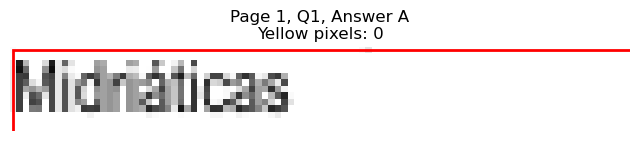

Page 1, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=109.5, y1=127.3
Page 1, Q1, B: Yellow pixels: 92
Page 1, Q1, B: Total non-white pixels: 300
Page 1, Q1, B: Yellow percentage: 30.7%


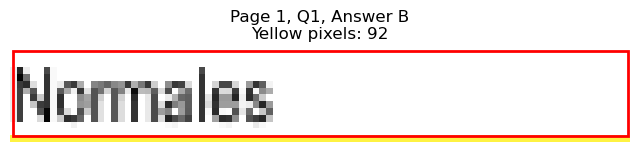

Page 1, Q1 - C: Detected box: x0=68.8, y0=127.2, x1=170.5, y1=139.9
Page 1, Q1, C: Yellow pixels: 1542
Page 1, Q1, C: Total non-white pixels: 1989
Page 1, Q1, C: Yellow percentage: 77.5%


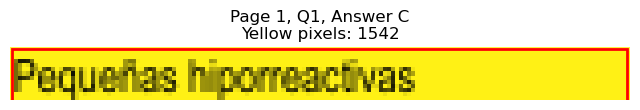

Page 1, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=423.8, y1=114.7
Page 1, Q1, D: Yellow pixels: 0
Page 1, Q1, D: Total non-white pixels: 507
Page 1, Q1, D: Yellow percentage: 0.0%


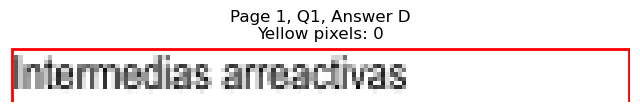

Page 1, Q1 - E: Detected box: x0=327.0, y0=114.6, x1=428.8, y1=127.3
Page 1, Q1, E: Yellow pixels: 0
Page 1, Q1, E: Total non-white pixels: 552
Page 1, Q1, E: Yellow percentage: 0.0%


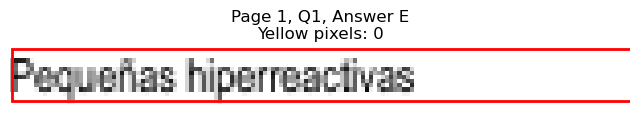


Page 1, Q1 - Selected Answer: C (based on yellow pixel count)




Page 1, Q2 - A: Detected box: x0=68.3, y0=190.3, x1=161.7, y1=203.0
Page 1, Q2, A: Yellow pixels: 0
Page 1, Q2, A: Total non-white pixels: 459
Page 1, Q2, A: Yellow percentage: 0.0%


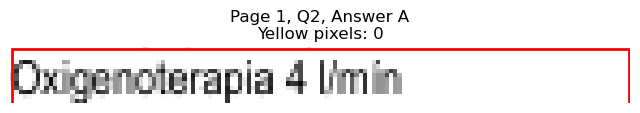

Page 1, Q2 - B: Detected box: x0=68.3, y0=202.9, x1=164.1, y1=215.6
Page 1, Q2, B: Yellow pixels: 0
Page 1, Q2, B: Total non-white pixels: 477
Page 1, Q2, B: Yellow percentage: 0.0%


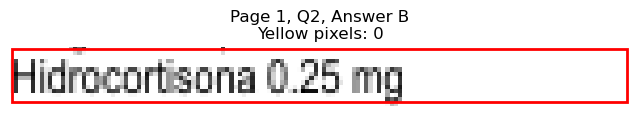

Page 1, Q2 - C: Detected box: x0=68.8, y0=215.7, x1=183.1, y1=228.3
Page 1, Q2, C: Yellow pixels: 0
Page 1, Q2, C: Total non-white pixels: 618
Page 1, Q2, C: Yellow percentage: 0.0%


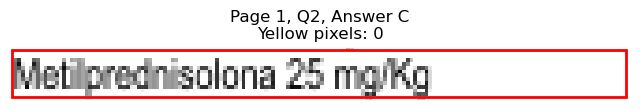

Page 1, Q2 - D: Detected box: x0=327.5, y0=190.3, x1=443.3, y1=203.0
Page 1, Q2, D: Yellow pixels: 0
Page 1, Q2, D: Total non-white pixels: 722
Page 1, Q2, D: Yellow percentage: 0.0%


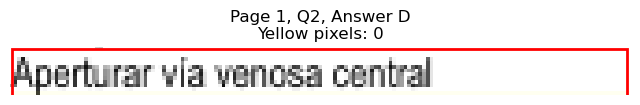

Page 1, Q2 - E: Detected box: x0=327.0, y0=202.9, x1=426.5, y1=215.6
Page 1, Q2, E: Yellow pixels: 1552
Page 1, Q2, E: Total non-white pixels: 2100
Page 1, Q2, E: Yellow percentage: 73.9%


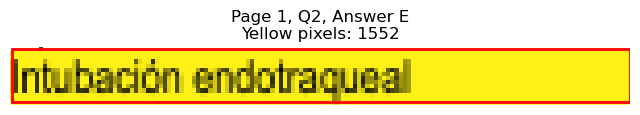


Page 1, Q2 - Selected Answer: E (based on yellow pixel count)




Page 1, Q3 - A: Detected box: x0=68.3, y0=266.1, x1=155.1, y1=278.7
Page 1, Q3, A: Yellow pixels: 0
Page 1, Q3, A: Total non-white pixels: 461
Page 1, Q3, A: Yellow percentage: 0.0%


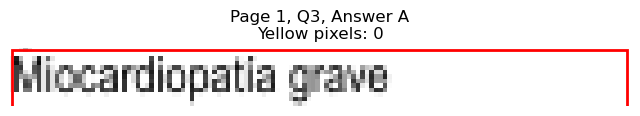

Page 1, Q3 - B: Detected box: x0=68.3, y0=278.8, x1=209.8, y1=291.5
Page 1, Q3, B: Yellow pixels: 1929
Page 1, Q3, B: Total non-white pixels: 2688
Page 1, Q3, B: Yellow percentage: 71.8%


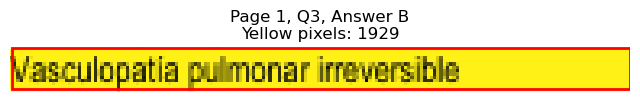

Page 1, Q3 - C: Detected box: x0=68.8, y0=291.4, x1=154.6, y1=304.1
Page 1, Q3, C: Yellow pixels: 137
Page 1, Q3, C: Total non-white pixels: 566
Page 1, Q3, C: Yellow percentage: 24.2%


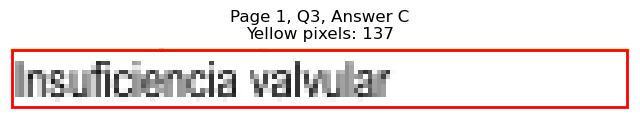

Page 1, Q3 - D: Detected box: x0=327.5, y0=266.1, x1=451.4, y1=278.7
Page 1, Q3, D: Yellow pixels: 0
Page 1, Q3, D: Total non-white pixels: 651
Page 1, Q3, D: Yellow percentage: 0.0%


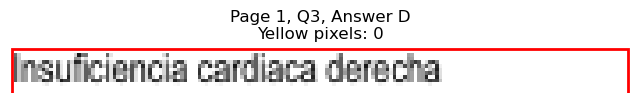

Page 1, Q3 - E: Detected box: x0=327.0, y0=278.8, x1=402.3, y1=291.5
Page 1, Q3, E: Yellow pixels: 0
Page 1, Q3, E: Total non-white pixels: 390
Page 1, Q3, E: Yellow percentage: 0.0%


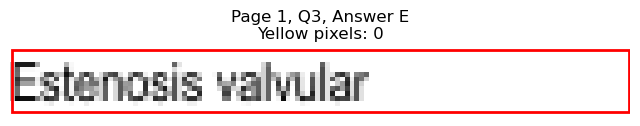


Page 1, Q3 - Selected Answer: B (based on yellow pixel count)




Page 1, Q4 - A: Detected box: x0=68.3, y0=354.5, x1=153.0, y1=367.2
Page 1, Q4, A: Yellow pixels: 0
Page 1, Q4, A: Total non-white pixels: 421
Page 1, Q4, A: Yellow percentage: 0.0%


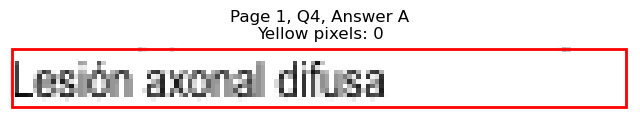

Page 1, Q4 - B: Detected box: x0=68.3, y0=367.1, x1=149.7, y1=379.8
Page 1, Q4, B: Yellow pixels: 0
Page 1, Q4, B: Total non-white pixels: 424
Page 1, Q4, B: Yellow percentage: 0.0%


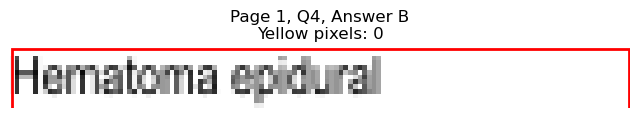

Page 1, Q4 - C: Detected box: x0=68.8, y0=379.7, x1=138.5, y1=392.4
Page 1, Q4, C: Yellow pixels: 0
Page 1, Q4, C: Total non-white pixels: 348
Page 1, Q4, C: Yellow percentage: 0.0%


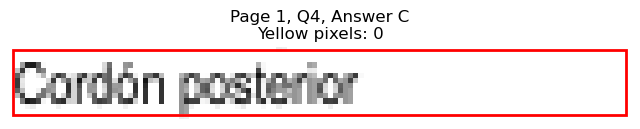

Page 1, Q4 - D: Detected box: x0=327.5, y0=354.5, x1=389.2, y1=367.2
Page 1, Q4, D: Yellow pixels: 113
Page 1, Q4, D: Total non-white pixels: 419
Page 1, Q4, D: Yellow percentage: 27.0%


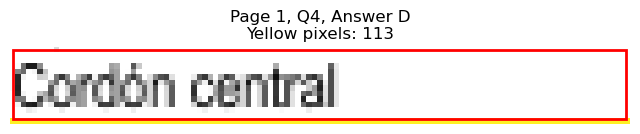

Page 1, Q4 - E: Detected box: x0=327.0, y0=367.1, x1=386.3, y1=379.8
Page 1, Q4, E: Yellow pixels: 1216
Page 1, Q4, E: Total non-white pixels: 1430
Page 1, Q4, E: Yellow percentage: 85.0%


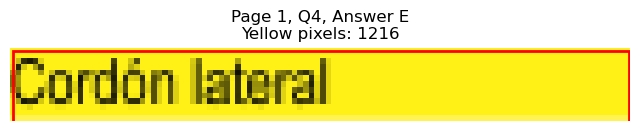


Page 1, Q4 - Selected Answer: E (based on yellow pixel count)




Page 1, Q5 - A: Detected box: x0=68.3, y0=455.5, x1=188.2, y1=468.1
Page 1, Q5, A: Yellow pixels: 1695
Page 1, Q5, A: Total non-white pixels: 2394
Page 1, Q5, A: Yellow percentage: 70.8%


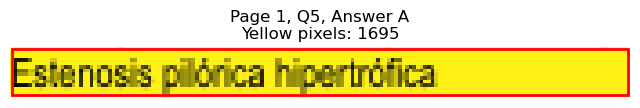

Page 1, Q5 - B: Detected box: x0=68.3, y0=468.1, x1=132.5, y1=480.7
Page 1, Q5, B: Yellow pixels: 0
Page 1, Q5, B: Total non-white pixels: 437
Page 1, Q5, B: Yellow percentage: 0.0%


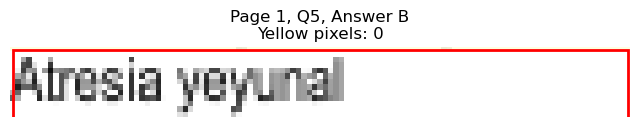

Page 1, Q5 - C: Detected box: x0=68.8, y0=480.8, x1=131.5, y1=493.4
Page 1, Q5, C: Yellow pixels: 0
Page 1, Q5, C: Total non-white pixels: 322
Page 1, Q5, C: Yellow percentage: 0.0%


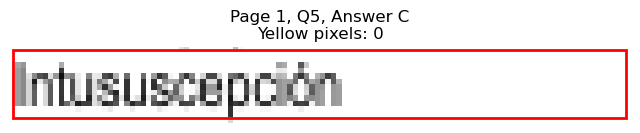

Page 1, Q5 - D: Detected box: x0=327.5, y0=455.5, x1=414.8, y1=468.1
Page 1, Q5, D: Yellow pixels: 0
Page 1, Q5, D: Total non-white pixels: 487
Page 1, Q5, D: Yellow percentage: 0.0%


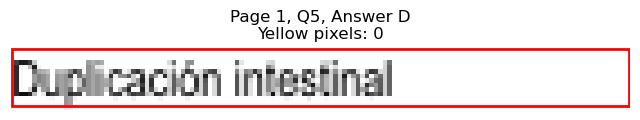

Page 1, Q5 - E: Detected box: x0=327.0, y0=468.1, x1=408.3, y1=480.7
Page 1, Q5, E: Yellow pixels: 0
Page 1, Q5, E: Total non-white pixels: 431
Page 1, Q5, E: Yellow percentage: 0.0%


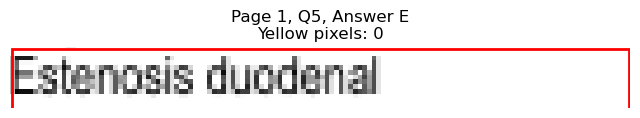


Page 1, Q5 - Selected Answer: A (based on yellow pixel count)




Page 1, Q6 - A: Detected box: x0=68.3, y0=543.8, x1=161.1, y1=556.4
Page 1, Q6, A: Yellow pixels: 0
Page 1, Q6, A: Total non-white pixels: 464
Page 1, Q6, A: Yellow percentage: 0.0%


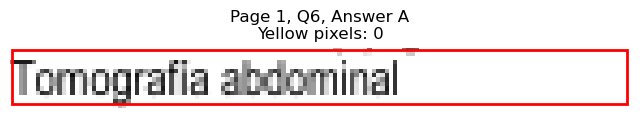

Page 1, Q6 - B: Detected box: x0=68.3, y0=556.5, x1=180.1, y1=569.2
Page 1, Q6, B: Yellow pixels: 163
Page 1, Q6, B: Total non-white pixels: 709
Page 1, Q6, B: Yellow percentage: 23.0%


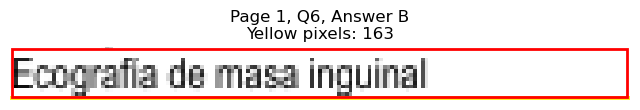

Page 1, Q6 - C: Detected box: x0=68.8, y0=569.1, x1=162.6, y1=581.8
Page 1, Q6, C: Yellow pixels: 1522
Page 1, Q6, C: Total non-white pixels: 1885
Page 1, Q6, C: Yellow percentage: 80.7%


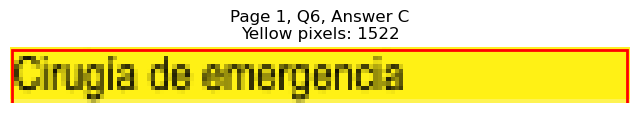

Page 1, Q6 - D: Detected box: x0=327.5, y0=543.8, x1=422.3, y1=556.4
Page 1, Q6, D: Yellow pixels: 0
Page 1, Q6, D: Total non-white pixels: 474
Page 1, Q6, D: Yellow percentage: 0.0%


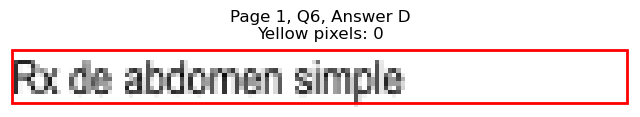

Page 1, Q6 - E: Detected box: x0=327.0, y0=556.5, x1=404.3, y1=569.2
Page 1, Q6, E: Yellow pixels: 0
Page 1, Q6, E: Total non-white pixels: 383
Page 1, Q6, E: Yellow percentage: 0.0%


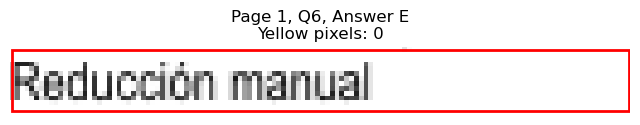


Page 1, Q6 - Selected Answer: C (based on yellow pixel count)




Page 1, Q7 - A: Detected box: x0=68.3, y0=619.6, x1=80.9, y1=632.3
Page 1, Q7, A: Yellow pixels: 710
Page 1, Q7, A: Total non-white pixels: 882
Page 1, Q7, A: Yellow percentage: 80.5%


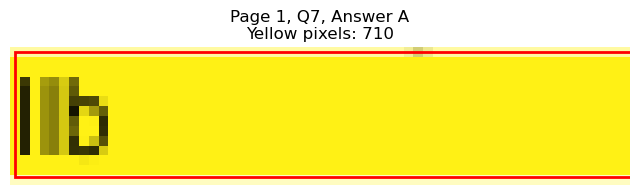

Page 1, Q7 - B: Detected box: x0=56.6, y0=632.2, x1=65.2, y1=644.9
Page 1, Q7, B: Yellow pixels: 0
Page 1, Q7, B: Total non-white pixels: 110
Page 1, Q7, B: Yellow percentage: 0.0%


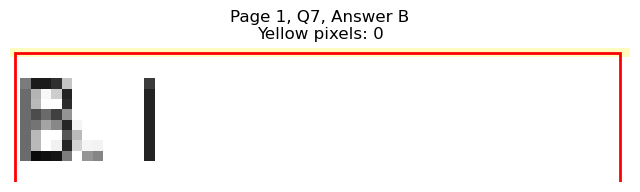

Page 1, Q7 - C: Detected box: x0=68.8, y0=644.9, x1=81.4, y1=657.5
Page 1, Q7, C: Yellow pixels: 0
Page 1, Q7, C: Total non-white pixels: 52
Page 1, Q7, C: Yellow percentage: 0.0%


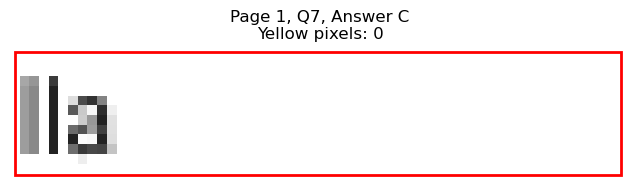

Page 1, Q7 - D: Detected box: x0=327.5, y0=619.6, x1=337.6, y1=632.3
Page 1, Q7, D: Yellow pixels: 0
Page 1, Q7, D: Total non-white pixels: 48
Page 1, Q7, D: Yellow percentage: 0.0%


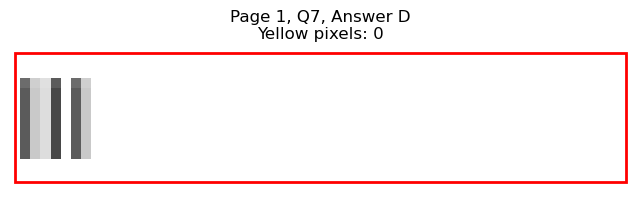

Page 1, Q7 - E: Detected box: x0=327.0, y0=632.2, x1=338.1, y1=644.9
Page 1, Q7, E: Yellow pixels: 0
Page 1, Q7, E: Total non-white pixels: 45
Page 1, Q7, E: Yellow percentage: 0.0%


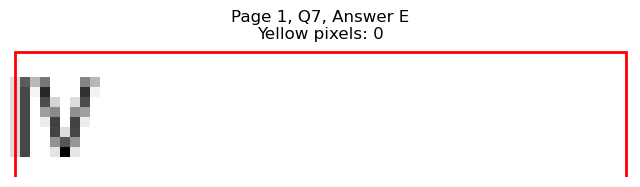


Page 1, Q7 - Selected Answer: A (based on yellow pixel count)




Page 1, Q8 - A: Detected box: x0=68.3, y0=708.0, x1=135.6, y1=720.6
Page 1, Q8, A: Yellow pixels: 1259
Page 1, Q8, A: Total non-white pixels: 1652
Page 1, Q8, A: Yellow percentage: 76.2%


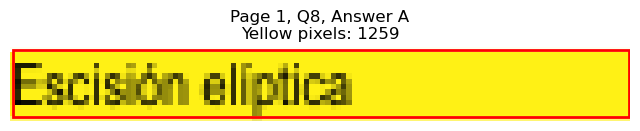

Page 1, Q8 - B: Detected box: x0=68.3, y0=720.6, x1=141.6, y1=733.2
Page 1, Q8, B: Yellow pixels: 124
Page 1, Q8, B: Total non-white pixels: 489
Page 1, Q8, B: Yellow percentage: 25.4%


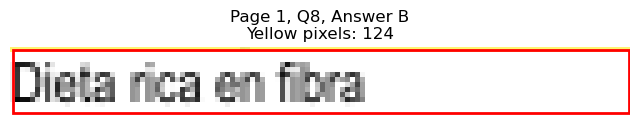

Page 1, Q8 - C: Detected box: x0=68.8, y0=733.2, x1=145.6, y1=745.8
Page 1, Q8, C: Yellow pixels: 0
Page 1, Q8, C: Total non-white pixels: 403
Page 1, Q8, C: Yellow percentage: 0.0%


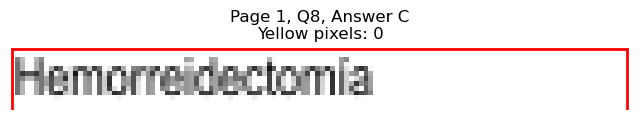

Page 1, Q8 - D: Detected box: x0=327.5, y0=708.0, x1=409.9, y1=720.6
Page 1, Q8, D: Yellow pixels: 0
Page 1, Q8, D: Total non-white pixels: 423
Page 1, Q8, D: Yellow percentage: 0.0%


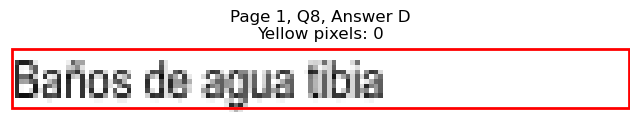

Page 1, Q8 - E: Detected box: x0=327.0, y0=720.6, x1=378.7, y1=733.2
Page 1, Q8, E: Yellow pixels: 0
Page 1, Q8, E: Total non-white pixels: 298
Page 1, Q8, E: Yellow percentage: 0.0%


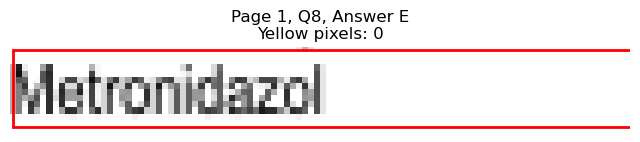


Page 1, Q8 - Selected Answer: A (based on yellow pixel count)





Page 2: Found 9 questions
Page 2, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=150.1, y1=114.7
Page 2, Q1, A: Yellow pixels: 1374
Page 2, Q1, A: Total non-white pixels: 1729
Page 2, Q1, A: Yellow percentage: 79.5%


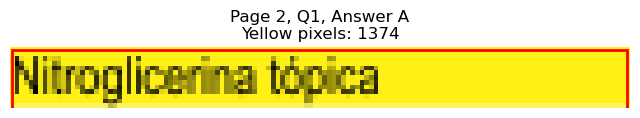

Page 2, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=161.7, y1=127.3
Page 2, Q1, B: Yellow pixels: 142
Page 2, Q1, B: Total non-white pixels: 623
Page 2, Q1, B: Yellow percentage: 22.8%


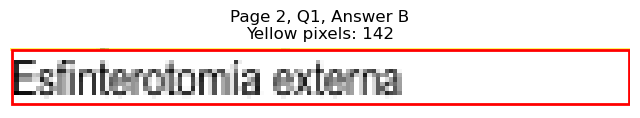

Page 2, Q1 - C: Detected box: x0=68.8, y0=127.2, x1=147.6, y1=139.9
Page 2, Q1, C: Yellow pixels: 0
Page 2, Q1, C: Total non-white pixels: 382
Page 2, Q1, C: Yellow percentage: 0.0%


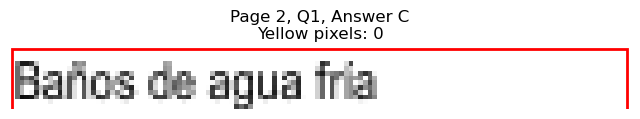

Page 2, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=403.9, y1=114.7
Page 2, Q1, D: Yellow pixels: 0
Page 2, Q1, D: Total non-white pixels: 388
Page 2, Q1, D: Yellow percentage: 0.0%


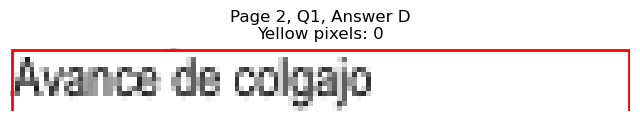

Page 2, Q1 - E: Detected box: x0=327.0, y0=114.6, x1=426.5, y1=127.3
Page 2, Q1, E: Yellow pixels: 0
Page 2, Q1, E: Total non-white pixels: 495
Page 2, Q1, E: Yellow percentage: 0.0%


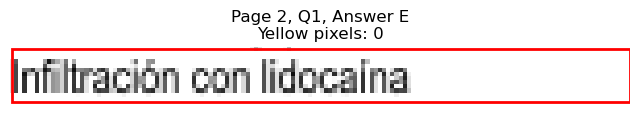


Page 2, Q1 - Selected Answer: A (based on yellow pixel count)




Page 2, Q2 - A: Detected box: x0=68.3, y0=177.7, x1=136.6, y1=190.4
Page 2, Q2, A: Yellow pixels: 0
Page 2, Q2, A: Total non-white pixels: 368
Page 2, Q2, A: Yellow percentage: 0.0%


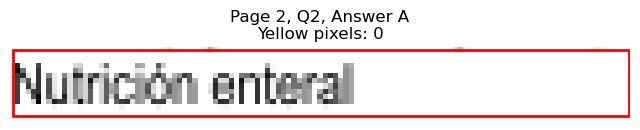

Page 2, Q2 - B: Detected box: x0=68.3, y0=190.3, x1=221.4, y1=203.0
Page 2, Q2, B: Yellow pixels: 0
Page 2, Q2, B: Total non-white pixels: 781
Page 2, Q2, B: Yellow percentage: 0.0%


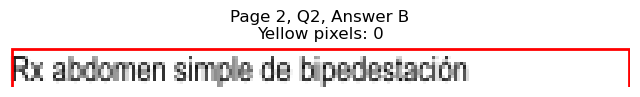

Page 2, Q2 - C: Detected box: x0=68.8, y0=202.9, x1=126.0, y1=215.6
Page 2, Q2, C: Yellow pixels: 0
Page 2, Q2, C: Total non-white pixels: 308
Page 2, Q2, C: Yellow percentage: 0.0%


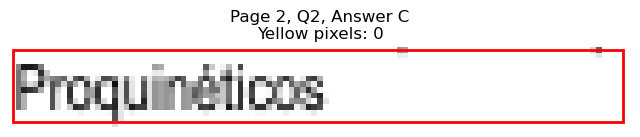

Page 2, Q2 - D: Detected box: x0=327.5, y0=177.7, x1=385.9, y1=190.4
Page 2, Q2, D: Yellow pixels: 1051
Page 2, Q2, D: Total non-white pixels: 1526
Page 2, Q2, D: Yellow percentage: 68.9%


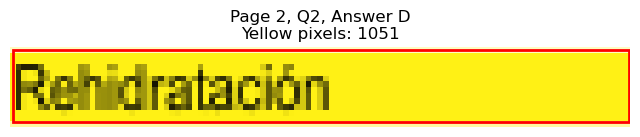

Page 2, Q2 - E: Detected box: x0=327.0, y0=190.3, x1=347.6, y1=203.0
Page 2, Q2, E: Yellow pixels: 0
Page 2, Q2, E: Total non-white pixels: 165
Page 2, Q2, E: Yellow percentage: 0.0%


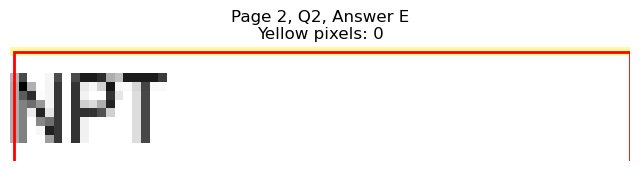


Page 2, Q2 - Selected Answer: D (based on yellow pixel count)




Page 2, Q3 - A: Detected box: x0=68.3, y0=253.5, x1=179.2, y1=266.1
Page 2, Q3, A: Yellow pixels: 1677
Page 2, Q3, A: Total non-white pixels: 2268
Page 2, Q3, A: Yellow percentage: 73.9%


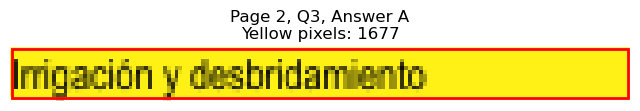

Page 2, Q3 - B: Detected box: x0=68.3, y0=266.1, x1=174.1, y1=278.7
Page 2, Q3, B: Yellow pixels: 0
Page 2, Q3, B: Total non-white pixels: 723
Page 2, Q3, B: Yellow percentage: 0.0%


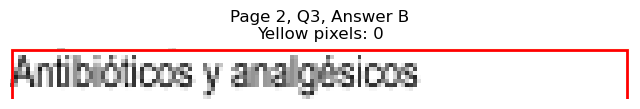

Page 2, Q3 - C: Detected box: x0=68.8, y0=278.8, x1=189.6, y1=291.5
Page 2, Q3, C: Yellow pixels: 0
Page 2, Q3, C: Total non-white pixels: 618
Page 2, Q3, C: Yellow percentage: 0.0%


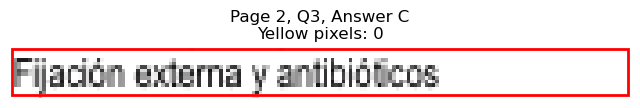

Page 2, Q3 - D: Detected box: x0=327.5, y0=253.5, x1=400.9, y1=266.1
Page 2, Q3, D: Yellow pixels: 0
Page 2, Q3, D: Total non-white pixels: 355
Page 2, Q3, D: Yellow percentage: 0.0%


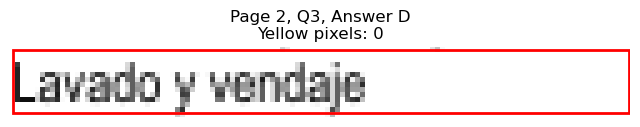

Page 2, Q3 - E: Detected box: x0=327.0, y0=266.1, x1=473.1, y1=278.7
Page 2, Q3, E: Yellow pixels: 0
Page 2, Q3, E: Total non-white pixels: 750
Page 2, Q3, E: Yellow percentage: 0.0%


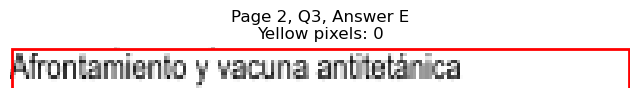


Page 2, Q3 - Selected Answer: A (based on yellow pixel count)




Page 2, Q4 - A: Detected box: x0=68.3, y0=354.5, x1=139.6, y1=367.2
Page 2, Q4, A: Yellow pixels: 1327
Page 2, Q4, A: Total non-white pixels: 1708
Page 2, Q4, A: Yellow percentage: 77.7%


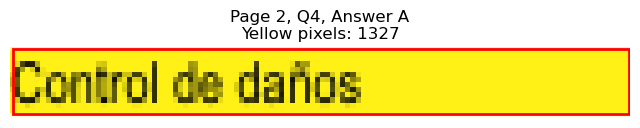

Page 2, Q4 - B: Detected box: x0=68.3, y0=367.1, x1=171.3, y1=379.8
Page 2, Q4, B: Yellow pixels: 0
Page 2, Q4, B: Total non-white pixels: 728
Page 2, Q4, B: Yellow percentage: 0.0%


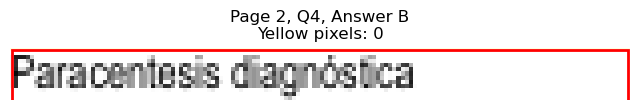

Page 2, Q4 - C: Detected box: x0=68.8, y0=379.7, x1=158.7, y1=392.4
Page 2, Q4, C: Yellow pixels: 0
Page 2, Q4, C: Total non-white pixels: 433
Page 2, Q4, C: Yellow percentage: 0.0%


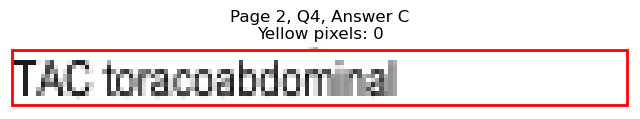

Page 2, Q4 - D: Detected box: x0=327.5, y0=354.5, x1=422.0, y1=367.2
Page 2, Q4, D: Yellow pixels: 0
Page 2, Q4, D: Total non-white pixels: 492
Page 2, Q4, D: Yellow percentage: 0.0%


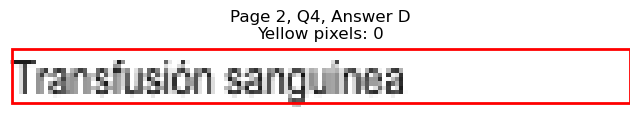

Page 2, Q4 - E: Detected box: x0=327.0, y0=367.1, x1=449.5, y1=379.8
Page 2, Q4, E: Yellow pixels: 0
Page 2, Q4, E: Total non-white pixels: 629
Page 2, Q4, E: Yellow percentage: 0.0%


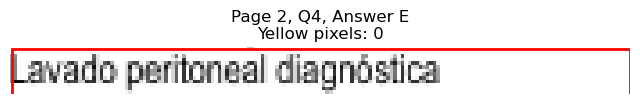


Page 2, Q4 - Selected Answer: A (based on yellow pixel count)




Page 2, Q5 - A: Detected box: x0=68.3, y0=417.6, x1=158.5, y1=430.3
Page 2, Q5, A: Yellow pixels: 0
Page 2, Q5, A: Total non-white pixels: 485
Page 2, Q5, A: Yellow percentage: 0.0%


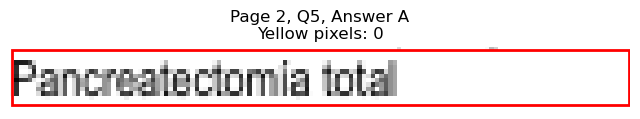

Page 2, Q5 - B: Detected box: x0=68.3, y0=430.2, x1=162.6, y1=442.9
Page 2, Q5, B: Yellow pixels: 0
Page 2, Q5, B: Total non-white pixels: 509
Page 2, Q5, B: Yellow percentage: 0.0%


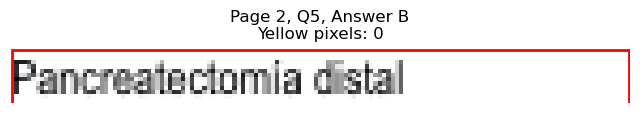

Page 2, Q5 - C: Detected box: x0=68.8, y0=442.8, x1=150.5, y1=455.5
Page 2, Q5, C: Yellow pixels: 0
Page 2, Q5, C: Total non-white pixels: 418
Page 2, Q5, C: Yellow percentage: 0.0%


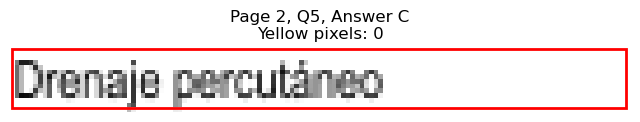

Page 2, Q5 - D: Detected box: x0=327.5, y0=417.6, x1=440.3, y1=430.3
Page 2, Q5, D: Yellow pixels: 1521
Page 2, Q5, D: Total non-white pixels: 2296
Page 2, Q5, D: Yellow percentage: 66.2%


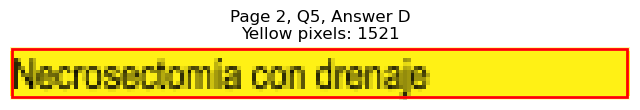

Page 2, Q5 - E: Detected box: x0=327.0, y0=430.2, x1=426.9, y1=442.9
Page 2, Q5, E: Yellow pixels: 0
Page 2, Q5, E: Total non-white pixels: 660
Page 2, Q5, E: Yellow percentage: 0.0%


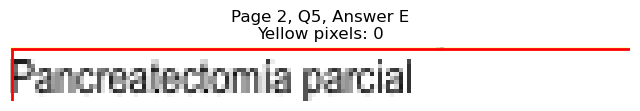


Page 2, Q5 - Selected Answer: D (based on yellow pixel count)




Page 2, Q6 - A: Detected box: x0=68.3, y0=480.8, x1=136.0, y1=493.4
Page 2, Q6, A: Yellow pixels: 0
Page 2, Q6, A: Total non-white pixels: 343
Page 2, Q6, A: Yellow percentage: 0.0%


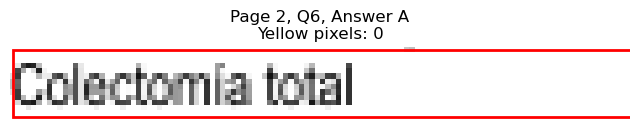

Page 2, Q6 - B: Detected box: x0=68.3, y0=493.4, x1=213.8, y1=506.0
Page 2, Q6, B: Yellow pixels: 0
Page 2, Q6, B: Total non-white pixels: 771
Page 2, Q6, B: Yellow percentage: 0.0%


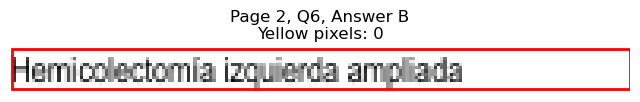

Page 2, Q6 - C: Detected box: x0=68.8, y0=506.0, x1=175.1, y1=518.6
Page 2, Q6, C: Yellow pixels: 0
Page 2, Q6, C: Total non-white pixels: 545
Page 2, Q6, C: Yellow percentage: 0.0%


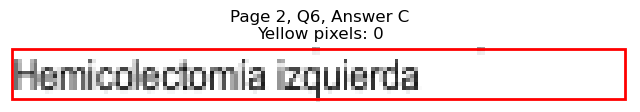

Page 2, Q6 - D: Detected box: x0=327.5, y0=480.8, x1=467.5, y1=493.4
Page 2, Q6, D: Yellow pixels: 191
Page 2, Q6, D: Total non-white pixels: 913
Page 2, Q6, D: Yellow percentage: 20.9%


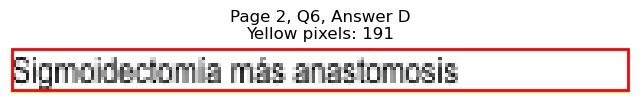

Page 2, Q6 - E: Detected box: x0=327.0, y0=493.4, x1=425.8, y1=506.0
Page 2, Q6, E: Yellow pixels: 1546
Page 2, Q6, E: Total non-white pixels: 1939
Page 2, Q6, E: Yellow percentage: 79.7%


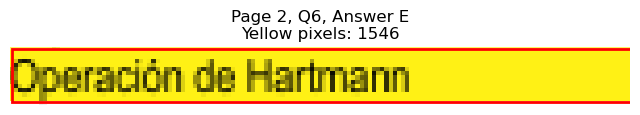


Page 2, Q6 - Selected Answer: E (based on yellow pixel count)




Page 2, Q7 - A: Detected box: x0=68.3, y0=543.8, x1=124.5, y1=556.4
Page 2, Q7, A: Yellow pixels: 0
Page 2, Q7, A: Total non-white pixels: 272
Page 2, Q7, A: Yellow percentage: 0.0%


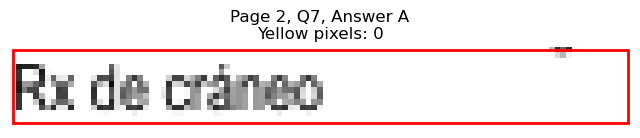

Page 2, Q7 - B: Detected box: x0=68.3, y0=556.5, x1=169.6, y1=569.2
Page 2, Q7, B: Yellow pixels: 1598
Page 2, Q7, B: Total non-white pixels: 2128
Page 2, Q7, B: Yellow percentage: 75.1%


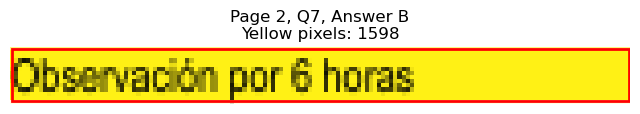

Page 2, Q7 - C: Detected box: x0=68.8, y0=569.1, x1=124.5, y1=581.8
Page 2, Q7, C: Yellow pixels: 0
Page 2, Q7, C: Total non-white pixels: 371
Page 2, Q7, C: Yellow percentage: 0.0%


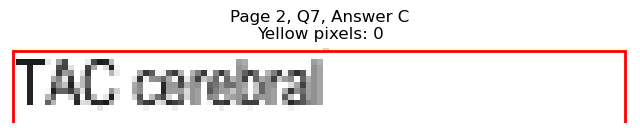

Page 2, Q7 - D: Detected box: x0=327.5, y0=543.8, x1=433.9, y1=556.4
Page 2, Q7, D: Yellow pixels: 0
Page 2, Q7, D: Total non-white pixels: 502
Page 2, Q7, D: Yellow percentage: 0.0%


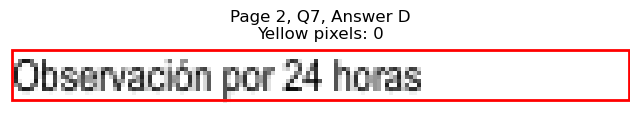

Page 2, Q7 - E: Detected box: x0=327.0, y0=556.5, x1=431.8, y1=569.2
Page 2, Q7, E: Yellow pixels: 0
Page 2, Q7, E: Total non-white pixels: 521
Page 2, Q7, E: Yellow percentage: 0.0%


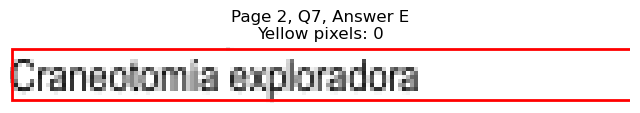


Page 2, Q7 - Selected Answer: B (based on yellow pixel count)




Page 2, Q8 - A: Detected box: x0=68.3, y0=632.2, x1=139.0, y1=644.9
Page 2, Q8, A: Yellow pixels: 0
Page 2, Q8, A: Total non-white pixels: 329
Page 2, Q8, A: Yellow percentage: 0.0%


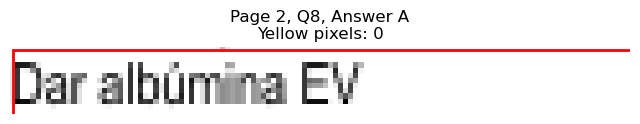

Page 2, Q8 - B: Detected box: x0=68.3, y0=644.9, x1=167.2, y1=657.5
Page 2, Q8, B: Yellow pixels: 0
Page 2, Q8, B: Total non-white pixels: 499
Page 2, Q8, B: Yellow percentage: 0.0%


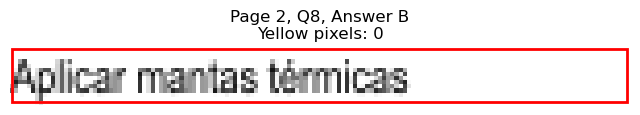

Page 2, Q8 - C: Detected box: x0=68.8, y0=657.5, x1=178.2, y1=670.1
Page 2, Q8, C: Yellow pixels: 0
Page 2, Q8, C: Total non-white pixels: 566
Page 2, Q8, C: Yellow percentage: 0.0%


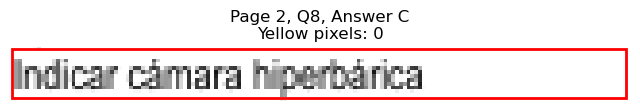

Page 2, Q8 - D: Detected box: x0=327.5, y0=632.2, x1=399.4, y1=644.9
Page 2, Q8, D: Yellow pixels: 1308
Page 2, Q8, D: Total non-white pixels: 1599
Page 2, Q8, D: Yellow percentage: 81.8%


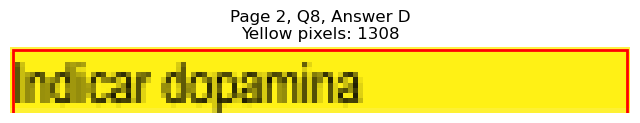

Page 2, Q8 - E: Detected box: x0=327.0, y0=644.9, x1=431.0, y1=657.5
Page 2, Q8, E: Yellow pixels: 0
Page 2, Q8, E: Total non-white pixels: 537
Page 2, Q8, E: Yellow percentage: 0.0%


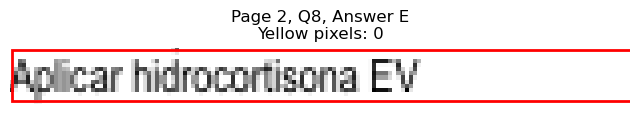


Page 2, Q8 - Selected Answer: D (based on yellow pixel count)




Page 2, Q9 - A: Detected box: x0=68.3, y0=720.6, x1=152.1, y1=733.2
Page 2, Q9, A: Yellow pixels: 135
Page 2, Q9, A: Total non-white pixels: 540
Page 2, Q9, A: Yellow percentage: 25.0%


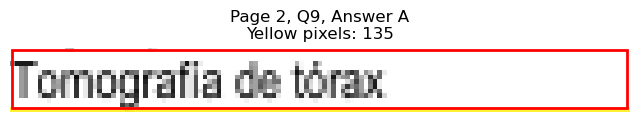

Page 2, Q9 - B: Detected box: x0=68.3, y0=733.2, x1=173.2, y1=745.8
Page 2, Q9, B: Yellow pixels: 1632
Page 2, Q9, B: Total non-white pixels: 2028
Page 2, Q9, B: Yellow percentage: 80.5%


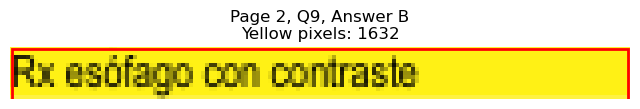

Page 2, Q9 - C: Detected box: x0=68.8, y0=745.8, x1=146.1, y1=758.4
Page 2, Q9, C: Yellow pixels: 128
Page 2, Q9, C: Total non-white pixels: 502
Page 2, Q9, C: Yellow percentage: 25.5%


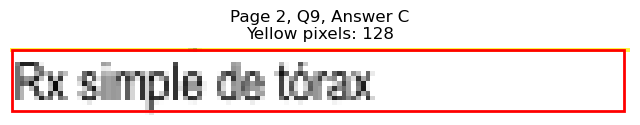

Page 2, Q9 - D: Detected box: x0=327.5, y0=720.6, x1=400.3, y1=733.2
Page 2, Q9, D: Yellow pixels: 0
Page 2, Q9, D: Total non-white pixels: 397
Page 2, Q9, D: Yellow percentage: 0.0%


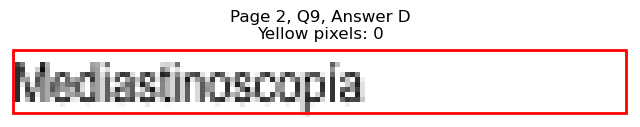

Page 2, Q9 - E: Detected box: x0=327.0, y0=733.2, x1=381.9, y1=745.8
Page 2, Q9, E: Yellow pixels: 0
Page 2, Q9, E: Total non-white pixels: 274
Page 2, Q9, E: Yellow percentage: 0.0%


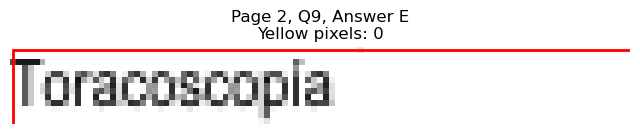


Page 2, Q9 - Selected Answer: B (based on yellow pixel count)





Page 3: Found 8 questions
Page 3, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=155.5, y1=102.1
Page 3, Q1, A: Yellow pixels: 138
Page 3, Q1, A: Total non-white pixels: 577
Page 3, Q1, A: Yellow percentage: 23.9%


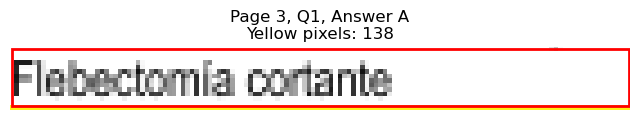

Page 3, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=180.3, y1=114.7
Page 3, Q1, B: Yellow pixels: 1675
Page 3, Q1, B: Total non-white pixels: 2119
Page 3, Q1, B: Yellow percentage: 79.0%


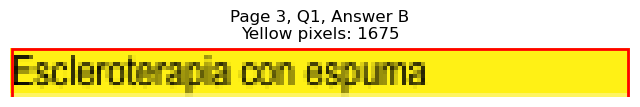

Page 3, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=179.7, y1=127.3
Page 3, Q1, C: Yellow pixels: 162
Page 3, Q1, C: Total non-white pixels: 684
Page 3, Q1, C: Yellow percentage: 23.7%


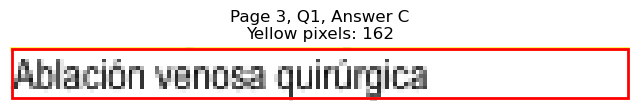

Page 3, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=426.4, y1=102.1
Page 3, Q1, D: Yellow pixels: 0
Page 3, Q1, D: Total non-white pixels: 534
Page 3, Q1, D: Yellow percentage: 0.0%


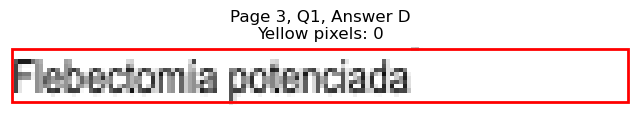

Page 3, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=444.4, y1=114.7
Page 3, Q1, E: Yellow pixels: 0
Page 3, Q1, E: Total non-white pixels: 605
Page 3, Q1, E: Yellow percentage: 0.0%


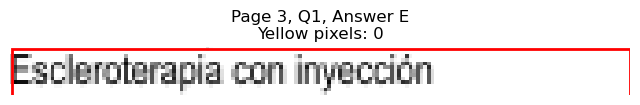


Page 3, Q1 - Selected Answer: B (based on yellow pixel count)




Page 3, Q2 - A: Detected box: x0=68.3, y0=177.7, x1=157.8, y1=190.4
Page 3, Q2, A: Yellow pixels: 0
Page 3, Q2, A: Total non-white pixels: 440
Page 3, Q2, A: Yellow percentage: 0.0%


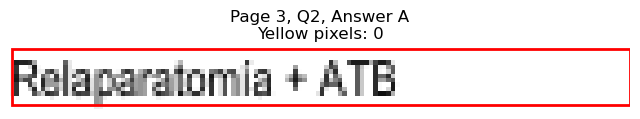

Page 3, Q2 - B: Detected box: x0=68.3, y0=190.3, x1=164.3, y1=203.0
Page 3, Q2, B: Yellow pixels: 0
Page 3, Q2, B: Total non-white pixels: 470
Page 3, Q2, B: Yellow percentage: 0.0%


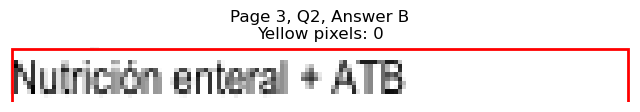

Page 3, Q2 - C: Detected box: x0=68.8, y0=202.9, x1=117.1, y1=215.6
Page 3, Q2, C: Yellow pixels: 0
Page 3, Q2, C: Total non-white pixels: 205
Page 3, Q2, C: Yellow percentage: 0.0%


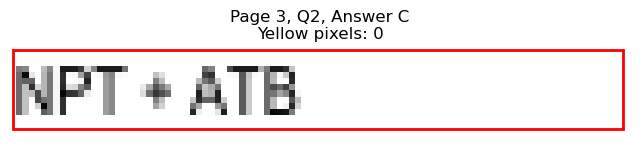

Page 3, Q2 - D: Detected box: x0=327.5, y0=177.7, x1=426.4, y1=190.4
Page 3, Q2, D: Yellow pixels: 150
Page 3, Q2, D: Total non-white pixels: 656
Page 3, Q2, D: Yellow percentage: 22.9%


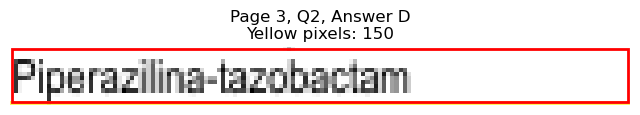

Page 3, Q2 - E: Detected box: x0=327.0, y0=190.3, x1=436.6, y1=203.0
Page 3, Q2, E: Yellow pixels: 1678
Page 3, Q2, E: Total non-white pixels: 2080
Page 3, Q2, E: Yellow percentage: 80.7%


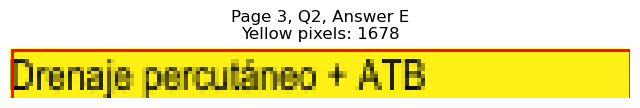


Page 3, Q2 - Selected Answer: E (based on yellow pixel count)




Page 3, Q3 - A: Detected box: x0=68.3, y0=240.9, x1=136.6, y1=253.5
Page 3, Q3, A: Yellow pixels: 0
Page 3, Q3, A: Total non-white pixels: 359
Page 3, Q3, A: Yellow percentage: 0.0%


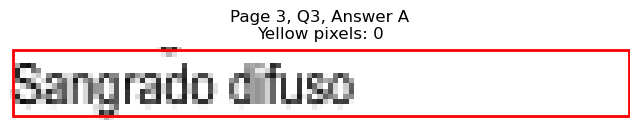

Page 3, Q3 - B: Detected box: x0=68.3, y0=253.5, x1=172.1, y1=266.1
Page 3, Q3, B: Yellow pixels: 0
Page 3, Q3, B: Total non-white pixels: 503
Page 3, Q3, B: Yellow percentage: 0.0%


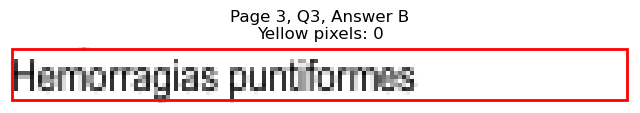

Page 3, Q3 - C: Detected box: x0=68.8, y0=266.1, x1=151.6, y1=278.7
Page 3, Q3, C: Yellow pixels: 0
Page 3, Q3, C: Total non-white pixels: 419
Page 3, Q3, C: Yellow percentage: 0.0%


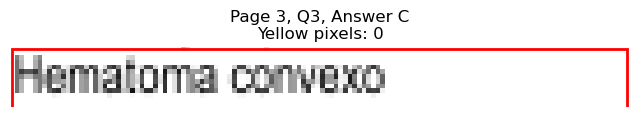

Page 3, Q3 - D: Detected box: x0=327.5, y0=240.9, x1=435.9, y1=253.5
Page 3, Q3, D: Yellow pixels: 159
Page 3, Q3, D: Total non-white pixels: 707
Page 3, Q3, D: Yellow percentage: 22.5%


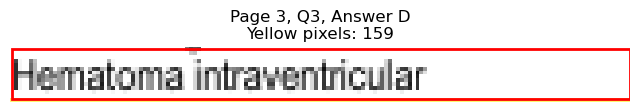

Page 3, Q3 - E: Detected box: x0=327.0, y0=253.5, x1=409.9, y1=266.1
Page 3, Q3, E: Yellow pixels: 1422
Page 3, Q3, E: Total non-white pixels: 1862
Page 3, Q3, E: Yellow percentage: 76.4%


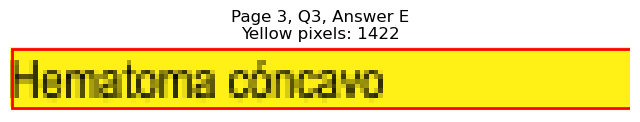


Page 3, Q3 - Selected Answer: E (based on yellow pixel count)




Page 3, Q4 - A: Detected box: x0=68.3, y0=329.2, x1=150.6, y1=341.9
Page 3, Q4, A: Yellow pixels: 0
Page 3, Q4, A: Total non-white pixels: 418
Page 3, Q4, A: Yellow percentage: 0.0%


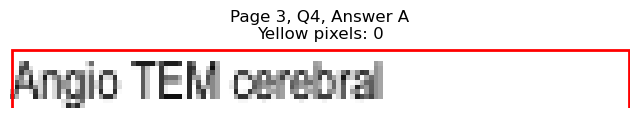

Page 3, Q4 - B: Detected box: x0=68.3, y0=341.9, x1=158.7, y1=354.6
Page 3, Q4, B: Yellow pixels: 0
Page 3, Q4, B: Total non-white pixels: 453
Page 3, Q4, B: Yellow percentage: 0.0%


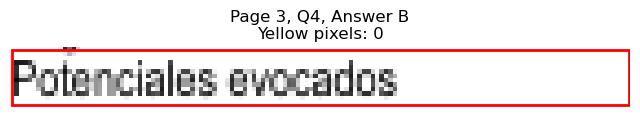

Page 3, Q4 - C: Detected box: x0=68.8, y0=354.5, x1=183.6, y1=367.2
Page 3, Q4, C: Yellow pixels: 0
Page 3, Q4, C: Total non-white pixels: 553
Page 3, Q4, C: Yellow percentage: 0.0%


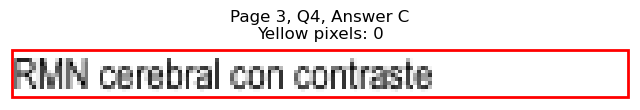

Page 3, Q4 - D: Detected box: x0=327.5, y0=329.2, x1=432.9, y1=341.9
Page 3, Q4, D: Yellow pixels: 0
Page 3, Q4, D: Total non-white pixels: 507
Page 3, Q4, D: Yellow percentage: 0.0%


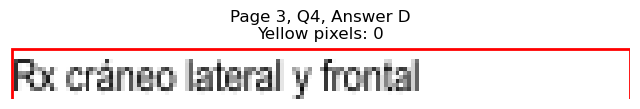

Page 3, Q4 - E: Detected box: x0=327.0, y0=341.9, x1=436.5, y1=354.6
Page 3, Q4, E: Yellow pixels: 1662
Page 3, Q4, E: Total non-white pixels: 2240
Page 3, Q4, E: Yellow percentage: 74.2%


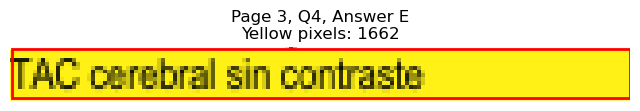


Page 3, Q4 - Selected Answer: E (based on yellow pixel count)




Page 3, Q5 - A: Detected box: x0=68.3, y0=430.2, x1=220.8, y1=442.9
Page 3, Q5, A: Yellow pixels: 0
Page 3, Q5, A: Total non-white pixels: 732
Page 3, Q5, A: Yellow percentage: 0.0%


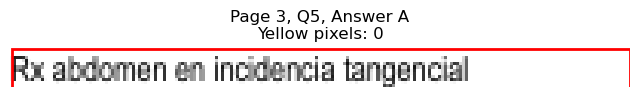

Page 3, Q5 - B: Detected box: x0=68.3, y0=442.8, x1=167.7, y1=455.5
Page 3, Q5, B: Yellow pixels: 0
Page 3, Q5, B: Total non-white pixels: 491
Page 3, Q5, B: Yellow percentage: 0.0%


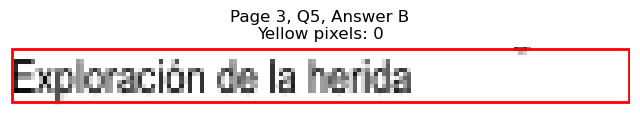

Page 3, Q5 - C: Detected box: x0=68.8, y0=455.5, x1=174.3, y1=468.1
Page 3, Q5, C: Yellow pixels: 0
Page 3, Q5, C: Total non-white pixels: 574
Page 3, Q5, C: Yellow percentage: 0.0%


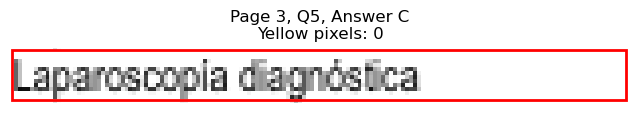

Page 3, Q5 - D: Detected box: x0=327.5, y0=430.2, x1=486.2, y1=442.9
Page 3, Q5, D: Yellow pixels: 0
Page 3, Q5, D: Total non-white pixels: 991
Page 3, Q5, D: Yellow percentage: 0.0%


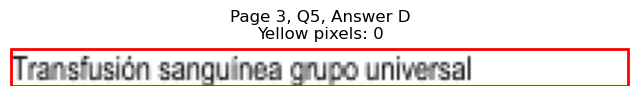

Page 3, Q5 - E: Detected box: x0=327.0, y0=442.8, x1=430.0, y1=455.5
Page 3, Q5, E: Yellow pixels: 1583
Page 3, Q5, E: Total non-white pixels: 2156
Page 3, Q5, E: Yellow percentage: 73.4%


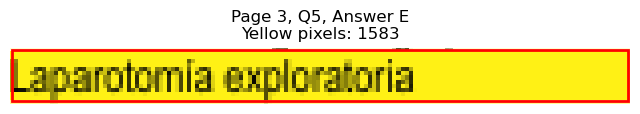


Page 3, Q5 - Selected Answer: E (based on yellow pixel count)




Page 3, Q6 - A: Detected box: x0=68.3, y0=518.6, x1=172.1, y1=531.2
Page 3, Q6, A: Yellow pixels: 0
Page 3, Q6, A: Total non-white pixels: 543
Page 3, Q6, A: Yellow percentage: 0.0%


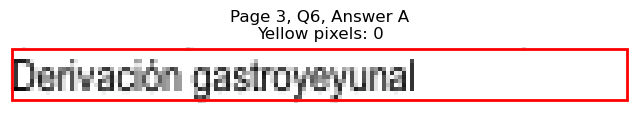

Page 3, Q6 - B: Detected box: x0=68.3, y0=531.2, x1=148.6, y1=543.8
Page 3, Q6, B: Yellow pixels: 0
Page 3, Q6, B: Total non-white pixels: 569
Page 3, Q6, B: Yellow percentage: 0.0%


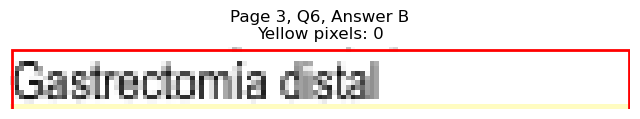

Page 3, Q6 - C: Detected box: x0=68.8, y0=543.8, x1=121.9, y1=556.4
Page 3, Q6, C: Yellow pixels: 1152
Page 3, Q6, C: Total non-white pixels: 1456
Page 3, Q6, C: Yellow percentage: 79.1%


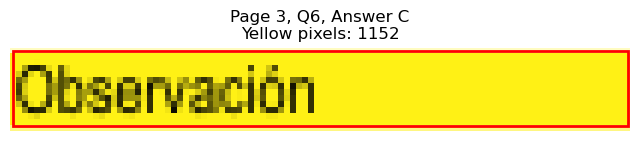

Page 3, Q6 - D: Detected box: x0=327.5, y0=518.6, x1=509.1, y1=531.2
Page 3, Q6, D: Yellow pixels: 0
Page 3, Q6, D: Total non-white pixels: 902
Page 3, Q6, D: Yellow percentage: 0.0%


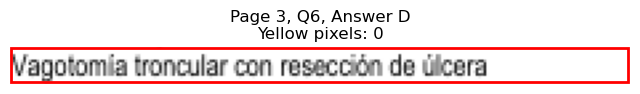

Page 3, Q6 - E: Detected box: x0=327.0, y0=531.2, x1=470.6, y1=543.8
Page 3, Q6, E: Yellow pixels: 0
Page 3, Q6, E: Total non-white pixels: 738
Page 3, Q6, E: Yellow percentage: 0.0%


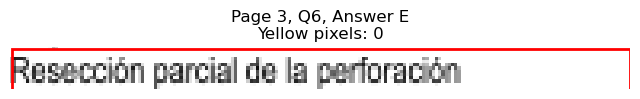


Page 3, Q6 - Selected Answer: C (based on yellow pixel count)




Page 3, Q7 - A: Detected box: x0=56.6, y0=594.3, x1=65.2, y1=607.0
Page 3, Q7, A: Yellow pixels: 0
Page 3, Q7, A: Total non-white pixels: 84
Page 3, Q7, A: Yellow percentage: 0.0%


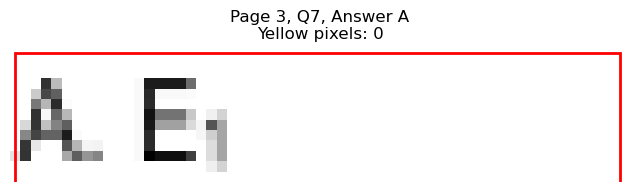

Page 3, Q7 - B: Detected box: x0=56.6, y0=606.9, x1=65.2, y1=619.6
Page 3, Q7, B: Yellow pixels: 0
Page 3, Q7, B: Total non-white pixels: 94
Page 3, Q7, B: Yellow percentage: 0.0%


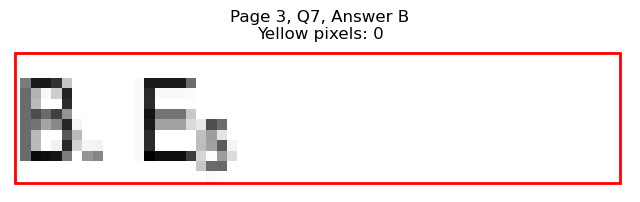

Page 3, Q7 - C: Detected box: x0=56.6, y0=619.6, x1=65.6, y1=632.3
Page 3, Q7, C: Yellow pixels: 0
Page 3, Q7, C: Total non-white pixels: 84
Page 3, Q7, C: Yellow percentage: 0.0%


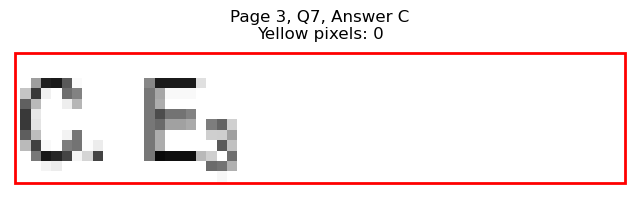

Page 3, Q7 - D: Detected box: x0=315.4, y0=594.3, x1=324.4, y1=607.0
Page 3, Q7, D: Yellow pixels: 0
Page 3, Q7, D: Total non-white pixels: 145
Page 3, Q7, D: Yellow percentage: 0.0%


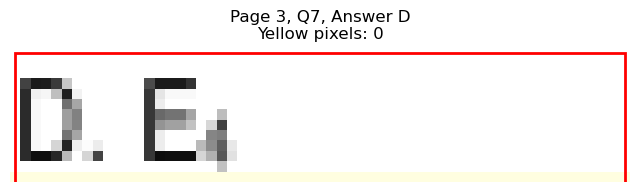

Page 3, Q7 - E: Detected box: x0=315.4, y0=606.9, x1=323.9, y1=619.6
Page 3, Q7, E: Yellow pixels: 700
Page 3, Q7, E: Total non-white pixels: 826
Page 3, Q7, E: Yellow percentage: 84.7%


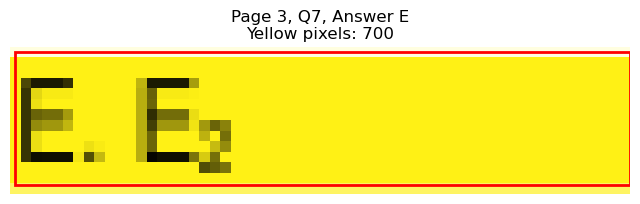


Page 3, Q7 - Selected Answer: E (based on yellow pixel count)




Page 3, Q8 - A: Detected box: x0=68.3, y0=682.7, x1=149.1, y1=695.3
Page 3, Q8, A: Yellow pixels: 0
Page 3, Q8, A: Total non-white pixels: 373
Page 3, Q8, A: Yellow percentage: 0.0%


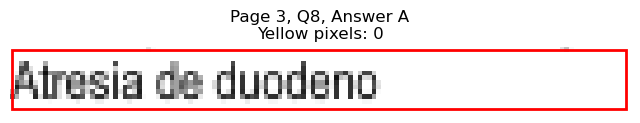

Page 3, Q8 - B: Detected box: x0=68.3, y0=695.4, x1=155.5, y1=708.0
Page 3, Q8, B: Yellow pixels: 1416
Page 3, Q8, B: Total non-white pixels: 1794
Page 3, Q8, B: Yellow percentage: 78.9%


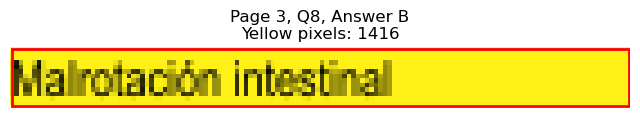

Page 3, Q8 - C: Detected box: x0=68.8, y0=708.0, x1=172.1, y1=720.6
Page 3, Q8, C: Yellow pixels: 155
Page 3, Q8, C: Total non-white pixels: 696
Page 3, Q8, C: Yellow percentage: 22.3%


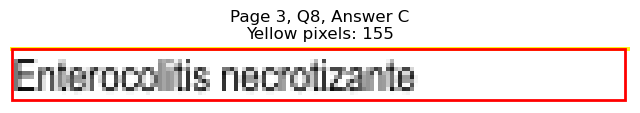

Page 3, Q8 - D: Detected box: x0=327.5, y0=682.7, x1=383.2, y1=695.3
Page 3, Q8, D: Yellow pixels: 0
Page 3, Q8, D: Total non-white pixels: 279
Page 3, Q8, D: Yellow percentage: 0.0%


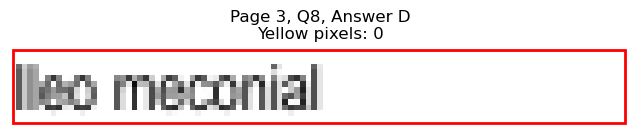

Page 3, Q8 - E: Detected box: x0=327.0, y0=695.4, x1=437.4, y1=708.0
Page 3, Q8, E: Yellow pixels: 0
Page 3, Q8, E: Total non-white pixels: 539
Page 3, Q8, E: Yellow percentage: 0.0%


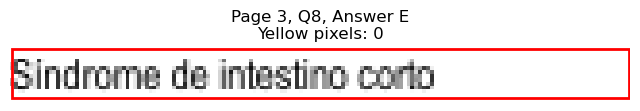


Page 3, Q8 - Selected Answer: B (based on yellow pixel count)





Page 4: Found 8 questions
Page 4, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=93.9, y1=102.1
Page 4, Q1, A: Yellow pixels: 0
Page 4, Q1, A: Total non-white pixels: 84
Page 4, Q1, A: Yellow percentage: 0.0%


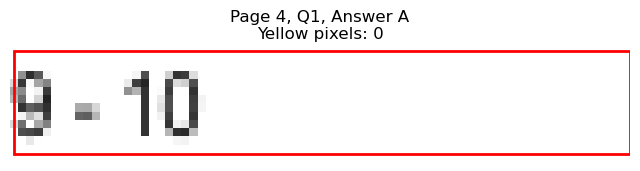

Page 4, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=98.9, y1=114.7
Page 4, Q1, B: Yellow pixels: 0
Page 4, Q1, B: Total non-white pixels: 96
Page 4, Q1, B: Yellow percentage: 0.0%


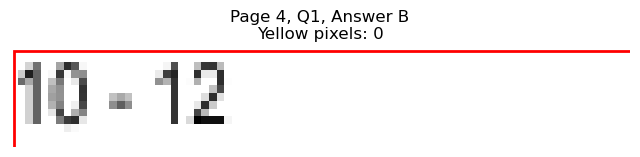

Page 4, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=89.3, y1=127.3
Page 4, Q1, C: Yellow pixels: 0
Page 4, Q1, C: Total non-white pixels: 68
Page 4, Q1, C: Yellow percentage: 0.0%


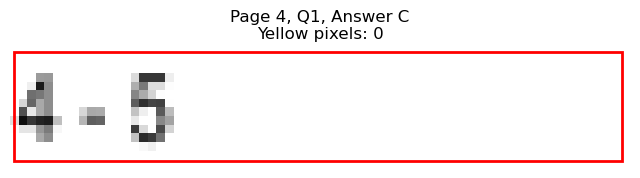

Page 4, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=348.1, y1=102.1
Page 4, Q1, D: Yellow pixels: 72
Page 4, Q1, D: Total non-white pixels: 140
Page 4, Q1, D: Yellow percentage: 51.4%


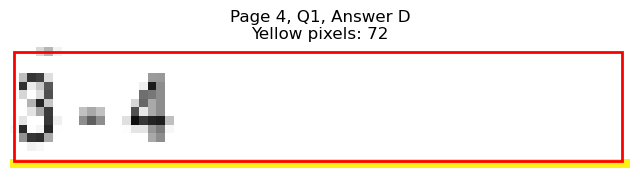

Page 4, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=347.6, y1=114.7
Page 4, Q1, E: Yellow pixels: 864
Page 4, Q1, E: Total non-white pixels: 923
Page 4, Q1, E: Yellow percentage: 93.6%


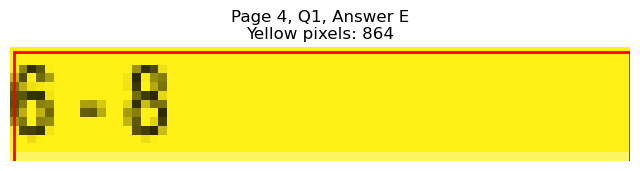


Page 4, Q1 - Selected Answer: E (based on yellow pixel count)




Page 4, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=191.2, y1=177.8
Page 4, Q2, A: Yellow pixels: 0
Page 4, Q2, A: Total non-white pixels: 597
Page 4, Q2, A: Yellow percentage: 0.0%


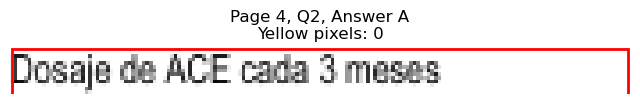

Page 4, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=229.4, y1=190.4
Page 4, Q2, B: Yellow pixels: 0
Page 4, Q2, B: Total non-white pixels: 759
Page 4, Q2, B: Yellow percentage: 0.0%


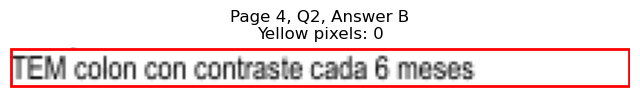

Page 4, Q2 - C: Detected box: x0=68.8, y0=190.3, x1=156.1, y1=203.0
Page 4, Q2, C: Yellow pixels: 0
Page 4, Q2, C: Total non-white pixels: 426
Page 4, Q2, C: Yellow percentage: 0.0%


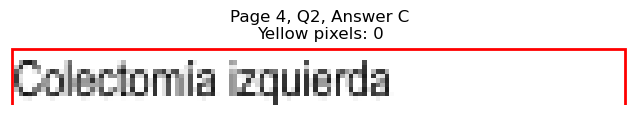

Page 4, Q2 - D: Detected box: x0=327.5, y0=165.1, x1=461.0, y1=177.8
Page 4, Q2, D: Yellow pixels: 1878
Page 4, Q2, D: Total non-white pixels: 2392
Page 4, Q2, D: Yellow percentage: 78.5%


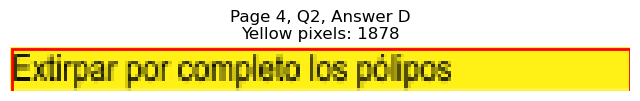

Page 4, Q2 - E: Detected box: x0=327.0, y0=177.7, x1=423.3, y1=190.4
Page 4, Q2, E: Yellow pixels: 147
Page 4, Q2, E: Total non-white pixels: 650
Page 4, Q2, E: Yellow percentage: 22.6%


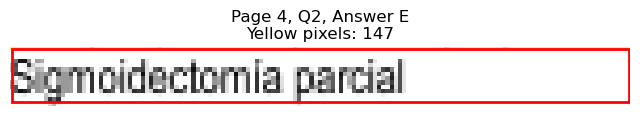


Page 4, Q2 - Selected Answer: D (based on yellow pixel count)




Page 4, Q3 - A: Detected box: x0=68.3, y0=253.5, x1=180.1, y1=266.1
Page 4, Q3, A: Yellow pixels: 163
Page 4, Q3, A: Total non-white pixels: 675
Page 4, Q3, A: Yellow percentage: 24.1%


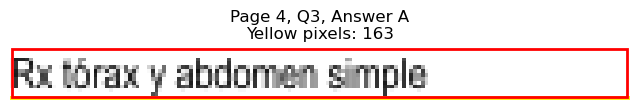

Page 4, Q3 - B: Detected box: x0=68.3, y0=266.1, x1=175.1, y1=278.7
Page 4, Q3, B: Yellow pixels: 1624
Page 4, Q3, B: Total non-white pixels: 2054
Page 4, Q3, B: Yellow percentage: 79.1%


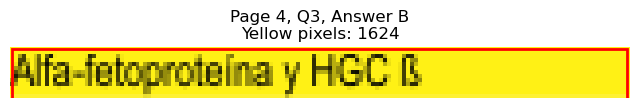

Page 4, Q3 - C: Detected box: x0=68.8, y0=278.8, x1=133.5, y1=291.5
Page 4, Q3, C: Yellow pixels: 115
Page 4, Q3, C: Total non-white pixels: 406
Page 4, Q3, C: Yellow percentage: 28.3%


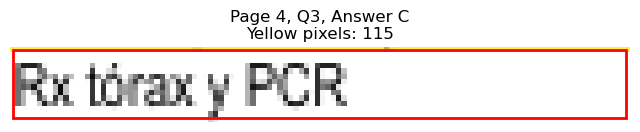

Page 4, Q3 - D: Detected box: x0=327.5, y0=253.5, x1=400.3, y1=266.1
Page 4, Q3, D: Yellow pixels: 0
Page 4, Q3, D: Total non-white pixels: 356
Page 4, Q3, D: Yellow percentage: 0.0%


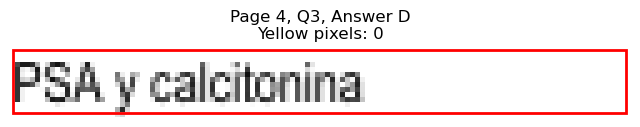

Page 4, Q3 - E: Detected box: x0=327.0, y0=266.1, x1=426.9, y1=278.7
Page 4, Q3, E: Yellow pixels: 0
Page 4, Q3, E: Total non-white pixels: 522
Page 4, Q3, E: Yellow percentage: 0.0%


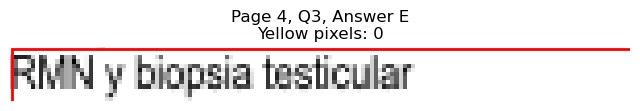


Page 4, Q3 - Selected Answer: B (based on yellow pixel count)




Page 4, Q4 - A: Detected box: x0=68.3, y0=316.6, x1=120.6, y1=329.3
Page 4, Q4, A: Yellow pixels: 0
Page 4, Q4, A: Total non-white pixels: 454
Page 4, Q4, A: Yellow percentage: 0.0%


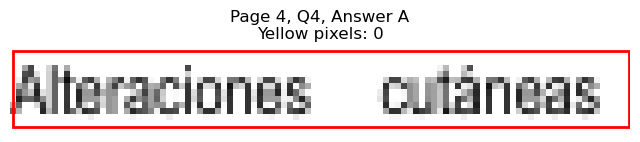

Page 4, Q4 - B: Detected box: x0=68.3, y0=341.9, x1=137.1, y1=354.6
Page 4, Q4, B: Yellow pixels: 0
Page 4, Q4, B: Total non-white pixels: 343
Page 4, Q4, B: Yellow percentage: 0.0%


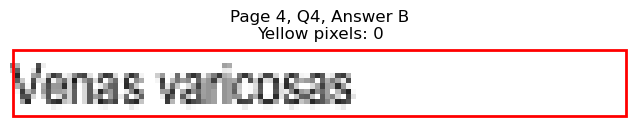

Page 4, Q4 - C: Detected box: x0=68.8, y0=354.5, x1=261.4, y1=367.2
Page 4, Q4, C: Yellow pixels: 0
Page 4, Q4, C: Total non-white pixels: 975
Page 4, Q4, C: Yellow percentage: 0.0%


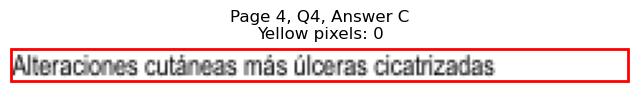

Page 4, Q4 - D: Detected box: x0=327.5, y0=316.6, x1=462.9, y1=329.3
Page 4, Q4, D: Yellow pixels: 1727
Page 4, Q4, D: Total non-white pixels: 2604
Page 4, Q4, D: Yellow percentage: 66.3%


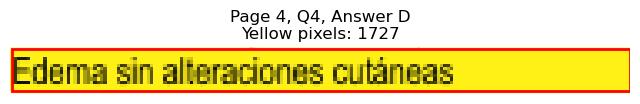

Page 4, Q4 - E: Detected box: x0=327.0, y0=329.2, x1=500.1, y1=341.9
Page 4, Q4, E: Yellow pixels: 0
Page 4, Q4, E: Total non-white pixels: 1095
Page 4, Q4, E: Yellow percentage: 0.0%


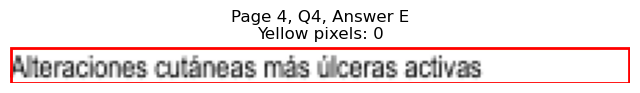


Page 4, Q4 - Selected Answer: D (based on yellow pixel count)




Page 4, Q5 - A: Detected box: x0=68.3, y0=392.3, x1=258.4, y1=405.0
Page 4, Q5, A: Yellow pixels: 0
Page 4, Q5, A: Total non-white pixels: 957
Page 4, Q5, A: Yellow percentage: 0.0%


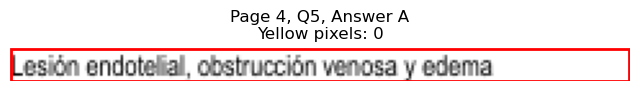

Page 4, Q5 - B: Detected box: x0=158.8, y0=404.9, x1=239.2, y1=417.6
Page 4, Q5, B: Yellow pixels: 0
Page 4, Q5, B: Total non-white pixels: 619
Page 4, Q5, B: Yellow percentage: 0.0%


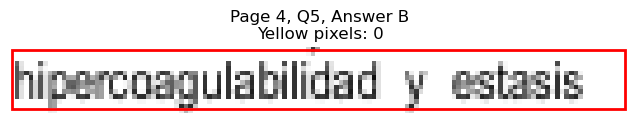

Page 4, Q5 - C: Detected box: x0=151.9, y0=430.2, x1=232.2, y1=442.9
Page 4, Q5, C: Yellow pixels: 1251
Page 4, Q5, C: Total non-white pixels: 1703
Page 4, Q5, C: Yellow percentage: 73.5%


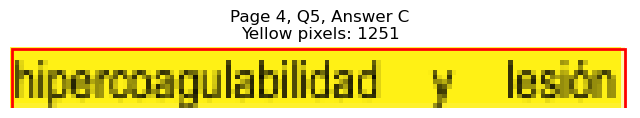

Page 4, Q5 - D: Detected box: x0=327.5, y0=392.3, x1=518.1, y1=405.0
Page 4, Q5, D: Yellow pixels: 0
Page 4, Q5, D: Total non-white pixels: 1006
Page 4, Q5, D: Yellow percentage: 0.0%


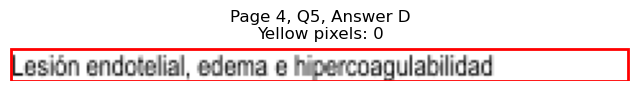

Page 4, Q5 - E: Detected box: x0=327.0, y0=404.9, x1=510.7, y1=417.6
Page 4, Q5, E: Yellow pixels: 0
Page 4, Q5, E: Total non-white pixels: 966
Page 4, Q5, E: Yellow percentage: 0.0%


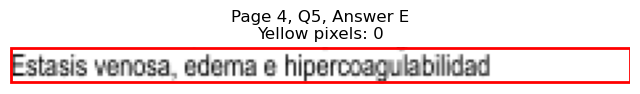


Page 4, Q5 - Selected Answer: C (based on yellow pixel count)




Page 4, Q6 - A: Detected box: x0=68.3, y0=506.0, x1=248.0, y1=518.6
Page 4, Q6, A: Yellow pixels: 2129
Page 4, Q6, A: Total non-white pixels: 2996
Page 4, Q6, A: Yellow percentage: 71.1%


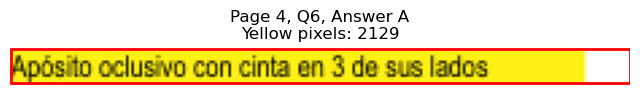

Page 4, Q6 - B: Detected box: x0=68.3, y0=518.6, x1=144.1, y1=531.2
Page 4, Q6, B: Yellow pixels: 127
Page 4, Q6, B: Total non-white pixels: 507
Page 4, Q6, B: Yellow percentage: 25.0%


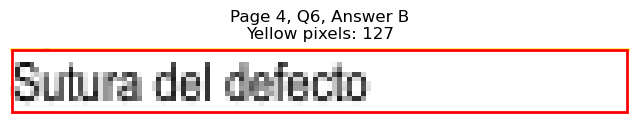

Page 4, Q6 - C: Detected box: x0=68.8, y0=531.2, x1=247.4, y1=543.8
Page 4, Q6, C: Yellow pixels: 0
Page 4, Q6, C: Total non-white pixels: 874
Page 4, Q6, C: Yellow percentage: 0.0%


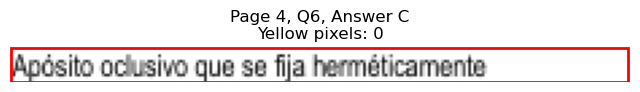

Page 4, Q6 - D: Detected box: x0=327.5, y0=506.0, x1=384.2, y1=518.6
Page 4, Q6, D: Yellow pixels: 0
Page 4, Q6, D: Total non-white pixels: 282
Page 4, Q6, D: Yellow percentage: 0.0%


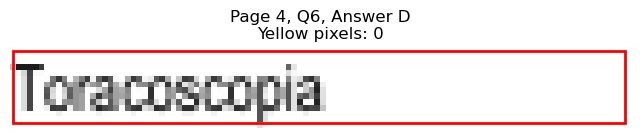

Page 4, Q6 - E: Detected box: x0=327.0, y0=518.6, x1=429.9, y1=531.2
Page 4, Q6, E: Yellow pixels: 0
Page 4, Q6, E: Total non-white pixels: 503
Page 4, Q6, E: Yellow percentage: 0.0%


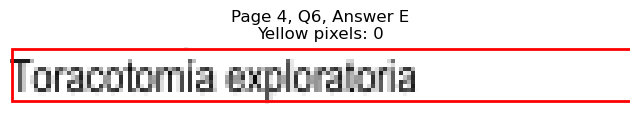


Page 4, Q6 - Selected Answer: A (based on yellow pixel count)




Page 4, Q7 - A: Detected box: x0=68.3, y0=581.7, x1=275.0, y1=594.4
Page 4, Q7, A: Yellow pixels: 1809
Page 4, Q7, A: Total non-white pixels: 3036
Page 4, Q7, A: Yellow percentage: 59.6%


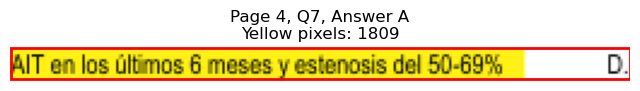

Page 4, Q7 - B: Detected box: x0=68.3, y0=594.3, x1=192.5, y1=607.0
Page 4, Q7, B: Yellow pixels: 0
Page 4, Q7, B: Total non-white pixels: 770
Page 4, Q7, B: Yellow percentage: 0.0%


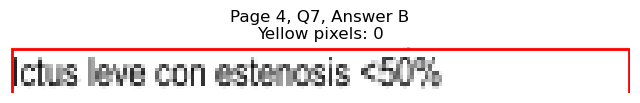

Page 4, Q7 - C: Detected box: x0=68.8, y0=606.9, x1=168.9, y1=619.6
Page 4, Q7, C: Yellow pixels: 0
Page 4, Q7, C: Total non-white pixels: 485
Page 4, Q7, C: Yellow percentage: 0.0%


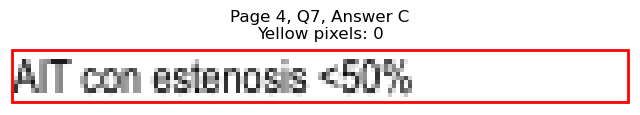

Page 4, Q7 - D: Detected box: x0=327.5, y0=581.7, x1=451.7, y1=594.4
Page 4, Q7, D: Yellow pixels: 0
Page 4, Q7, D: Total non-white pixels: 609
Page 4, Q7, D: Yellow percentage: 0.0%


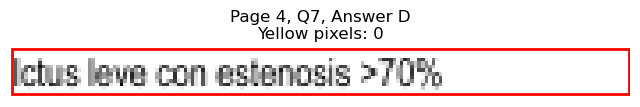

Page 4, Q7 - E: Detected box: x0=327.0, y0=594.3, x1=541.0, y1=607.0
Page 4, Q7, E: Yellow pixels: 0
Page 4, Q7, E: Total non-white pixels: 954
Page 4, Q7, E: Yellow percentage: 0.0%


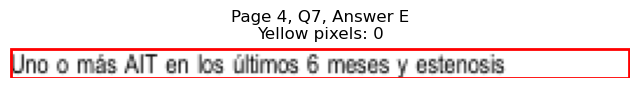


Page 4, Q7 - Selected Answer: A (based on yellow pixel count)




Page 4, Q8 - A: Detected box: x0=68.3, y0=695.4, x1=157.2, y1=708.0
Page 4, Q8, A: Yellow pixels: 0
Page 4, Q8, A: Total non-white pixels: 440
Page 4, Q8, A: Yellow percentage: 0.0%


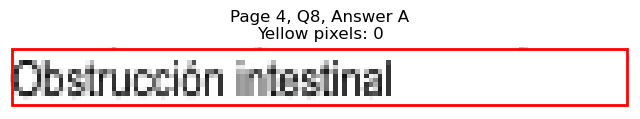

Page 4, Q8 - B: Detected box: x0=68.3, y0=708.0, x1=148.7, y1=720.6
Page 4, Q8, B: Yellow pixels: 0
Page 4, Q8, B: Total non-white pixels: 407
Page 4, Q8, B: Yellow percentage: 0.0%


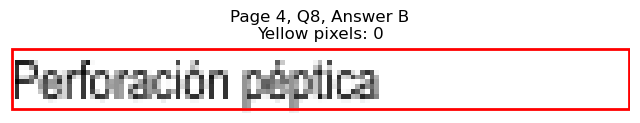

Page 4, Q8 - C: Detected box: x0=68.8, y0=720.6, x1=146.1, y1=733.2
Page 4, Q8, C: Yellow pixels: 0
Page 4, Q8, C: Total non-white pixels: 389
Page 4, Q8, C: Yellow percentage: 0.0%


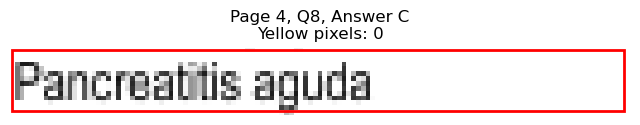

Page 4, Q8 - D: Detected box: x0=327.5, y0=695.4, x1=446.0, y1=708.0
Page 4, Q8, D: Yellow pixels: 169
Page 4, Q8, D: Total non-white pixels: 936
Page 4, Q8, D: Yellow percentage: 18.1%


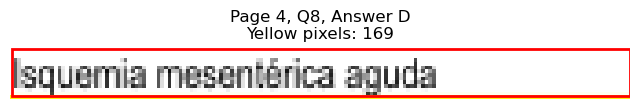

Page 4, Q8 - E: Detected box: x0=327.0, y0=708.0, x1=403.3, y1=720.6
Page 4, Q8, E: Yellow pixels: 1321
Page 4, Q8, E: Total non-white pixels: 1778
Page 4, Q8, E: Yellow percentage: 74.3%


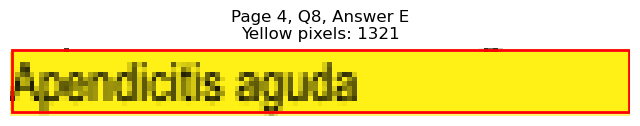


Page 4, Q8 - Selected Answer: E (based on yellow pixel count)





Page 5: Found 8 questions
Page 5, Q1 - A: Detected box: x0=68.3, y0=114.6, x1=169.1, y1=127.3
Page 5, Q1, A: Yellow pixels: 152
Page 5, Q1, A: Total non-white pixels: 625
Page 5, Q1, A: Yellow percentage: 24.3%


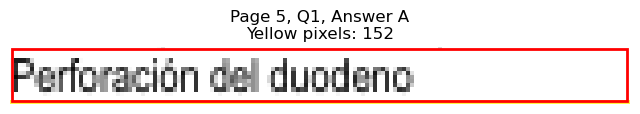

Page 5, Q1 - B: Detected box: x0=68.3, y0=127.2, x1=202.7, y1=139.9
Page 5, Q1, B: Yellow pixels: 1890
Page 5, Q1, B: Total non-white pixels: 2405
Page 5, Q1, B: Yellow percentage: 78.6%


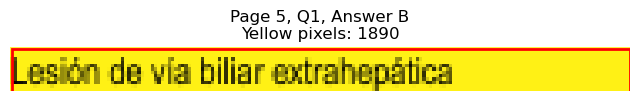

Page 5, Q1 - C: Detected box: x0=68.8, y0=139.9, x1=210.3, y1=152.6
Page 5, Q1, C: Yellow pixels: 191
Page 5, Q1, C: Total non-white pixels: 862
Page 5, Q1, C: Yellow percentage: 22.2%


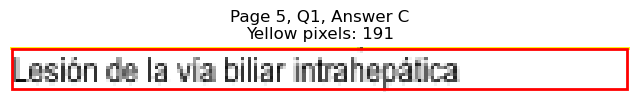

Page 5, Q1 - D: Detected box: x0=327.5, y0=114.6, x1=437.3, y1=127.3
Page 5, Q1, D: Yellow pixels: 0
Page 5, Q1, D: Total non-white pixels: 590
Page 5, Q1, D: Yellow percentage: 0.0%


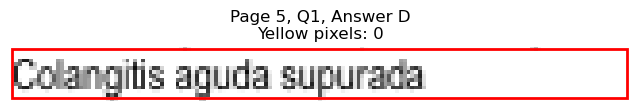

Page 5, Q1 - E: Detected box: x0=327.0, y0=127.2, x1=505.7, y1=139.9
Page 5, Q1, E: Yellow pixels: 0
Page 5, Q1, E: Total non-white pixels: 889
Page 5, Q1, E: Yellow percentage: 0.0%


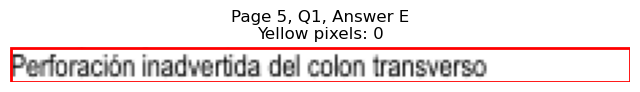


Page 5, Q1 - Selected Answer: B (based on yellow pixel count)




Page 5, Q2 - A: Detected box: x0=68.3, y0=190.3, x1=186.7, y1=203.0
Page 5, Q2, A: Yellow pixels: 0
Page 5, Q2, A: Total non-white pixels: 597
Page 5, Q2, A: Yellow percentage: 0.0%


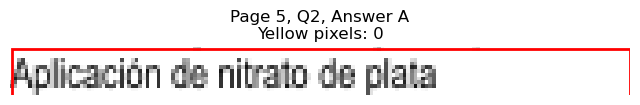

Page 5, Q2 - B: Detected box: x0=68.3, y0=202.9, x1=186.7, y1=215.6
Page 5, Q2, B: Yellow pixels: 0
Page 5, Q2, B: Total non-white pixels: 562
Page 5, Q2, B: Yellow percentage: 0.0%


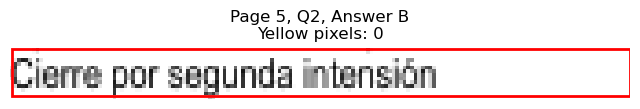

Page 5, Q2 - C: Detected box: x0=68.8, y0=215.7, x1=171.0, y1=228.3
Page 5, Q2, C: Yellow pixels: 0
Page 5, Q2, C: Total non-white pixels: 513
Page 5, Q2, C: Yellow percentage: 0.0%


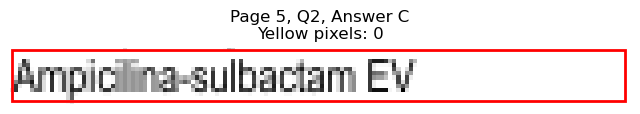

Page 5, Q2 - D: Detected box: x0=327.5, y0=190.3, x1=468.1, y1=203.0
Page 5, Q2, D: Yellow pixels: 0
Page 5, Q2, D: Total non-white pixels: 877
Page 5, Q2, D: Yellow percentage: 0.0%


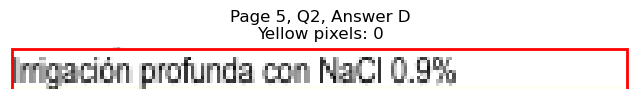

Page 5, Q2 - E: Detected box: x0=327.0, y0=202.9, x1=389.3, y1=215.6
Page 5, Q2, E: Yellow pixels: 1242
Page 5, Q2, E: Total non-white pixels: 1582
Page 5, Q2, E: Yellow percentage: 78.5%


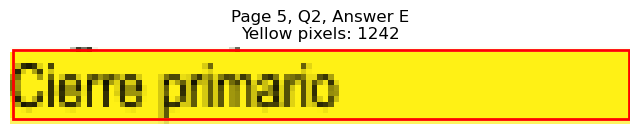


Page 5, Q2 - Selected Answer: E (based on yellow pixel count)




Page 5, Q3 - A: Detected box: x0=68.3, y0=291.4, x1=195.7, y1=304.1
Page 5, Q3, A: Yellow pixels: 178
Page 5, Q3, A: Total non-white pixels: 843
Page 5, Q3, A: Yellow percentage: 21.1%


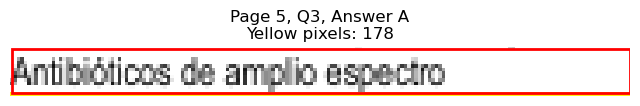

Page 5, Q3 - B: Detected box: x0=68.3, y0=304.0, x1=167.2, y1=316.7
Page 5, Q3, B: Yellow pixels: 1563
Page 5, Q3, B: Total non-white pixels: 1950
Page 5, Q3, B: Yellow percentage: 80.2%


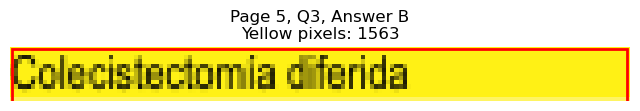

Page 5, Q3 - C: Detected box: x0=68.8, y0=316.6, x1=169.7, y1=329.3
Page 5, Q3, C: Yellow pixels: 152
Page 5, Q3, C: Total non-white pixels: 663
Page 5, Q3, C: Yellow percentage: 22.9%


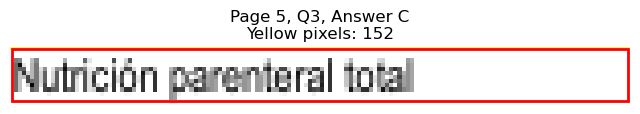

Page 5, Q3 - D: Detected box: x0=327.5, y0=291.4, x1=477.6, y1=304.1
Page 5, Q3, D: Yellow pixels: 0
Page 5, Q3, D: Total non-white pixels: 779
Page 5, Q3, D: Yellow percentage: 0.0%


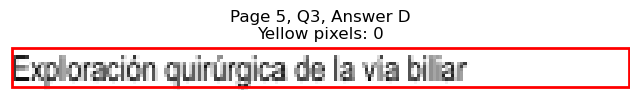

Page 5, Q3 - E: Detected box: x0=327.0, y0=304.0, x1=354.5, y1=316.7
Page 5, Q3, E: Yellow pixels: 0
Page 5, Q3, E: Total non-white pixels: 144
Page 5, Q3, E: Yellow percentage: 0.0%


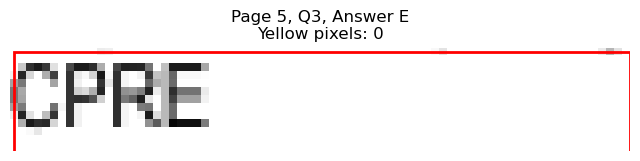


Page 5, Q3 - Selected Answer: B (based on yellow pixel count)




Page 5, Q4 - A: Detected box: x0=68.3, y0=354.5, x1=105.4, y1=367.2
Page 5, Q4, A: Yellow pixels: 0
Page 5, Q4, A: Total non-white pixels: 197
Page 5, Q4, A: Yellow percentage: 0.0%


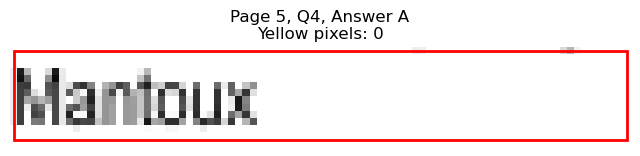

Page 5, Q4 - B: Detected box: x0=68.3, y0=367.1, x1=93.9, y1=379.8
Page 5, Q4, B: Yellow pixels: 0
Page 5, Q4, B: Total non-white pixels: 134
Page 5, Q4, B: Yellow percentage: 0.0%


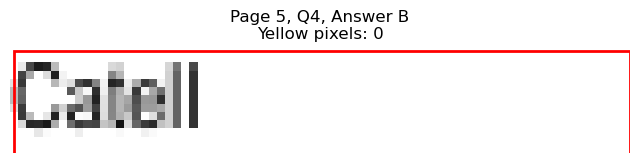

Page 5, Q4 - C: Detected box: x0=68.8, y0=379.7, x1=91.5, y1=392.4
Page 5, Q4, C: Yellow pixels: 0
Page 5, Q4, C: Total non-white pixels: 109
Page 5, Q4, C: Yellow percentage: 0.0%


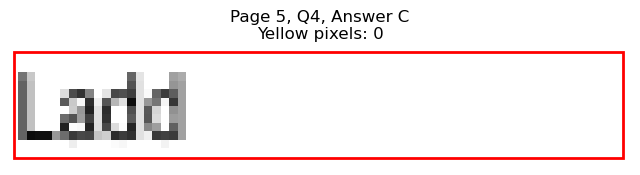

Page 5, Q4 - D: Detected box: x0=327.5, y0=354.5, x1=358.1, y1=367.2
Page 5, Q4, D: Yellow pixels: 955
Page 5, Q4, D: Total non-white pixels: 1148
Page 5, Q4, D: Yellow percentage: 83.2%


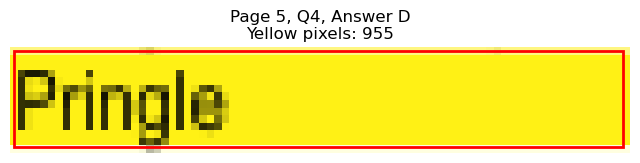

Page 5, Q4 - E: Detected box: x0=327.0, y0=367.1, x1=358.1, y1=379.8
Page 5, Q4, E: Yellow pixels: 0
Page 5, Q4, E: Total non-white pixels: 236
Page 5, Q4, E: Yellow percentage: 0.0%


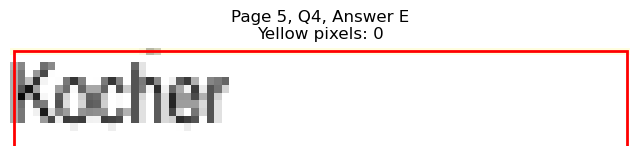


Page 5, Q4 - Selected Answer: D (based on yellow pixel count)




Page 5, Q5 - A: Detected box: x0=68.3, y0=442.8, x1=128.5, y1=455.5
Page 5, Q5, A: Yellow pixels: 0
Page 5, Q5, A: Total non-white pixels: 331
Page 5, Q5, A: Yellow percentage: 0.0%


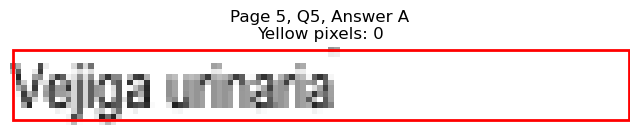

Page 5, Q5 - B: Detected box: x0=68.3, y0=455.5, x1=112.1, y1=468.1
Page 5, Q5, B: Yellow pixels: 0
Page 5, Q5, B: Total non-white pixels: 232
Page 5, Q5, B: Yellow percentage: 0.0%


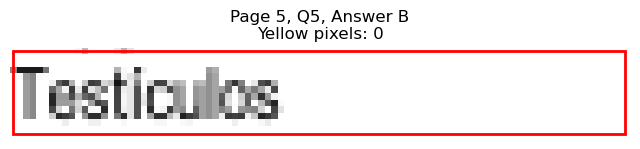

Page 5, Q5 - C: Detected box: x0=68.8, y0=468.1, x1=94.9, y1=480.7
Page 5, Q5, C: Yellow pixels: 0
Page 5, Q5, C: Total non-white pixels: 140
Page 5, Q5, C: Yellow percentage: 0.0%


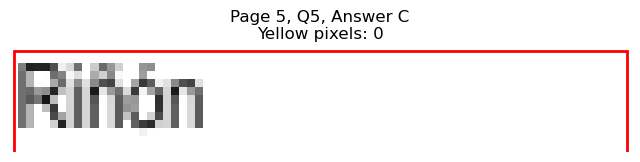

Page 5, Q5 - D: Detected box: x0=327.5, y0=442.8, x1=353.7, y1=455.5
Page 5, Q5, D: Yellow pixels: 77
Page 5, Q5, D: Total non-white pixels: 208
Page 5, Q5, D: Yellow percentage: 37.0%


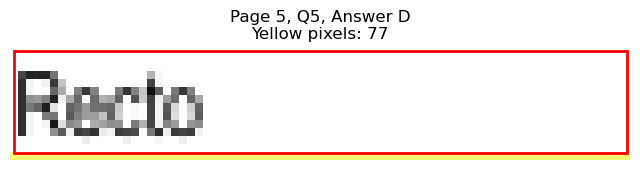

Page 5, Q5 - E: Detected box: x0=327.0, y0=455.5, x1=354.7, y1=468.1
Page 5, Q5, E: Yellow pixels: 912
Page 5, Q5, E: Total non-white pixels: 1092
Page 5, Q5, E: Yellow percentage: 83.5%


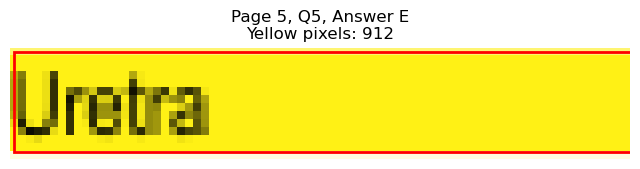


Page 5, Q5 - Selected Answer: E (based on yellow pixel count)




Page 5, Q6 - A: Detected box: x0=68.3, y0=506.0, x1=199.2, y1=518.6
Page 5, Q6, A: Yellow pixels: 0
Page 5, Q6, A: Total non-white pixels: 830
Page 5, Q6, A: Yellow percentage: 0.0%


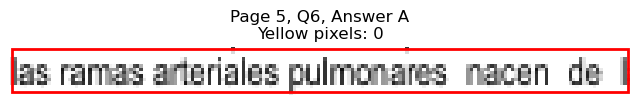

Page 5, Q6 - B: Detected box: x0=68.3, y0=531.2, x1=282.2, y1=543.8
Page 5, Q6, B: Yellow pixels: 2021
Page 5, Q6, B: Total non-white pixels: 2818
Page 5, Q6, B: Yellow percentage: 71.7%


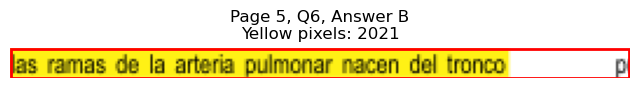

Page 5, Q6 - C: Detected box: x0=68.8, y0=556.5, x1=199.7, y1=569.2
Page 5, Q6, C: Yellow pixels: 181
Page 5, Q6, C: Total non-white pixels: 1045
Page 5, Q6, C: Yellow percentage: 17.3%


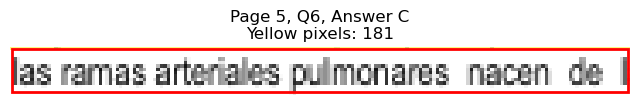

Page 5, Q6 - D: Detected box: x0=430.3, y0=506.0, x1=470.3, y1=518.6
Page 5, Q6, D: Yellow pixels: 0
Page 5, Q6, D: Total non-white pixels: 428
Page 5, Q6, D: Yellow percentage: 0.0%


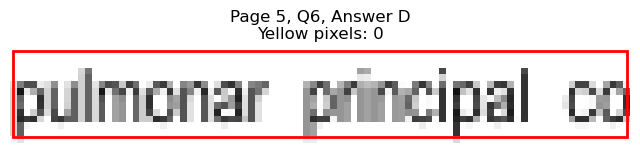

Page 5, Q6 - E: Detected box: x0=327.0, y0=543.8, x1=458.0, y1=556.4
Page 5, Q6, E: Yellow pixels: 0
Page 5, Q6, E: Total non-white pixels: 862
Page 5, Q6, E: Yellow percentage: 0.0%


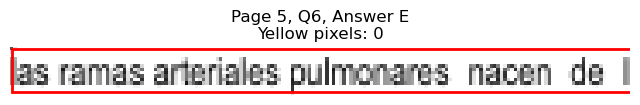


Page 5, Q6 - Selected Answer: B (based on yellow pixel count)




Page 5, Q7 - A: Detected box: x0=68.3, y0=644.9, x1=136.0, y1=657.5
Page 5, Q7, A: Yellow pixels: 118
Page 5, Q7, A: Total non-white pixels: 480
Page 5, Q7, A: Yellow percentage: 24.6%


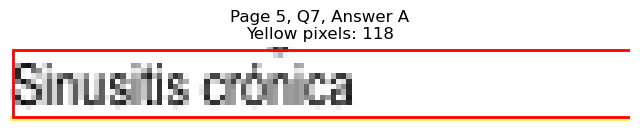

Page 5, Q7 - B: Detected box: x0=68.3, y0=657.5, x1=158.1, y1=670.1
Page 5, Q7, B: Yellow pixels: 1496
Page 5, Q7, B: Total non-white pixels: 1974
Page 5, Q7, B: Yellow percentage: 75.8%


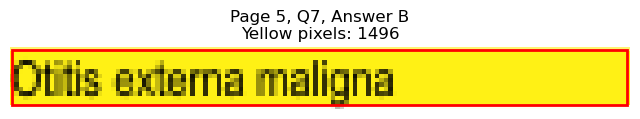

Page 5, Q7 - C: Detected box: x0=68.8, y0=670.1, x1=146.5, y1=682.7
Page 5, Q7, C: Yellow pixels: 0
Page 5, Q7, C: Total non-white pixels: 533
Page 5, Q7, C: Yellow percentage: 0.0%


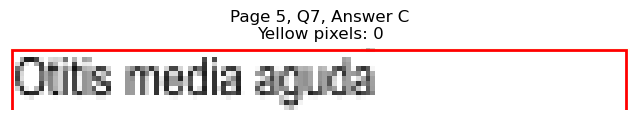

Page 5, Q7 - D: Detected box: x0=327.5, y0=644.9, x1=414.8, y1=657.5
Page 5, Q7, D: Yellow pixels: 0
Page 5, Q7, D: Total non-white pixels: 430
Page 5, Q7, D: Yellow percentage: 0.0%


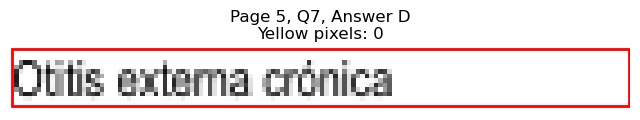

Page 5, Q7 - E: Detected box: x0=327.0, y0=657.5, x1=408.8, y1=670.1
Page 5, Q7, E: Yellow pixels: 0
Page 5, Q7, E: Total non-white pixels: 425
Page 5, Q7, E: Yellow percentage: 0.0%


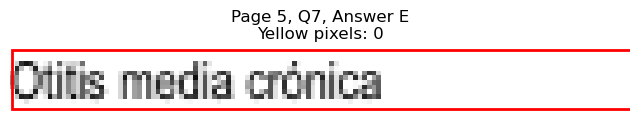


Page 5, Q7 - Selected Answer: B (based on yellow pixel count)




Page 5, Q8 - A: Detected box: x0=68.3, y0=708.0, x1=375.8, y1=720.6
Page 5, Q8, A: Yellow pixels: 358
Page 5, Q8, A: Total non-white pixels: 1777
Page 5, Q8, A: Yellow percentage: 20.1%


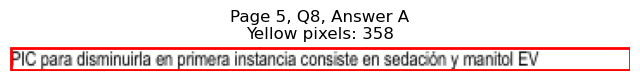

Page 5, Q8 - B: Detected box: x0=68.3, y0=720.6, x1=398.1, y1=733.2
Page 5, Q8, B: Yellow pixels: 3703
Page 5, Q8, B: Total non-white pixels: 5334
Page 5, Q8, B: Yellow percentage: 69.4%


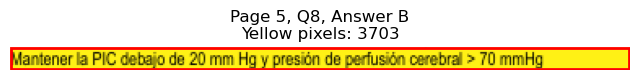

Page 5, Q8 - C: Detected box: x0=68.8, y0=733.2, x1=335.6, y1=745.8
Page 5, Q8, C: Yellow pixels: 0
Page 5, Q8, C: Total non-white pixels: 1610
Page 5, Q8, C: Yellow percentage: 0.0%


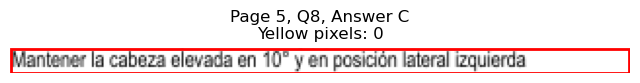

Page 5, Q8 - D: Detected box: x0=68.8, y0=745.8, x1=398.6, y1=758.4
Page 5, Q8, D: Yellow pixels: 0
Page 5, Q8, D: Total non-white pixels: 1551
Page 5, Q8, D: Yellow percentage: 0.0%


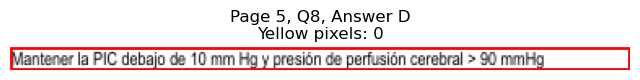

Page 5, Q8 - E: Detected box: x0=68.3, y0=758.5, x1=355.9, y1=771.2
Page 5, Q8, E: Yellow pixels: 0
Page 5, Q8, E: Total non-white pixels: 1330
Page 5, Q8, E: Yellow percentage: 0.0%


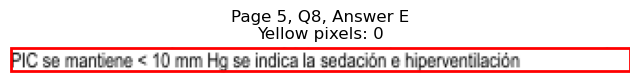


Page 5, Q8 - Selected Answer: B (based on yellow pixel count)





Page 6: Found 8 questions
Page 6, Q1 - A: Detected box: x0=68.3, y0=114.6, x1=126.0, y1=127.3
Page 6, Q1, A: Yellow pixels: 0
Page 6, Q1, A: Total non-white pixels: 294
Page 6, Q1, A: Yellow percentage: 0.0%


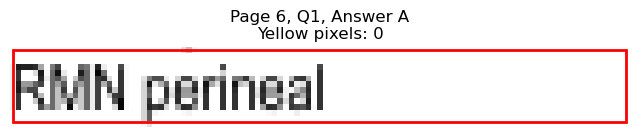

Page 6, Q1 - B: Detected box: x0=68.3, y0=127.2, x1=199.4, y1=139.9
Page 6, Q1, B: Yellow pixels: 0
Page 6, Q1, B: Total non-white pixels: 650
Page 6, Q1, B: Yellow percentage: 0.0%


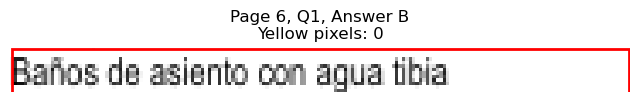

Page 6, Q1 - C: Detected box: x0=68.8, y0=139.9, x1=156.1, y1=152.6
Page 6, Q1, C: Yellow pixels: 0
Page 6, Q1, C: Total non-white pixels: 464
Page 6, Q1, C: Yellow percentage: 0.0%


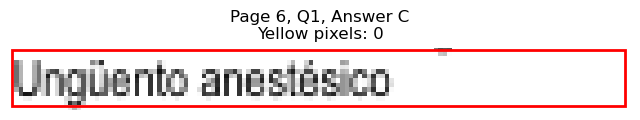

Page 6, Q1 - D: Detected box: x0=327.5, y0=114.6, x1=413.5, y1=127.3
Page 6, Q1, D: Yellow pixels: 137
Page 6, Q1, D: Total non-white pixels: 587
Page 6, Q1, D: Yellow percentage: 23.3%


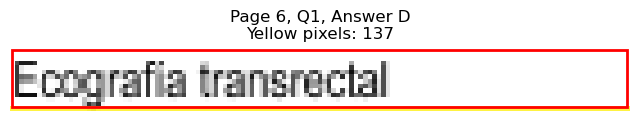

Page 6, Q1 - E: Detected box: x0=327.0, y0=127.2, x1=361.1, y1=139.9
Page 6, Q1, E: Yellow pixels: 979
Page 6, Q1, E: Total non-white pixels: 1105
Page 6, Q1, E: Yellow percentage: 88.6%


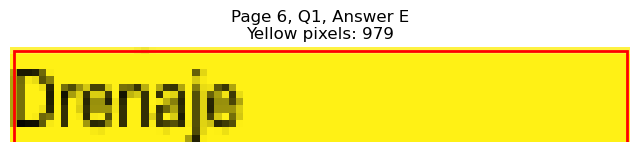


Page 6, Q1 - Selected Answer: E (based on yellow pixel count)




Page 6, Q2 - A: Detected box: x0=68.3, y0=190.3, x1=175.6, y1=203.0
Page 6, Q2, A: Yellow pixels: 0
Page 6, Q2, A: Total non-white pixels: 674
Page 6, Q2, A: Yellow percentage: 0.0%


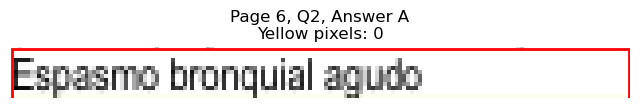

Page 6, Q2 - B: Detected box: x0=68.3, y0=202.9, x1=175.1, y1=215.6
Page 6, Q2, B: Yellow pixels: 1663
Page 6, Q2, B: Total non-white pixels: 2212
Page 6, Q2, B: Yellow percentage: 75.2%


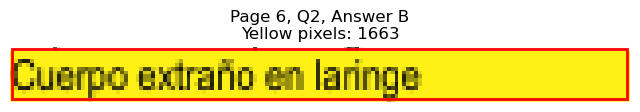

Page 6, Q2 - C: Detected box: x0=68.8, y0=215.7, x1=201.6, y1=228.3
Page 6, Q2, C: Yellow pixels: 182
Page 6, Q2, C: Total non-white pixels: 844
Page 6, Q2, C: Yellow percentage: 21.6%


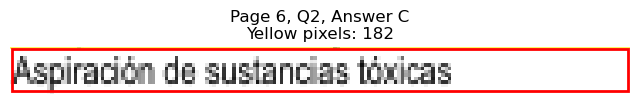

Page 6, Q2 - D: Detected box: x0=327.5, y0=190.3, x1=409.3, y1=203.0
Page 6, Q2, D: Yellow pixels: 0
Page 6, Q2, D: Total non-white pixels: 423
Page 6, Q2, D: Yellow percentage: 0.0%


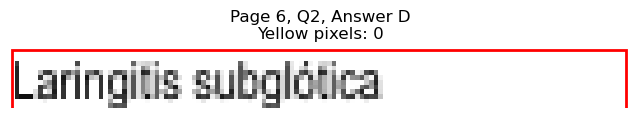

Page 6, Q2 - E: Detected box: x0=327.0, y0=202.9, x1=421.4, y1=215.6
Page 6, Q2, E: Yellow pixels: 0
Page 6, Q2, E: Total non-white pixels: 515
Page 6, Q2, E: Yellow percentage: 0.0%


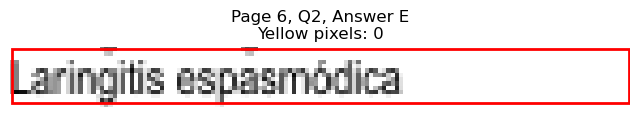


Page 6, Q2 - Selected Answer: B (based on yellow pixel count)




Page 6, Q3 - A: Detected box: x0=68.3, y0=278.8, x1=183.4, y1=291.5
Page 6, Q3, A: Yellow pixels: 0
Page 6, Q3, A: Total non-white pixels: 553
Page 6, Q3, A: Yellow percentage: 0.0%


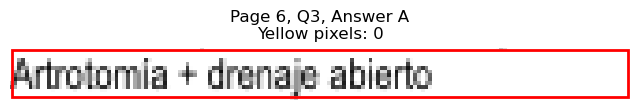

Page 6, Q3 - B: Detected box: x0=68.3, y0=291.4, x1=250.6, y1=304.1
Page 6, Q3, B: Yellow pixels: 213
Page 6, Q3, B: Total non-white pixels: 1119
Page 6, Q3, B: Yellow percentage: 19.0%


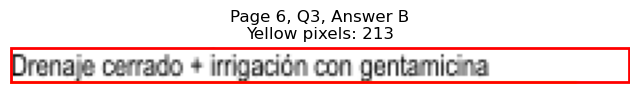

Page 6, Q3 - C: Detected box: x0=68.8, y0=304.0, x1=218.1, y1=316.7
Page 6, Q3, C: Yellow pixels: 2058
Page 6, Q3, C: Total non-white pixels: 2613
Page 6, Q3, C: Yellow percentage: 78.8%


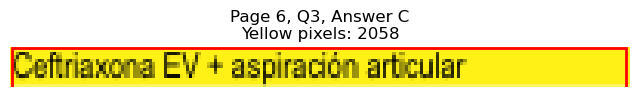

Page 6, Q3 - D: Detected box: x0=327.5, y0=278.8, x1=421.6, y1=291.5
Page 6, Q3, D: Yellow pixels: 0
Page 6, Q3, D: Total non-white pixels: 463
Page 6, Q3, D: Yellow percentage: 0.0%


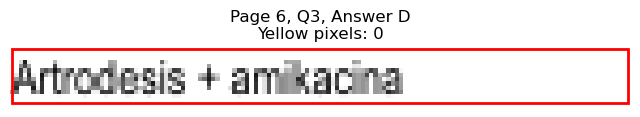

Page 6, Q3 - E: Detected box: x0=327.0, y0=291.4, x1=460.3, y1=304.1
Page 6, Q3, E: Yellow pixels: 0
Page 6, Q3, E: Total non-white pixels: 608
Page 6, Q3, E: Yellow percentage: 0.0%


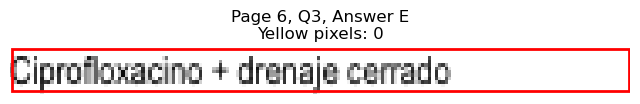


Page 6, Q3 - Selected Answer: C (based on yellow pixel count)




Page 6, Q4 - A: Detected box: x0=68.3, y0=367.1, x1=147.5, y1=379.8
Page 6, Q4, A: Yellow pixels: 1354
Page 6, Q4, A: Total non-white pixels: 1690
Page 6, Q4, A: Yellow percentage: 80.1%


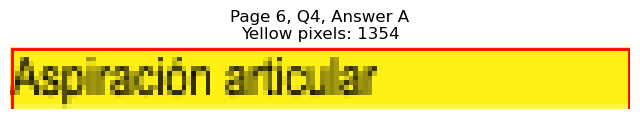

Page 6, Q4 - B: Detected box: x0=68.3, y0=379.7, x1=118.5, y1=392.4
Page 6, Q4, B: Yellow pixels: 101
Page 6, Q4, B: Total non-white pixels: 346
Page 6, Q4, B: Yellow percentage: 29.2%


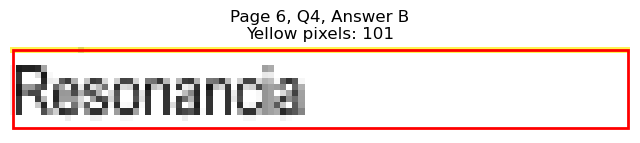

Page 6, Q4 - C: Detected box: x0=68.8, y0=392.3, x1=121.5, y1=405.0
Page 6, Q4, C: Yellow pixels: 0
Page 6, Q4, C: Total non-white pixels: 266
Page 6, Q4, C: Yellow percentage: 0.0%


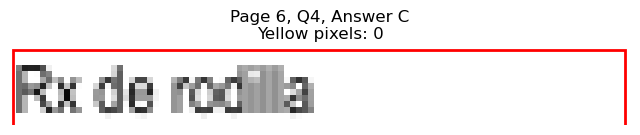

Page 6, Q4 - D: Detected box: x0=327.5, y0=367.1, x1=376.1, y1=379.8
Page 6, Q4, D: Yellow pixels: 0
Page 6, Q4, D: Total non-white pixels: 240
Page 6, Q4, D: Yellow percentage: 0.0%


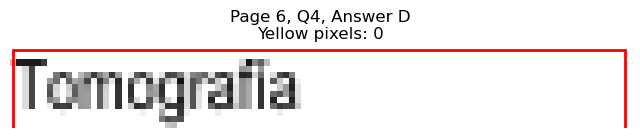

Page 6, Q4 - E: Detected box: x0=327.0, y0=379.7, x1=371.7, y1=392.4
Page 6, Q4, E: Yellow pixels: 0
Page 6, Q4, E: Total non-white pixels: 227
Page 6, Q4, E: Yellow percentage: 0.0%


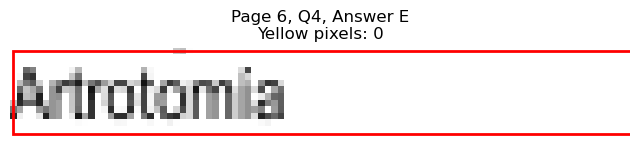


Page 6, Q4 - Selected Answer: A (based on yellow pixel count)




Page 6, Q5 - A: Detected box: x0=68.3, y0=430.2, x1=139.1, y1=442.9
Page 6, Q5, A: Yellow pixels: 0
Page 6, Q5, A: Total non-white pixels: 345
Page 6, Q5, A: Yellow percentage: 0.0%


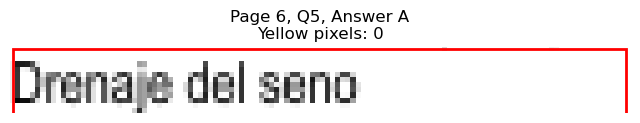

Page 6, Q5 - B: Detected box: x0=68.3, y0=442.8, x1=126.1, y1=455.5
Page 6, Q5, B: Yellow pixels: 0
Page 6, Q5, B: Total non-white pixels: 285
Page 6, Q5, B: Yellow percentage: 0.0%


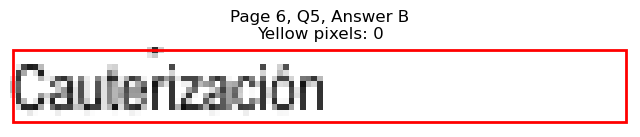

Page 6, Q5 - C: Detected box: x0=68.8, y0=455.5, x1=117.5, y1=468.1
Page 6, Q5, C: Yellow pixels: 0
Page 6, Q5, C: Total non-white pixels: 268
Page 6, Q5, C: Yellow percentage: 0.0%


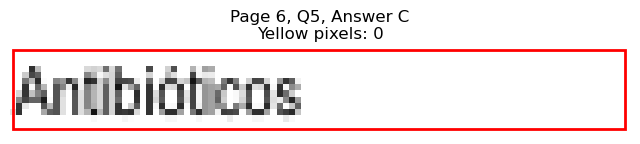

Page 6, Q5 - D: Detected box: x0=327.5, y0=430.2, x1=395.3, y1=442.9
Page 6, Q5, D: Yellow pixels: 1301
Page 6, Q5, D: Total non-white pixels: 1547
Page 6, Q5, D: Yellow percentage: 84.1%


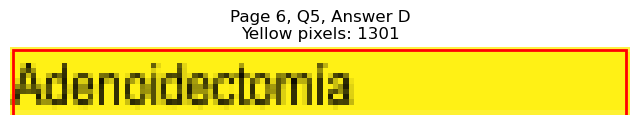

Page 6, Q5 - E: Detected box: x0=327.0, y0=442.8, x1=428.3, y1=455.5
Page 6, Q5, E: Yellow pixels: 152
Page 6, Q5, E: Total non-white pixels: 675
Page 6, Q5, E: Yellow percentage: 22.5%


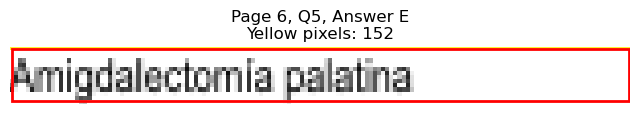


Page 6, Q5 - Selected Answer: D (based on yellow pixel count)




Page 6, Q6 - A: Detected box: x0=68.3, y0=506.0, x1=244.8, y1=518.6
Page 6, Q6, A: Yellow pixels: 213
Page 6, Q6, A: Total non-white pixels: 1117
Page 6, Q6, A: Yellow percentage: 19.1%


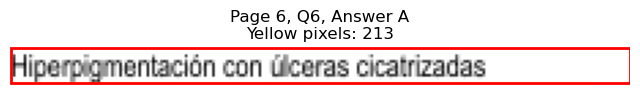

Page 6, Q6 - B: Detected box: x0=68.3, y0=518.6, x1=179.2, y1=531.2
Page 6, Q6, B: Yellow pixels: 1702
Page 6, Q6, B: Total non-white pixels: 2268
Page 6, Q6, B: Yellow percentage: 75.0%


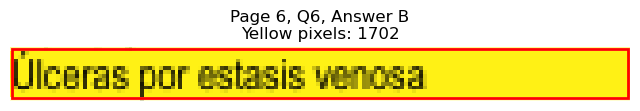

Page 6, Q6 - C: Detected box: x0=68.8, y0=531.2, x1=169.6, y1=543.8
Page 6, Q6, C: Yellow pixels: 0
Page 6, Q6, C: Total non-white pixels: 637
Page 6, Q6, C: Yellow percentage: 0.0%


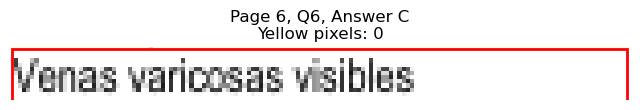

Page 6, Q6 - D: Detected box: x0=327.5, y0=506.0, x1=445.4, y1=518.6
Page 6, Q6, D: Yellow pixels: 0
Page 6, Q6, D: Total non-white pixels: 588
Page 6, Q6, D: Yellow percentage: 0.0%


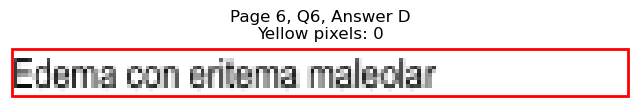

Page 6, Q6 - E: Detected box: x0=327.0, y0=518.6, x1=522.2, y1=531.2
Page 6, Q6, E: Yellow pixels: 0
Page 6, Q6, E: Total non-white pixels: 1012
Page 6, Q6, E: Yellow percentage: 0.0%


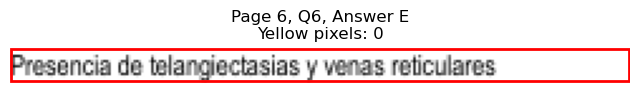


Page 6, Q6 - Selected Answer: B (based on yellow pixel count)




Page 6, Q7 - A: Detected box: x0=68.3, y0=606.9, x1=142.6, y1=619.6
Page 6, Q7, A: Yellow pixels: 1319
Page 6, Q7, A: Total non-white pixels: 1750
Page 6, Q7, A: Yellow percentage: 75.4%


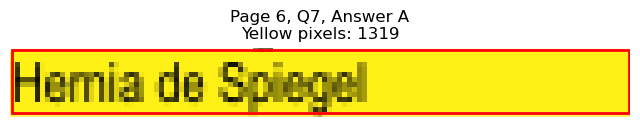

Page 6, Q7 - B: Detected box: x0=68.3, y0=619.6, x1=130.5, y1=632.3
Page 6, Q7, B: Yellow pixels: 112
Page 6, Q7, B: Total non-white pixels: 421
Page 6, Q7, B: Yellow percentage: 26.6%


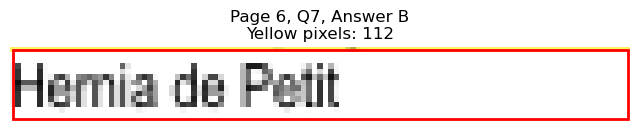

Page 6, Q7 - C: Detected box: x0=68.8, y0=632.2, x1=147.0, y1=644.9
Page 6, Q7, C: Yellow pixels: 0
Page 6, Q7, C: Total non-white pixels: 372
Page 6, Q7, C: Yellow percentage: 0.0%


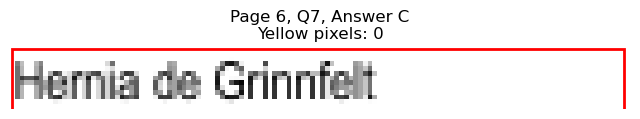

Page 6, Q7 - D: Detected box: x0=327.5, y0=606.9, x1=412.3, y1=619.6
Page 6, Q7, D: Yellow pixels: 0
Page 6, Q7, D: Total non-white pixels: 437
Page 6, Q7, D: Yellow percentage: 0.0%


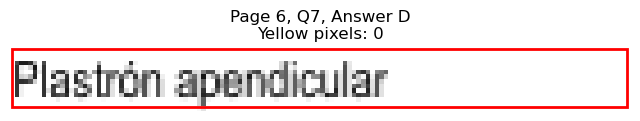

Page 6, Q7 - E: Detected box: x0=327.0, y0=619.6, x1=421.4, y1=632.3
Page 6, Q7, E: Yellow pixels: 0
Page 6, Q7, E: Total non-white pixels: 500
Page 6, Q7, E: Yellow percentage: 0.0%


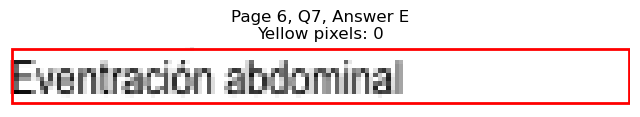


Page 6, Q7 - Selected Answer: A (based on yellow pixel count)




Page 6, Q8 - A: Detected box: x0=128.0, y0=670.1, x1=190.6, y1=682.7
Page 6, Q8, A: Yellow pixels: 0
Page 6, Q8, A: Total non-white pixels: 537
Page 6, Q8, A: Yellow percentage: 0.0%


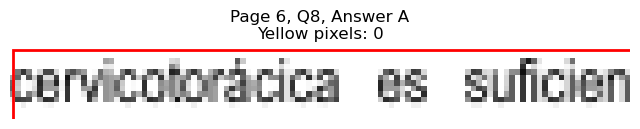

Page 6, Q8 - B: Detected box: x0=68.3, y0=695.4, x1=106.0, y1=708.0
Page 6, Q8, B: Yellow pixels: 928
Page 6, Q8, B: Total non-white pixels: 1232
Page 6, Q8, B: Yellow percentage: 75.3%


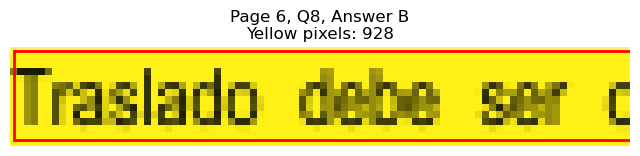

Page 6, Q8 - C: Detected box: x0=133.3, y0=720.6, x1=211.7, y1=733.2
Page 6, Q8, C: Yellow pixels: 129
Page 6, Q8, C: Total non-white pixels: 690
Page 6, Q8, C: Yellow percentage: 18.7%


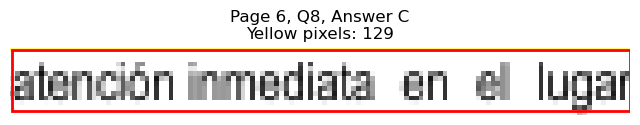

Page 6, Q8 - D: Detected box: x0=361.5, y0=670.1, x1=402.1, y1=682.7
Page 6, Q8, D: Yellow pixels: 0
Page 6, Q8, D: Total non-white pixels: 373
Page 6, Q8, D: Yellow percentage: 0.0%


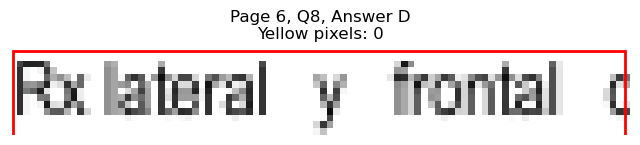

Page 6, Q8 - E: Detected box: x0=326.1, y0=695.4, x1=528.0, y1=708.0
Page 6, Q8, E: Yellow pixels: 0
Page 6, Q8, E: Total non-white pixels: 1026
Page 6, Q8, E: Yellow percentage: 0.0%


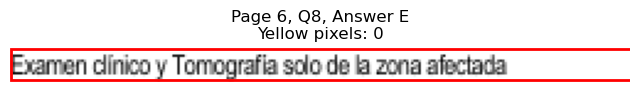


Page 6, Q8 - Selected Answer: B (based on yellow pixel count)





Page 7: Found 8 questions
Page 7, Q1 - A: Detected box: x0=68.3, y0=127.2, x1=146.5, y1=139.9
Page 7, Q1, A: Yellow pixels: 1360
Page 7, Q1, A: Total non-white pixels: 1677
Page 7, Q1, A: Yellow percentage: 81.1%


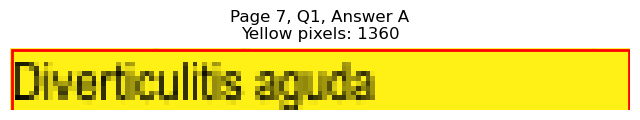

Page 7, Q1 - B: Detected box: x0=68.3, y0=139.9, x1=159.6, y1=152.6
Page 7, Q1, B: Yellow pixels: 138
Page 7, Q1, B: Total non-white pixels: 588
Page 7, Q1, B: Yellow percentage: 23.5%


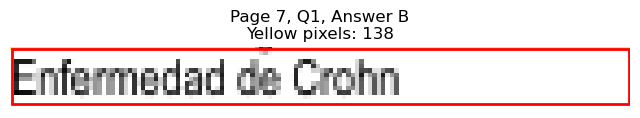

Page 7, Q1 - C: Detected box: x0=68.8, y0=152.5, x1=136.9, y1=165.2
Page 7, Q1, C: Yellow pixels: 0
Page 7, Q1, C: Total non-white pixels: 354
Page 7, Q1, C: Yellow percentage: 0.0%


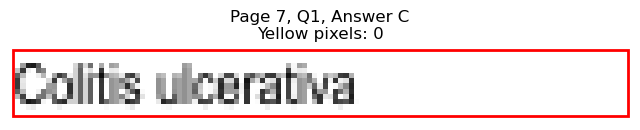

Page 7, Q1 - D: Detected box: x0=327.5, y0=127.2, x1=385.7, y1=139.9
Page 7, Q1, D: Yellow pixels: 0
Page 7, Q1, D: Total non-white pixels: 309
Page 7, Q1, D: Yellow percentage: 0.0%


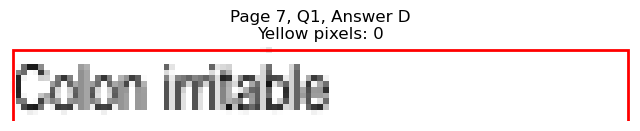

Page 7, Q1 - E: Detected box: x0=327.0, y0=139.9, x1=380.2, y1=152.6
Page 7, Q1, E: Yellow pixels: 0
Page 7, Q1, E: Total non-white pixels: 251
Page 7, Q1, E: Yellow percentage: 0.0%


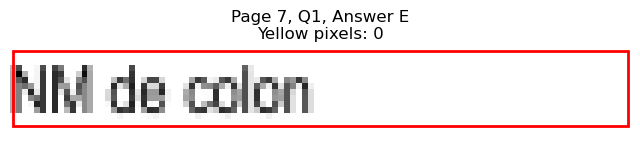


Page 7, Q1 - Selected Answer: A (based on yellow pixel count)




Page 7, Q2 - A: Detected box: x0=68.3, y0=215.7, x1=134.5, y1=228.3
Page 7, Q2, A: Yellow pixels: 0
Page 7, Q2, A: Total non-white pixels: 326
Page 7, Q2, A: Yellow percentage: 0.0%


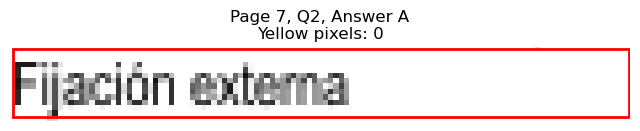

Page 7, Q2 - B: Detected box: x0=68.3, y0=228.3, x1=149.1, y1=240.9
Page 7, Q2, B: Yellow pixels: 0
Page 7, Q2, B: Total non-white pixels: 534
Page 7, Q2, B: Yellow percentage: 0.0%


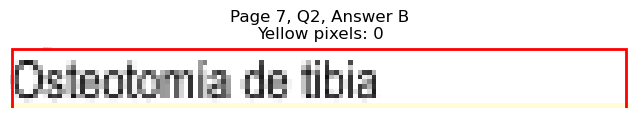

Page 7, Q2 - C: Detected box: x0=68.8, y0=240.9, x1=120.4, y1=253.5
Page 7, Q2, C: Yellow pixels: 1132
Page 7, Q2, C: Total non-white pixels: 1442
Page 7, Q2, C: Yellow percentage: 78.5%


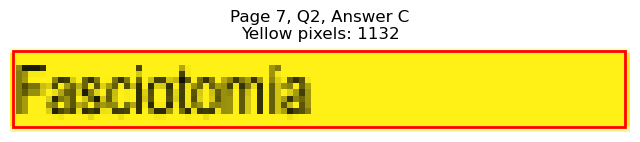

Page 7, Q2 - D: Detected box: x0=327.5, y0=215.7, x1=400.3, y1=228.3
Page 7, Q2, D: Yellow pixels: 0
Page 7, Q2, D: Total non-white pixels: 356
Page 7, Q2, D: Yellow percentage: 0.0%


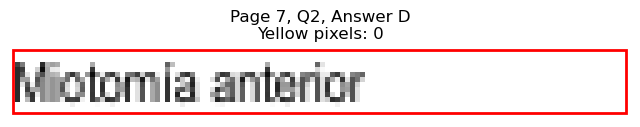

Page 7, Q2 - E: Detected box: x0=327.0, y0=228.3, x1=401.3, y1=240.9
Page 7, Q2, E: Yellow pixels: 0
Page 7, Q2, E: Total non-white pixels: 358
Page 7, Q2, E: Yellow percentage: 0.0%


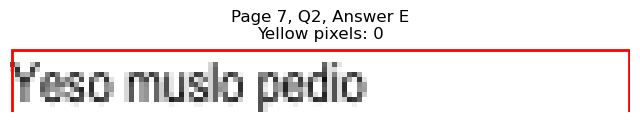


Page 7, Q2 - Selected Answer: C (based on yellow pixel count)




Page 7, Q3 - A: Detected box: x0=68.3, y0=304.0, x1=190.7, y1=316.7
Page 7, Q3, A: Yellow pixels: 0
Page 7, Q3, A: Total non-white pixels: 777
Page 7, Q3, A: Yellow percentage: 0.0%


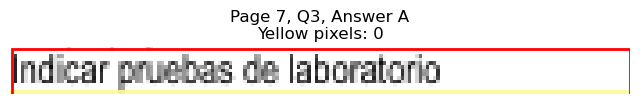

Page 7, Q3 - B: Detected box: x0=68.3, y0=316.6, x1=157.2, y1=329.3
Page 7, Q3, B: Yellow pixels: 1337
Page 7, Q3, B: Total non-white pixels: 1960
Page 7, Q3, B: Yellow percentage: 68.2%


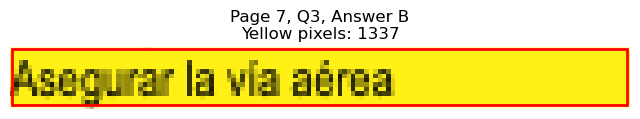

Page 7, Q3 - C: Detected box: x0=68.8, y0=329.2, x1=168.6, y1=341.9
Page 7, Q3, C: Yellow pixels: 0
Page 7, Q3, C: Total non-white pixels: 639
Page 7, Q3, C: Yellow percentage: 0.0%


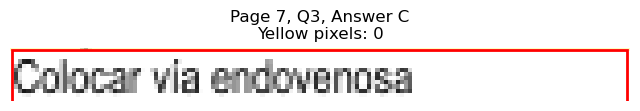

Page 7, Q3 - D: Detected box: x0=327.5, y0=304.0, x1=408.3, y1=316.7
Page 7, Q3, D: Yellow pixels: 0
Page 7, Q3, D: Total non-white pixels: 421
Page 7, Q3, D: Yellow percentage: 0.0%


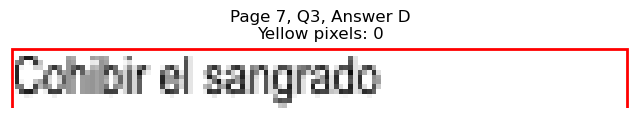

Page 7, Q3 - E: Detected box: x0=327.0, y0=316.6, x1=470.6, y1=329.3
Page 7, Q3, E: Yellow pixels: 0
Page 7, Q3, E: Total non-white pixels: 724
Page 7, Q3, E: Yellow percentage: 0.0%


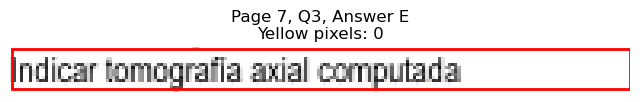


Page 7, Q3 - Selected Answer: B (based on yellow pixel count)




Page 7, Q4 - A: Detected box: x0=68.3, y0=367.1, x1=230.7, y1=379.8
Page 7, Q4, A: Yellow pixels: 0
Page 7, Q4, A: Total non-white pixels: 844
Page 7, Q4, A: Yellow percentage: 0.0%


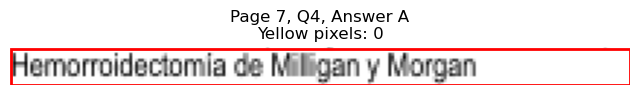

Page 7, Q4 - B: Detected box: x0=68.3, y0=379.7, x1=198.3, y1=392.4
Page 7, Q4, B: Yellow pixels: 0
Page 7, Q4, B: Total non-white pixels: 654
Page 7, Q4, B: Yellow percentage: 0.0%


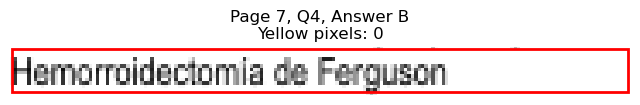

Page 7, Q4 - C: Detected box: x0=68.8, y0=392.3, x1=129.5, y1=405.0
Page 7, Q4, C: Yellow pixels: 0
Page 7, Q4, C: Total non-white pixels: 301
Page 7, Q4, C: Yellow percentage: 0.0%


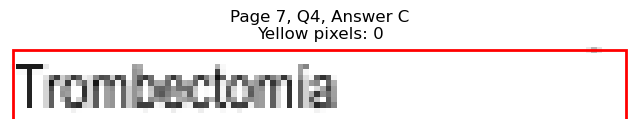

Page 7, Q4 - D: Detected box: x0=327.5, y0=367.1, x1=442.9, y1=379.8
Page 7, Q4, D: Yellow pixels: 1733
Page 7, Q4, D: Total non-white pixels: 2158
Page 7, Q4, D: Yellow percentage: 80.3%


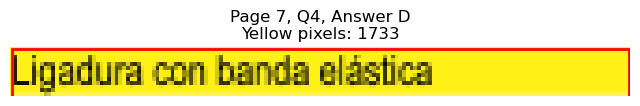

Page 7, Q4 - E: Detected box: x0=327.0, y0=379.7, x1=464.5, y1=392.4
Page 7, Q4, E: Yellow pixels: 186
Page 7, Q4, E: Total non-white pixels: 897
Page 7, Q4, E: Yellow percentage: 20.7%


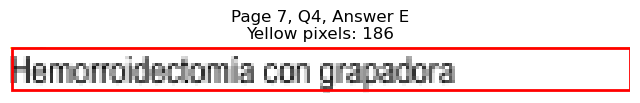


Page 7, Q4 - Selected Answer: D (based on yellow pixel count)




Page 7, Q5 - A: Detected box: x0=68.3, y0=442.8, x1=107.9, y1=455.5
Page 7, Q5, A: Yellow pixels: 90
Page 7, Q5, A: Total non-white pixels: 268
Page 7, Q5, A: Yellow percentage: 33.6%


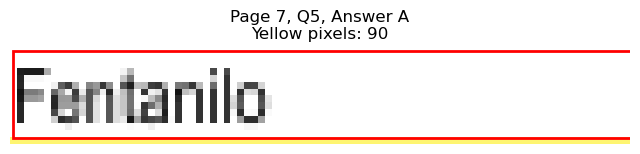

Page 7, Q5 - B: Detected box: x0=68.3, y0=455.5, x1=104.4, y1=468.1
Page 7, Q5, B: Yellow pixels: 987
Page 7, Q5, B: Total non-white pixels: 1218
Page 7, Q5, B: Yellow percentage: 81.0%


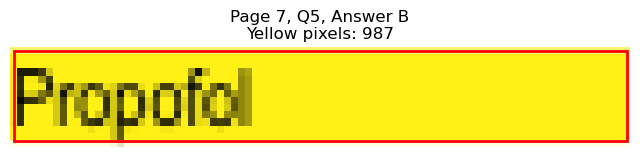

Page 7, Q5 - C: Detected box: x0=68.8, y0=468.1, x1=101.4, y1=480.7
Page 7, Q5, C: Yellow pixels: 0
Page 7, Q5, C: Total non-white pixels: 252
Page 7, Q5, C: Yellow percentage: 0.0%


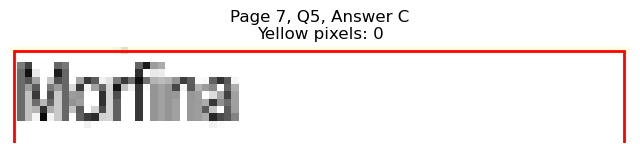

Page 7, Q5 - D: Detected box: x0=327.5, y0=442.8, x1=367.3, y1=455.5
Page 7, Q5, D: Yellow pixels: 0
Page 7, Q5, D: Total non-white pixels: 208
Page 7, Q5, D: Yellow percentage: 0.0%


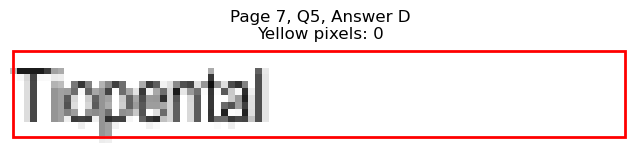

Page 7, Q5 - E: Detected box: x0=327.0, y0=455.5, x1=367.7, y1=468.1
Page 7, Q5, E: Yellow pixels: 0
Page 7, Q5, E: Total non-white pixels: 193
Page 7, Q5, E: Yellow percentage: 0.0%


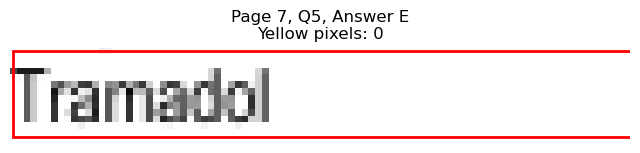


Page 7, Q5 - Selected Answer: B (based on yellow pixel count)




Page 7, Q6 - A: Detected box: x0=68.3, y0=518.6, x1=192.6, y1=531.2
Page 7, Q6, A: Yellow pixels: 0
Page 7, Q6, A: Total non-white pixels: 598
Page 7, Q6, A: Yellow percentage: 0.0%


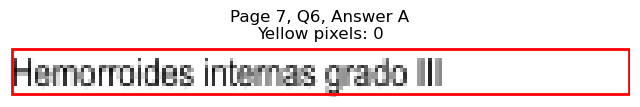

Page 7, Q6 - B: Detected box: x0=68.3, y0=531.2, x1=153.0, y1=543.8
Page 7, Q6, B: Yellow pixels: 0
Page 7, Q6, B: Total non-white pixels: 539
Page 7, Q6, B: Yellow percentage: 0.0%


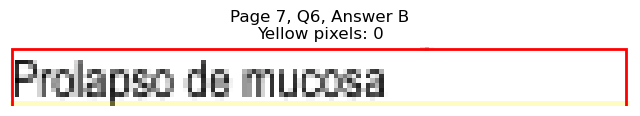

Page 7, Q6 - C: Detected box: x0=68.8, y0=543.8, x1=190.6, y1=556.4
Page 7, Q6, C: Yellow pixels: 1760
Page 7, Q6, C: Total non-white pixels: 2422
Page 7, Q6, C: Yellow percentage: 72.7%


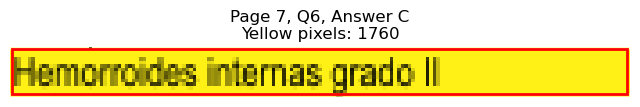

Page 7, Q6 - D: Detected box: x0=327.5, y0=518.6, x1=410.2, y1=531.2
Page 7, Q6, D: Yellow pixels: 0
Page 7, Q6, D: Total non-white pixels: 416
Page 7, Q6, D: Yellow percentage: 0.0%


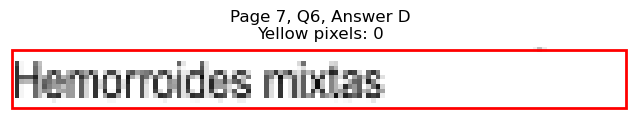

Page 7, Q6 - E: Detected box: x0=327.0, y0=531.2, x1=374.2, y1=543.8
Page 7, Q6, E: Yellow pixels: 0
Page 7, Q6, E: Total non-white pixels: 228
Page 7, Q6, E: Yellow percentage: 0.0%


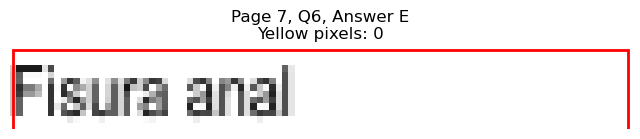


Page 7, Q6 - Selected Answer: C (based on yellow pixel count)




Page 7, Q7 - A: Detected box: x0=68.3, y0=594.3, x1=160.7, y1=607.0
Page 7, Q7, A: Yellow pixels: 0
Page 7, Q7, A: Total non-white pixels: 479
Page 7, Q7, A: Yellow percentage: 0.0%


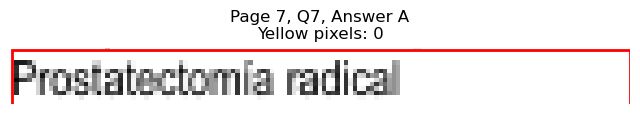

Page 7, Q7 - B: Detected box: x0=68.3, y0=606.9, x1=139.0, y1=619.6
Page 7, Q7, B: Yellow pixels: 0
Page 7, Q7, B: Total non-white pixels: 383
Page 7, Q7, B: Yellow percentage: 0.0%


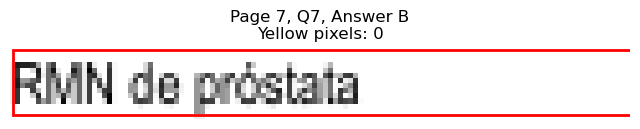

Page 7, Q7 - C: Detected box: x0=68.8, y0=619.6, x1=215.7, y1=632.3
Page 7, Q7, C: Yellow pixels: 0
Page 7, Q7, C: Total non-white pixels: 726
Page 7, Q7, C: Yellow percentage: 0.0%


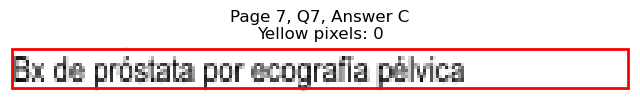

Page 7, Q7 - D: Detected box: x0=327.5, y0=594.3, x1=488.6, y1=607.0
Page 7, Q7, D: Yellow pixels: 2117
Page 7, Q7, D: Total non-white pixels: 2756
Page 7, Q7, D: Yellow percentage: 76.8%


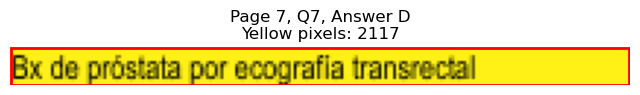

Page 7, Q7 - E: Detected box: x0=327.0, y0=606.9, x1=348.1, y1=619.6
Page 7, Q7, E: Yellow pixels: 68
Page 7, Q7, E: Total non-white pixels: 174
Page 7, Q7, E: Yellow percentage: 39.1%


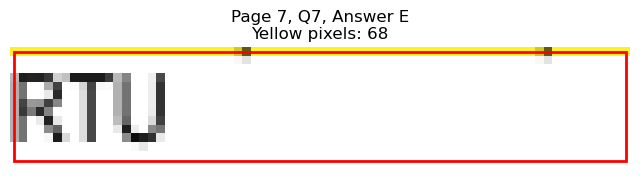


Page 7, Q7 - Selected Answer: D (based on yellow pixel count)




Page 7, Q8 - A: Detected box: x0=68.3, y0=682.7, x1=162.6, y1=695.3
Page 7, Q8, A: Yellow pixels: 1362
Page 7, Q8, A: Total non-white pixels: 2030
Page 7, Q8, A: Yellow percentage: 67.1%


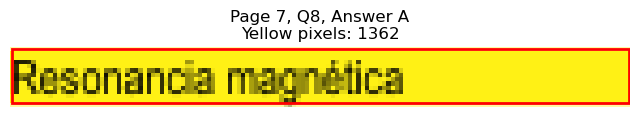

Page 7, Q8 - B: Detected box: x0=68.3, y0=695.4, x1=178.6, y1=708.0
Page 7, Q8, B: Yellow pixels: 1
Page 7, Q8, B: Total non-white pixels: 712
Page 7, Q8, B: Yellow percentage: 0.1%


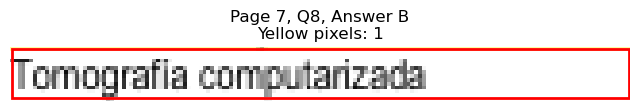

Page 7, Q8 - C: Detected box: x0=68.8, y0=708.0, x1=134.5, y1=720.6
Page 7, Q8, C: Yellow pixels: 0
Page 7, Q8, C: Total non-white pixels: 369
Page 7, Q8, C: Yellow percentage: 0.0%


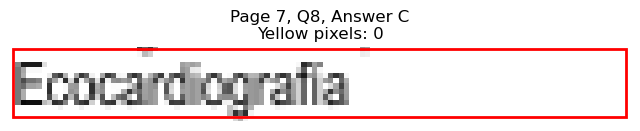

Page 7, Q8 - D: Detected box: x0=327.5, y0=682.7, x1=405.8, y1=695.3
Page 7, Q8, D: Yellow pixels: 0
Page 7, Q8, D: Total non-white pixels: 412
Page 7, Q8, D: Yellow percentage: 0.0%


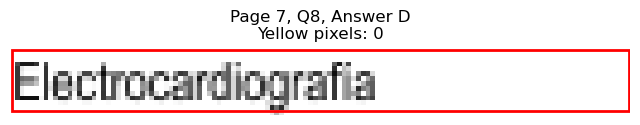

Page 7, Q8 - E: Detected box: x0=327.0, y0=695.4, x1=415.9, y1=708.0
Page 7, Q8, E: Yellow pixels: 0
Page 7, Q8, E: Total non-white pixels: 462
Page 7, Q8, E: Yellow percentage: 0.0%


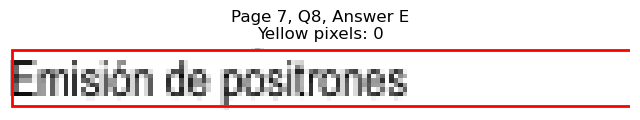


Page 7, Q8 - Selected Answer: A (based on yellow pixel count)





Page 8: Found 9 questions
Page 8, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=183.6, y1=102.1
Page 8, Q1, A: Yellow pixels: 0
Page 8, Q1, A: Total non-white pixels: 582
Page 8, Q1, A: Yellow percentage: 0.0%


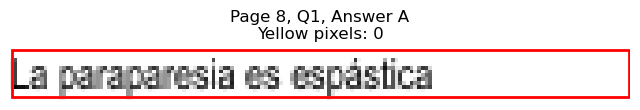

Page 8, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=230.3, y1=114.7
Page 8, Q1, B: Yellow pixels: 0
Page 8, Q1, B: Total non-white pixels: 784
Page 8, Q1, B: Yellow percentage: 0.0%


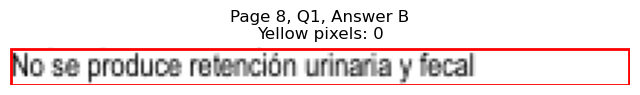

Page 8, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=122.4, y1=127.3
Page 8, Q1, C: Yellow pixels: 0
Page 8, Q1, C: Total non-white pixels: 264
Page 8, Q1, C: Yellow percentage: 0.0%


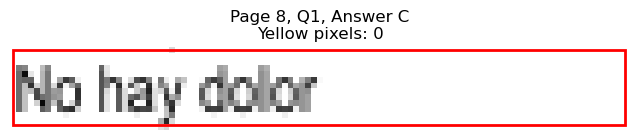

Page 8, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=465.1, y1=102.1
Page 8, Q1, D: Yellow pixels: 189
Page 8, Q1, D: Total non-white pixels: 854
Page 8, Q1, D: Yellow percentage: 22.1%


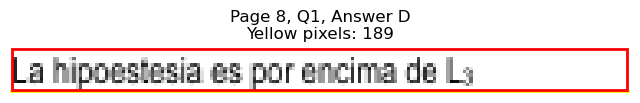

Page 8, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=440.9, y1=114.7
Page 8, Q1, E: Yellow pixels: 1709
Page 8, Q1, E: Total non-white pixels: 2132
Page 8, Q1, E: Yellow percentage: 80.2%


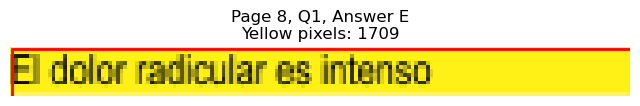


Page 8, Q1 - Selected Answer: E (based on yellow pixel count)




Page 8, Q2 - A: Detected box: x0=68.3, y0=152.5, x1=80.9, y1=165.2
Page 8, Q2, A: Yellow pixels: 0
Page 8, Q2, A: Total non-white pixels: 64
Page 8, Q2, A: Yellow percentage: 0.0%


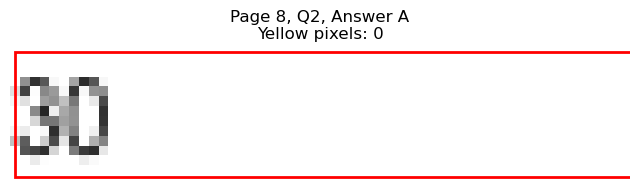

Page 8, Q2 - B: Detected box: x0=56.6, y0=165.1, x1=65.2, y1=177.8
Page 8, Q2, B: Yellow pixels: 0
Page 8, Q2, B: Total non-white pixels: 125
Page 8, Q2, B: Yellow percentage: 0.0%


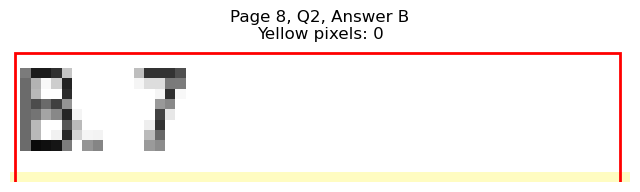

Page 8, Q2 - C: Detected box: x0=68.8, y0=177.7, x1=81.4, y1=190.4
Page 8, Q2, C: Yellow pixels: 735
Page 8, Q2, C: Total non-white pixels: 896
Page 8, Q2, C: Yellow percentage: 82.0%


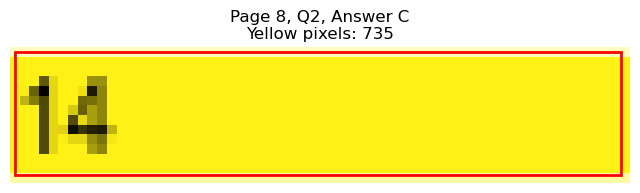

Page 8, Q2 - D: Detected box: x0=327.5, y0=152.5, x1=340.1, y1=165.2
Page 8, Q2, D: Yellow pixels: 0
Page 8, Q2, D: Total non-white pixels: 39
Page 8, Q2, D: Yellow percentage: 0.0%


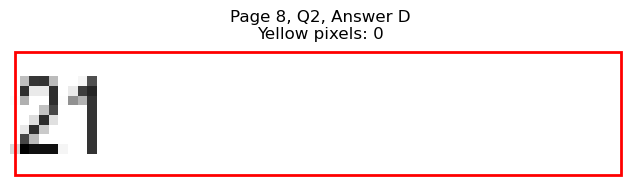

Page 8, Q2 - E: Detected box: x0=327.0, y0=165.1, x1=339.7, y1=177.8
Page 8, Q2, E: Yellow pixels: 0
Page 8, Q2, E: Total non-white pixels: 66
Page 8, Q2, E: Yellow percentage: 0.0%


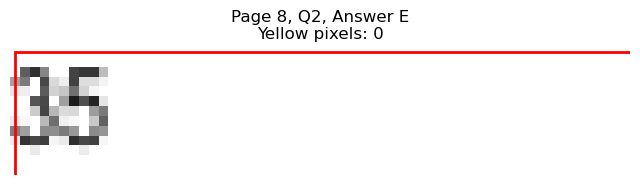


Page 8, Q2 - Selected Answer: C (based on yellow pixel count)




Page 8, Q3 - A: Detected box: x0=68.3, y0=240.9, x1=197.8, y1=253.5
Page 8, Q3, A: Yellow pixels: 0
Page 8, Q3, A: Total non-white pixels: 645
Page 8, Q3, A: Yellow percentage: 0.0%


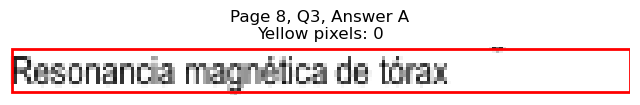

Page 8, Q3 - B: Detected box: x0=68.3, y0=253.5, x1=116.9, y1=266.1
Page 8, Q3, B: Yellow pixels: 99
Page 8, Q3, B: Total non-white pixels: 330
Page 8, Q3, B: Yellow percentage: 30.0%


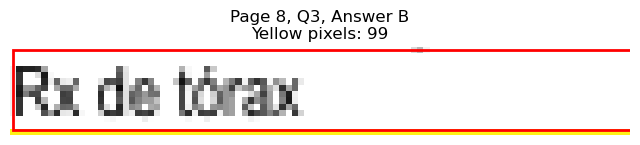

Page 8, Q3 - C: Detected box: x0=68.8, y0=266.1, x1=134.5, y1=278.7
Page 8, Q3, C: Yellow pixels: 1218
Page 8, Q3, C: Total non-white pixels: 1521
Page 8, Q3, C: Yellow percentage: 80.1%


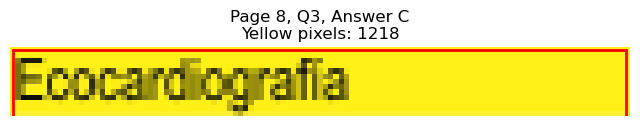

Page 8, Q3 - D: Detected box: x0=327.5, y0=240.9, x1=411.3, y1=253.5
Page 8, Q3, D: Yellow pixels: 0
Page 8, Q3, D: Total non-white pixels: 410
Page 8, Q3, D: Yellow percentage: 0.0%


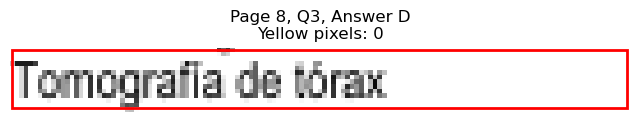

Page 8, Q3 - E: Detected box: x0=327.0, y0=253.5, x1=407.8, y1=266.1
Page 8, Q3, E: Yellow pixels: 0
Page 8, Q3, E: Total non-white pixels: 432
Page 8, Q3, E: Yellow percentage: 0.0%


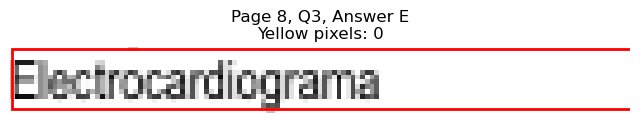


Page 8, Q3 - Selected Answer: C (based on yellow pixel count)




Page 8, Q4 - A: Detected box: x0=68.3, y0=304.0, x1=282.2, y1=316.7
Page 8, Q4, A: Yellow pixels: 0
Page 8, Q4, A: Total non-white pixels: 1105
Page 8, Q4, A: Yellow percentage: 0.0%


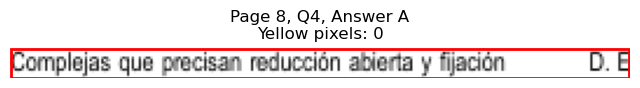

Page 8, Q4 - B: Detected box: x0=68.3, y0=329.2, x1=103.9, y1=341.9
Page 8, Q4, B: Yellow pixels: 971
Page 8, Q4, B: Total non-white pixels: 1118
Page 8, Q4, B: Yellow percentage: 86.9%


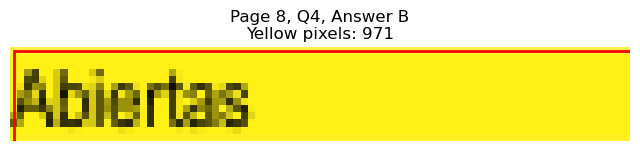

Page 8, Q4 - C: Detected box: x0=68.8, y0=341.9, x1=258.5, y1=354.6
Page 8, Q4, C: Yellow pixels: 213
Page 8, Q4, C: Total non-white pixels: 1195
Page 8, Q4, C: Yellow percentage: 17.8%


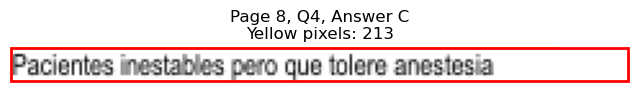

Page 8, Q4 - D: Detected box: x0=327.5, y0=304.0, x1=521.1, y1=316.7
Page 8, Q4, D: Yellow pixels: 0
Page 8, Q4, D: Total non-white pixels: 966
Page 8, Q4, D: Yellow percentage: 0.0%


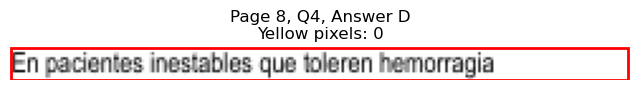

Page 8, Q4 - E: Detected box: x0=327.0, y0=316.6, x1=467.0, y1=329.3
Page 8, Q4, E: Yellow pixels: 0
Page 8, Q4, E: Total non-white pixels: 736
Page 8, Q4, E: Yellow percentage: 0.0%


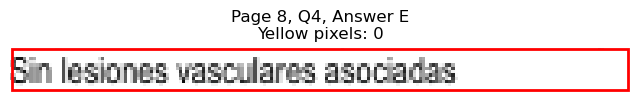


Page 8, Q4 - Selected Answer: B (based on yellow pixel count)




Page 8, Q5 - A: Detected box: x0=68.3, y0=392.3, x1=242.3, y1=405.0
Page 8, Q5, A: Yellow pixels: 0
Page 8, Q5, A: Total non-white pixels: 1055
Page 8, Q5, A: Yellow percentage: 0.0%


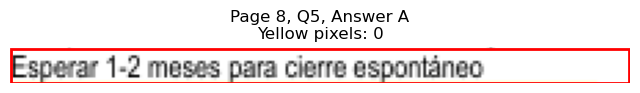

Page 8, Q5 - B: Detected box: x0=68.3, y0=404.9, x1=242.3, y1=417.6
Page 8, Q5, B: Yellow pixels: 2091
Page 8, Q5, B: Total non-white pixels: 2996
Page 8, Q5, B: Yellow percentage: 69.8%


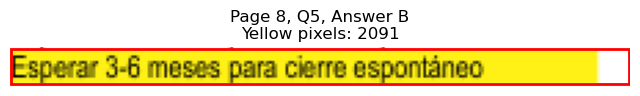

Page 8, Q5 - C: Detected box: x0=68.8, y0=417.6, x1=103.0, y1=430.3
Page 8, Q5, C: Yellow pixels: 85
Page 8, Q5, C: Total non-white pixels: 263
Page 8, Q5, C: Yellow percentage: 32.3%


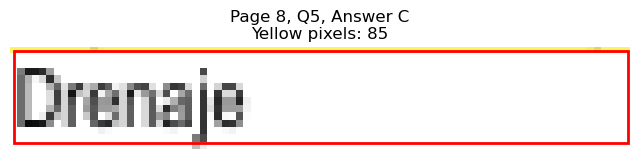

Page 8, Q5 - D: Detected box: x0=327.5, y0=392.3, x1=481.5, y1=405.0
Page 8, Q5, D: Yellow pixels: 0
Page 8, Q5, D: Total non-white pixels: 784
Page 8, Q5, D: Yellow percentage: 0.0%


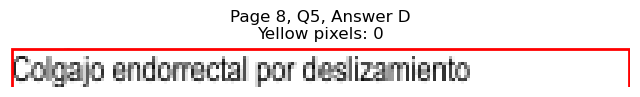

Page 8, Q5 - E: Detected box: x0=327.0, y0=404.9, x1=431.5, y1=417.6
Page 8, Q5, E: Yellow pixels: 0
Page 8, Q5, E: Total non-white pixels: 529
Page 8, Q5, E: Yellow percentage: 0.0%


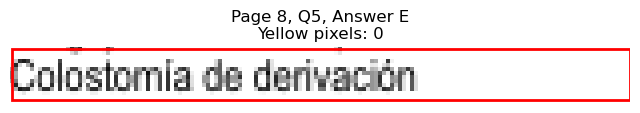


Page 8, Q5 - Selected Answer: B (based on yellow pixel count)




Page 8, Q6 - A: Detected box: x0=68.3, y0=468.1, x1=173.8, y1=480.7
Page 8, Q6, A: Yellow pixels: 0
Page 8, Q6, A: Total non-white pixels: 527
Page 8, Q6, A: Yellow percentage: 0.0%


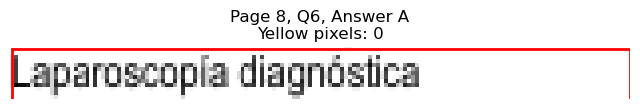

Page 8, Q6 - B: Detected box: x0=68.3, y0=480.8, x1=173.7, y1=493.4
Page 8, Q6, B: Yellow pixels: 156
Page 8, Q6, B: Total non-white pixels: 677
Page 8, Q6, B: Yellow percentage: 23.0%


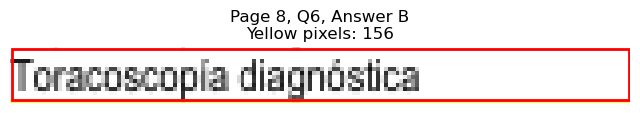

Page 8, Q6 - C: Detected box: x0=68.8, y0=493.4, x1=256.8, y1=506.0
Page 8, Q6, C: Yellow pixels: 2017
Page 8, Q6, C: Total non-white pixels: 2785
Page 8, Q6, C: Yellow percentage: 72.4%


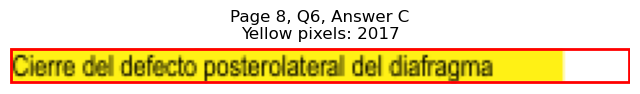

Page 8, Q6 - D: Detected box: x0=327.5, y0=468.1, x1=443.9, y1=480.7
Page 8, Q6, D: Yellow pixels: 0
Page 8, Q6, D: Total non-white pixels: 591
Page 8, Q6, D: Yellow percentage: 0.0%


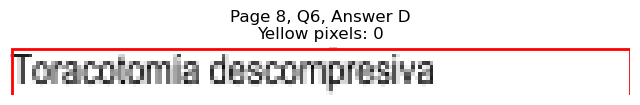

Page 8, Q6 - E: Detected box: x0=327.0, y0=480.8, x1=512.7, y1=493.4
Page 8, Q6, E: Yellow pixels: 0
Page 8, Q6, E: Total non-white pixels: 949
Page 8, Q6, E: Yellow percentage: 0.0%


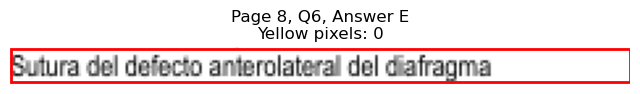


Page 8, Q6 - Selected Answer: C (based on yellow pixel count)




Page 8, Q7 - A: Detected box: x0=68.3, y0=569.1, x1=165.1, y1=581.8
Page 8, Q7, A: Yellow pixels: 0
Page 8, Q7, A: Total non-white pixels: 515
Page 8, Q7, A: Yellow percentage: 0.0%


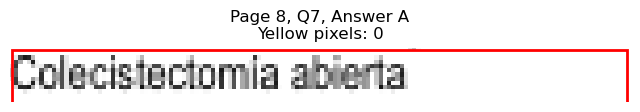

Page 8, Q7 - B: Detected box: x0=68.3, y0=581.7, x1=193.2, y1=594.4
Page 8, Q7, B: Yellow pixels: 0
Page 8, Q7, B: Total non-white pixels: 664
Page 8, Q7, B: Yellow percentage: 0.0%


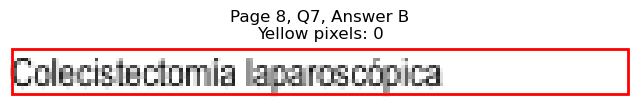

Page 8, Q7 - C: Detected box: x0=68.8, y0=594.3, x1=165.6, y1=607.0
Page 8, Q7, C: Yellow pixels: 0
Page 8, Q7, C: Total non-white pixels: 505
Page 8, Q7, C: Yellow percentage: 0.0%


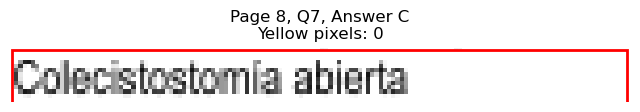

Page 8, Q7 - D: Detected box: x0=327.5, y0=569.1, x1=417.3, y1=581.8
Page 8, Q7, D: Yellow pixels: 0
Page 8, Q7, D: Total non-white pixels: 573
Page 8, Q7, D: Yellow percentage: 0.0%


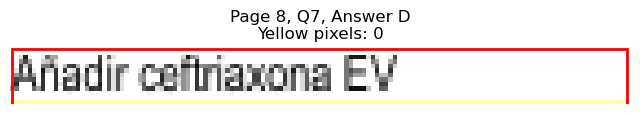

Page 8, Q7 - E: Detected box: x0=327.0, y0=581.7, x1=441.4, y1=594.4
Page 8, Q7, E: Yellow pixels: 1522
Page 8, Q7, E: Total non-white pixels: 2310
Page 8, Q7, E: Yellow percentage: 65.9%


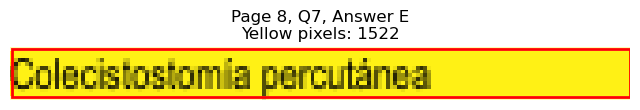


Page 8, Q7 - Selected Answer: E (based on yellow pixel count)




Page 8, Q8 - A: Detected box: x0=68.3, y0=632.2, x1=160.1, y1=644.9
Page 8, Q8, A: Yellow pixels: 0
Page 8, Q8, A: Total non-white pixels: 421
Page 8, Q8, A: Yellow percentage: 0.0%


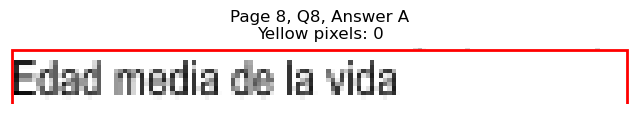

Page 8, Q8 - B: Detected box: x0=68.3, y0=644.9, x1=221.3, y1=657.5
Page 8, Q8, B: Yellow pixels: 0
Page 8, Q8, B: Total non-white pixels: 747
Page 8, Q8, B: Yellow percentage: 0.0%


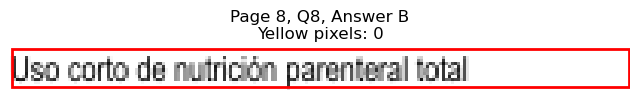

Page 8, Q8 - C: Detected box: x0=68.8, y0=657.5, x1=199.1, y1=670.1
Page 8, Q8, C: Yellow pixels: 0
Page 8, Q8, C: Total non-white pixels: 617
Page 8, Q8, C: Yellow percentage: 0.0%


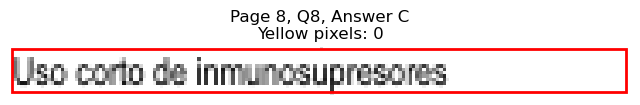

Page 8, Q8 - D: Detected box: x0=327.5, y0=632.2, x1=473.0, y1=644.9
Page 8, Q8, D: Yellow pixels: 0
Page 8, Q8, D: Total non-white pixels: 908
Page 8, Q8, D: Yellow percentage: 0.0%


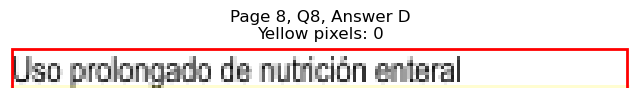

Page 8, Q8 - E: Detected box: x0=327.0, y0=644.9, x1=436.9, y1=657.5
Page 8, Q8, E: Yellow pixels: 1664
Page 8, Q8, E: Total non-white pixels: 2240
Page 8, Q8, E: Yellow percentage: 74.3%


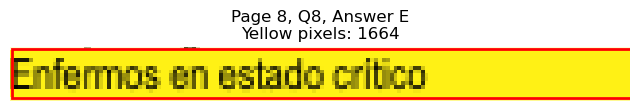


Page 8, Q8 - Selected Answer: E (based on yellow pixel count)




Page 8, Q9 - A: Detected box: x0=68.3, y0=720.6, x1=115.5, y1=733.2
Page 8, Q9, A: Yellow pixels: 0
Page 8, Q9, A: Total non-white pixels: 213
Page 8, Q9, A: Yellow percentage: 0.0%


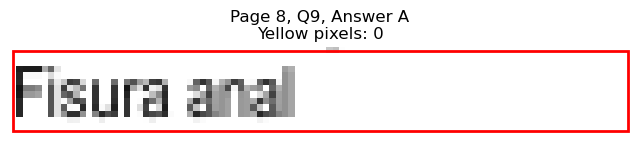

Page 8, Q9 - B: Detected box: x0=68.3, y0=733.2, x1=155.5, y1=745.8
Page 8, Q9, B: Yellow pixels: 0
Page 8, Q9, B: Total non-white pixels: 597
Page 8, Q9, B: Yellow percentage: 0.0%


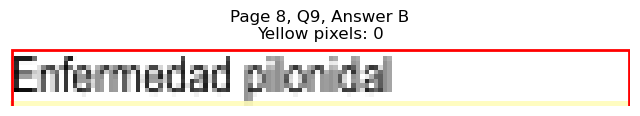

Page 8, Q9 - C: Detected box: x0=68.8, y0=745.8, x1=122.5, y1=758.4
Page 8, Q9, C: Yellow pixels: 1160
Page 8, Q9, C: Total non-white pixels: 1470
Page 8, Q9, C: Yellow percentage: 78.9%


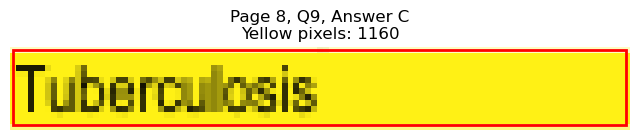

Page 8, Q9 - D: Detected box: x0=327.5, y0=720.6, x1=376.9, y1=733.2
Page 8, Q9, D: Yellow pixels: 0
Page 8, Q9, D: Total non-white pixels: 246
Page 8, Q9, D: Yellow percentage: 0.0%


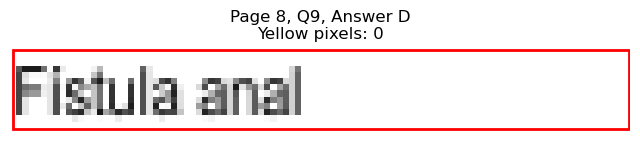

Page 8, Q9 - E: Detected box: x0=327.0, y0=733.2, x1=392.7, y1=745.8
Page 8, Q9, E: Yellow pixels: 0
Page 8, Q9, E: Total non-white pixels: 351
Page 8, Q9, E: Yellow percentage: 0.0%


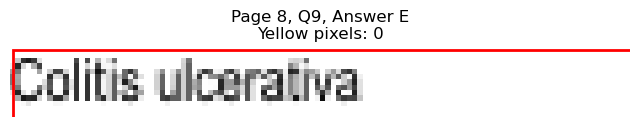


Page 8, Q9 - Selected Answer: C (based on yellow pixel count)





Page 9: Found 9 questions
Page 9, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=221.9, y1=102.1
Page 9, Q1, A: Yellow pixels: 0
Page 9, Q1, A: Total non-white pixels: 755
Page 9, Q1, A: Yellow percentage: 0.0%


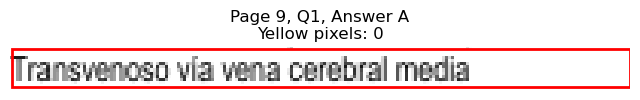

Page 9, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=274.5, y1=114.7
Page 9, Q1, B: Yellow pixels: 0
Page 9, Q1, B: Total non-white pixels: 1081
Page 9, Q1, B: Yellow percentage: 0.0%


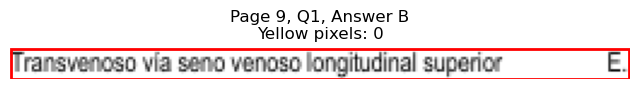

Page 9, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=241.4, y1=127.3
Page 9, Q1, C: Yellow pixels: 0
Page 9, Q1, C: Total non-white pixels: 823
Page 9, Q1, C: Yellow percentage: 0.0%


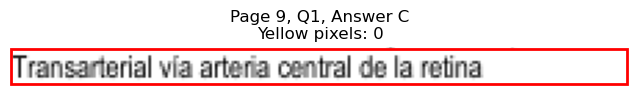

Page 9, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=492.6, y1=102.1
Page 9, Q1, D: Yellow pixels: 2116
Page 9, Q1, D: Total non-white pixels: 2995
Page 9, Q1, D: Yellow percentage: 70.7%


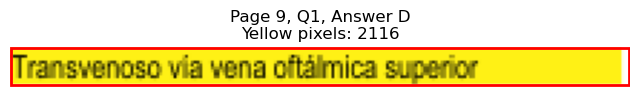

Page 9, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=475.5, y1=114.7
Page 9, Q1, E: Yellow pixels: 0
Page 9, Q1, E: Total non-white pixels: 959
Page 9, Q1, E: Yellow percentage: 0.0%


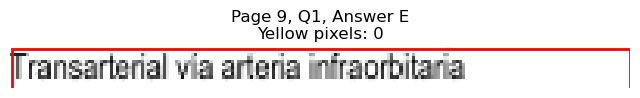


Page 9, Q1 - Selected Answer: D (based on yellow pixel count)




Page 9, Q2 - A: Detected box: x0=68.3, y0=177.7, x1=145.7, y1=190.4
Page 9, Q2, A: Yellow pixels: 0
Page 9, Q2, A: Total non-white pixels: 420
Page 9, Q2, A: Yellow percentage: 0.0%


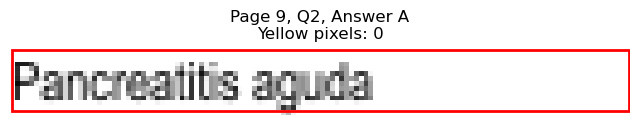

Page 9, Q2 - B: Detected box: x0=68.3, y0=190.3, x1=166.2, y1=203.0
Page 9, Q2, B: Yellow pixels: 0
Page 9, Q2, B: Total non-white pixels: 501
Page 9, Q2, B: Yellow percentage: 0.0%


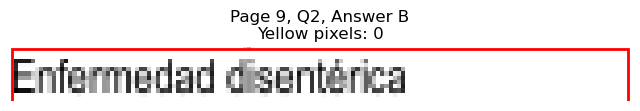

Page 9, Q2 - C: Detected box: x0=68.8, y0=202.9, x1=185.3, y1=215.6
Page 9, Q2, C: Yellow pixels: 0
Page 9, Q2, C: Total non-white pixels: 596
Page 9, Q2, C: Yellow percentage: 0.0%


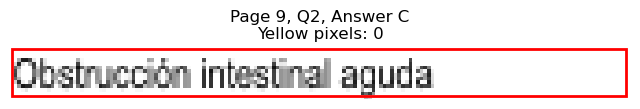

Page 9, Q2 - D: Detected box: x0=327.5, y0=177.7, x1=446.0, y1=190.4
Page 9, Q2, D: Yellow pixels: 1567
Page 9, Q2, D: Total non-white pixels: 2366
Page 9, Q2, D: Yellow percentage: 66.2%


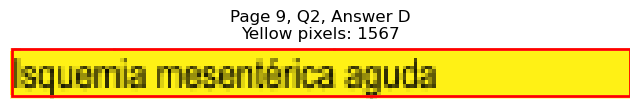

Page 9, Q2 - E: Detected box: x0=327.0, y0=190.3, x1=449.9, y1=203.0
Page 9, Q2, E: Yellow pixels: 3
Page 9, Q2, E: Total non-white pixels: 798
Page 9, Q2, E: Yellow percentage: 0.4%


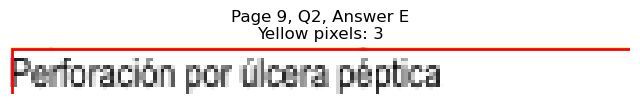


Page 9, Q2 - Selected Answer: D (based on yellow pixel count)




Page 9, Q3 - A: Detected box: x0=68.3, y0=240.9, x1=187.8, y1=253.5
Page 9, Q3, A: Yellow pixels: 0
Page 9, Q3, A: Total non-white pixels: 629
Page 9, Q3, A: Yellow percentage: 0.0%


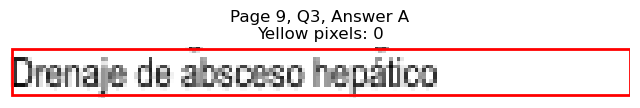

Page 9, Q3 - B: Detected box: x0=68.3, y0=253.5, x1=180.1, y1=266.1
Page 9, Q3, B: Yellow pixels: 0
Page 9, Q3, B: Total non-white pixels: 564
Page 9, Q3, B: Yellow percentage: 0.0%


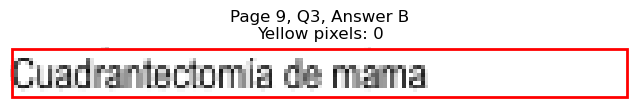

Page 9, Q3 - C: Detected box: x0=68.8, y0=266.1, x1=157.6, y1=278.7
Page 9, Q3, C: Yellow pixels: 0
Page 9, Q3, C: Total non-white pixels: 475
Page 9, Q3, C: Yellow percentage: 0.0%


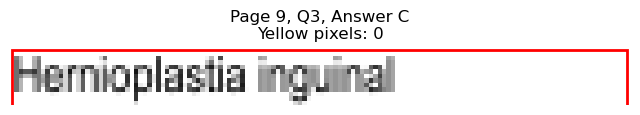

Page 9, Q3 - D: Detected box: x0=327.5, y0=240.9, x1=380.3, y1=253.5
Page 9, Q3, D: Yellow pixels: 104
Page 9, Q3, D: Total non-white pixels: 373
Page 9, Q3, D: Yellow percentage: 27.9%


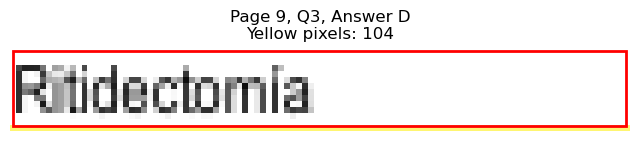

Page 9, Q3 - E: Detected box: x0=327.0, y0=253.5, x1=417.9, y1=266.1
Page 9, Q3, E: Yellow pixels: 1450
Page 9, Q3, E: Total non-white pixels: 1974
Page 9, Q3, E: Yellow percentage: 73.5%


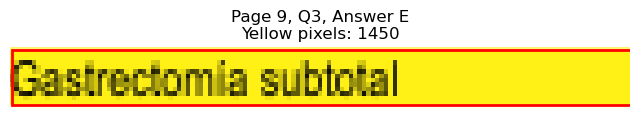


Page 9, Q3 - Selected Answer: E (based on yellow pixel count)




Page 9, Q4 - A: Detected box: x0=68.3, y0=341.9, x1=215.3, y1=354.6
Page 9, Q4, A: Yellow pixels: 2001
Page 9, Q4, A: Total non-white pixels: 2772
Page 9, Q4, A: Yellow percentage: 72.2%


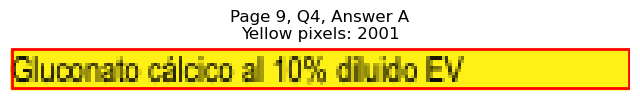

Page 9, Q4 - B: Detected box: x0=68.3, y0=354.5, x1=221.3, y1=367.2
Page 9, Q4, B: Yellow pixels: 204
Page 9, Q4, B: Total non-white pixels: 946
Page 9, Q4, B: Yellow percentage: 21.6%


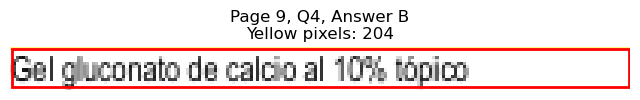

Page 9, Q4 - C: Detected box: x0=68.8, y0=367.1, x1=155.1, y1=379.8
Page 9, Q4, C: Yellow pixels: 0
Page 9, Q4, C: Total non-white pixels: 449
Page 9, Q4, C: Yellow percentage: 0.0%


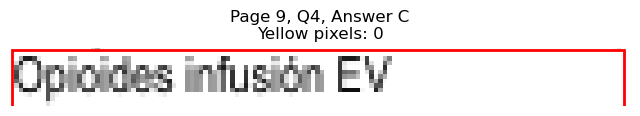

Page 9, Q4 - D: Detected box: x0=327.5, y0=341.9, x1=446.9, y1=354.6
Page 9, Q4, D: Yellow pixels: 0
Page 9, Q4, D: Total non-white pixels: 596
Page 9, Q4, D: Yellow percentage: 0.0%


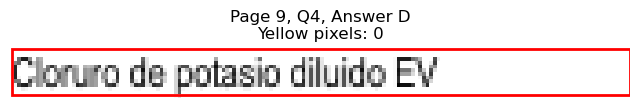

Page 9, Q4 - E: Detected box: x0=327.0, y0=354.5, x1=416.9, y1=367.2
Page 9, Q4, E: Yellow pixels: 0
Page 9, Q4, E: Total non-white pixels: 462
Page 9, Q4, E: Yellow percentage: 0.0%


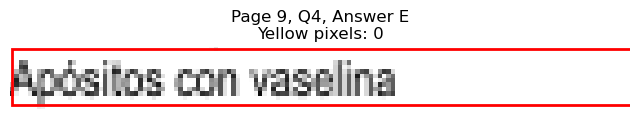


Page 9, Q4 - Selected Answer: A (based on yellow pixel count)




Page 9, Q5 - A: Detected box: x0=68.3, y0=430.2, x1=155.1, y1=442.9
Page 9, Q5, A: Yellow pixels: 0
Page 9, Q5, A: Total non-white pixels: 420
Page 9, Q5, A: Yellow percentage: 0.0%


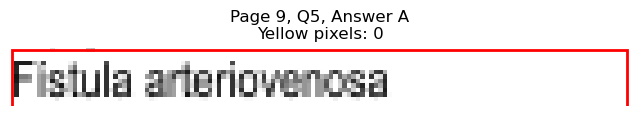

Page 9, Q5 - B: Detected box: x0=68.3, y0=442.8, x1=182.2, y1=455.5
Page 9, Q5, B: Yellow pixels: 0
Page 9, Q5, B: Total non-white pixels: 565
Page 9, Q5, B: Yellow percentage: 0.0%


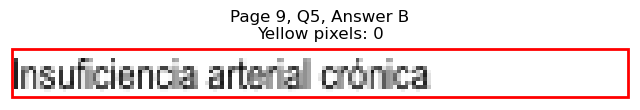

Page 9, Q5 - C: Detected box: x0=68.8, y0=455.5, x1=183.1, y1=468.1
Page 9, Q5, C: Yellow pixels: 0
Page 9, Q5, C: Total non-white pixels: 534
Page 9, Q5, C: Yellow percentage: 0.0%


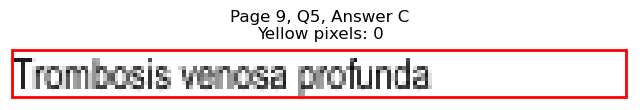

Page 9, Q5 - D: Detected box: x0=327.5, y0=430.2, x1=424.4, y1=442.9
Page 9, Q5, D: Yellow pixels: 0
Page 9, Q5, D: Total non-white pixels: 632
Page 9, Q5, D: Yellow percentage: 0.0%


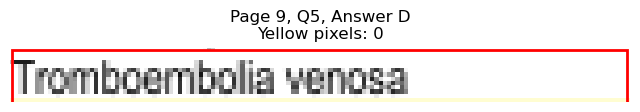

Page 9, Q5 - E: Detected box: x0=327.0, y0=442.8, x1=442.4, y1=455.5
Page 9, Q5, E: Yellow pixels: 1737
Page 9, Q5, E: Total non-white pixels: 2324
Page 9, Q5, E: Yellow percentage: 74.7%


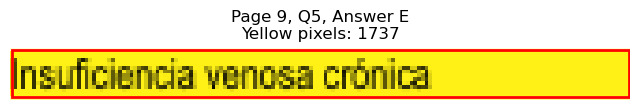


Page 9, Q5 - Selected Answer: E (based on yellow pixel count)




Page 9, Q6 - A: Detected box: x0=68.3, y0=493.4, x1=162.7, y1=506.0
Page 9, Q6, A: Yellow pixels: 0
Page 9, Q6, A: Total non-white pixels: 484
Page 9, Q6, A: Yellow percentage: 0.0%


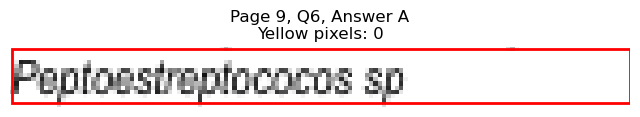

Page 9, Q6 - B: Detected box: x0=68.3, y0=506.0, x1=131.5, y1=518.6
Page 9, Q6, B: Yellow pixels: 114
Page 9, Q6, B: Total non-white pixels: 426
Page 9, Q6, B: Yellow percentage: 26.8%


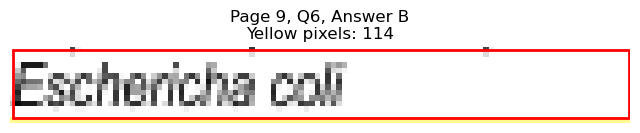

Page 9, Q6 - C: Detected box: x0=68.8, y0=518.6, x1=174.6, y1=531.2
Page 9, Q6, C: Yellow pixels: 1607
Page 9, Q6, C: Total non-white pixels: 2198
Page 9, Q6, C: Yellow percentage: 73.1%


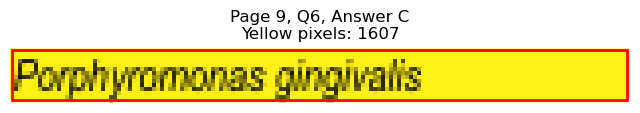

Page 9, Q6 - D: Detected box: x0=327.5, y0=493.4, x1=380.7, y1=506.0
Page 9, Q6, D: Yellow pixels: 0
Page 9, Q6, D: Total non-white pixels: 276
Page 9, Q6, D: Yellow percentage: 0.0%


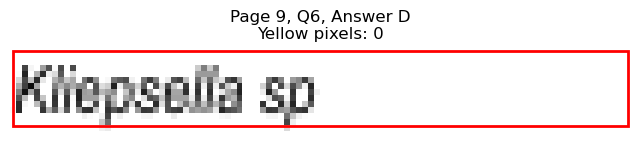

Page 9, Q6 - E: Detected box: x0=327.0, y0=506.0, x1=405.9, y1=518.6
Page 9, Q6, E: Yellow pixels: 0
Page 9, Q6, E: Total non-white pixels: 436
Page 9, Q6, E: Yellow percentage: 0.0%


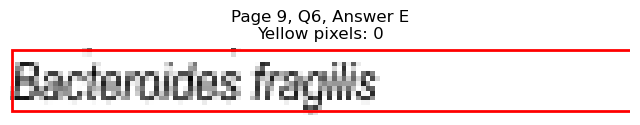


Page 9, Q6 - Selected Answer: C (based on yellow pixel count)




Page 9, Q7 - A: Detected box: x0=68.3, y0=556.5, x1=161.1, y1=569.2
Page 9, Q7, A: Yellow pixels: 0
Page 9, Q7, A: Total non-white pixels: 482
Page 9, Q7, A: Yellow percentage: 0.0%


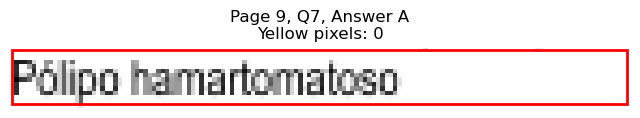

Page 9, Q7 - B: Detected box: x0=68.3, y0=569.1, x1=139.6, y1=581.8
Page 9, Q7, B: Yellow pixels: 0
Page 9, Q7, B: Total non-white pixels: 372
Page 9, Q7, B: Yellow percentage: 0.0%


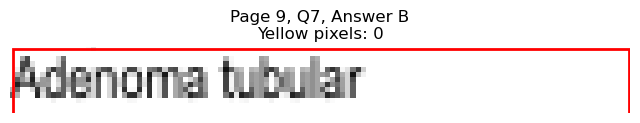

Page 9, Q7 - C: Detected box: x0=68.8, y0=581.7, x1=147.0, y1=594.4
Page 9, Q7, C: Yellow pixels: 0
Page 9, Q7, C: Total non-white pixels: 394
Page 9, Q7, C: Yellow percentage: 0.0%


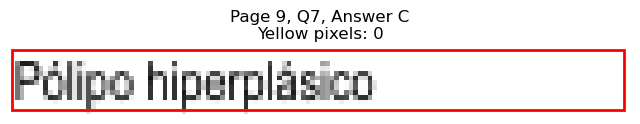

Page 9, Q7 - D: Detected box: x0=327.5, y0=556.5, x1=399.3, y1=569.2
Page 9, Q7, D: Yellow pixels: 1329
Page 9, Q7, D: Total non-white pixels: 1722
Page 9, Q7, D: Yellow percentage: 77.2%


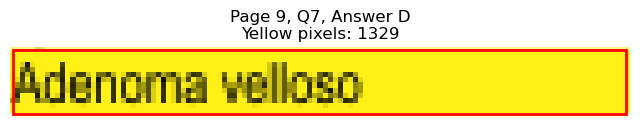

Page 9, Q7 - E: Detected box: x0=327.0, y0=569.1, x1=403.7, y1=581.8
Page 9, Q7, E: Yellow pixels: 0
Page 9, Q7, E: Total non-white pixels: 544
Page 9, Q7, E: Yellow percentage: 0.0%


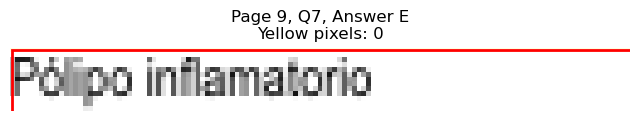


Page 9, Q7 - Selected Answer: D (based on yellow pixel count)




Page 9, Q8 - A: Detected box: x0=68.3, y0=632.2, x1=168.3, y1=644.9
Page 9, Q8, A: Yellow pixels: 0
Page 9, Q8, A: Total non-white pixels: 496
Page 9, Q8, A: Yellow percentage: 0.0%


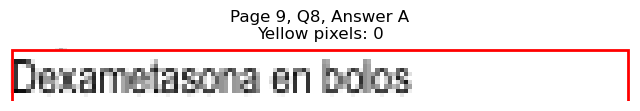

Page 9, Q8 - B: Detected box: x0=68.3, y0=644.9, x1=173.2, y1=657.5
Page 9, Q8, B: Yellow pixels: 156
Page 9, Q8, B: Total non-white pixels: 693
Page 9, Q8, B: Yellow percentage: 22.5%


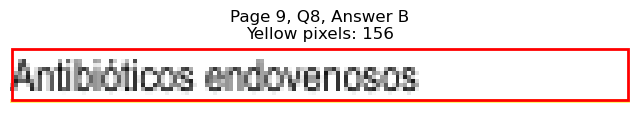

Page 9, Q8 - C: Detected box: x0=68.8, y0=657.5, x1=168.3, y1=670.1
Page 9, Q8, C: Yellow pixels: 1571
Page 9, Q8, C: Total non-white pixels: 2114
Page 9, Q8, C: Yellow percentage: 74.3%


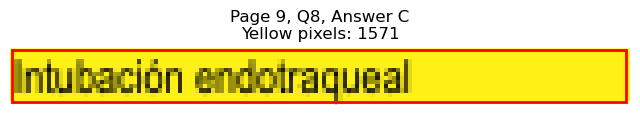

Page 9, Q8 - D: Detected box: x0=327.5, y0=632.2, x1=395.2, y1=644.9
Page 9, Q8, D: Yellow pixels: 0
Page 9, Q8, D: Total non-white pixels: 331
Page 9, Q8, D: Yellow percentage: 0.0%


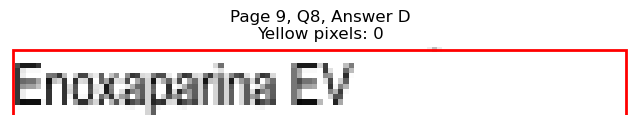

Page 9, Q8 - E: Detected box: x0=327.0, y0=644.9, x1=434.0, y1=657.5
Page 9, Q8, E: Yellow pixels: 0
Page 9, Q8, E: Total non-white pixels: 523
Page 9, Q8, E: Yellow percentage: 0.0%


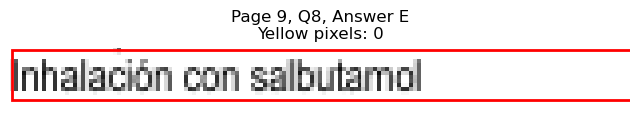


Page 9, Q8 - Selected Answer: C (based on yellow pixel count)




Page 9, Q9 - A: Detected box: x0=68.3, y0=708.0, x1=200.8, y1=720.6
Page 9, Q9, A: Yellow pixels: 183
Page 9, Q9, A: Total non-white pixels: 863
Page 9, Q9, A: Yellow percentage: 21.2%


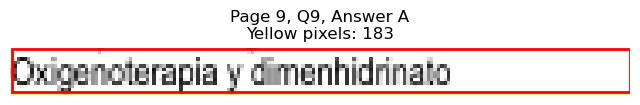

Page 9, Q9 - B: Detected box: x0=68.3, y0=720.6, x1=245.0, y1=733.2
Page 9, Q9, B: Yellow pixels: 2103
Page 9, Q9, B: Total non-white pixels: 2996
Page 9, Q9, B: Yellow percentage: 70.2%


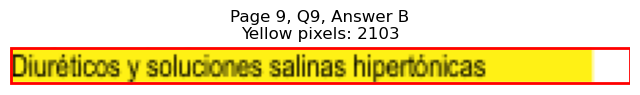

Page 9, Q9 - C: Detected box: x0=68.8, y0=733.2, x1=186.6, y1=745.8
Page 9, Q9, C: Yellow pixels: 0
Page 9, Q9, C: Total non-white pixels: 753
Page 9, Q9, C: Yellow percentage: 0.0%


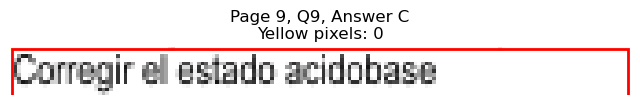

Page 9, Q9 - D: Detected box: x0=327.5, y0=708.0, x1=443.3, y1=720.6
Page 9, Q9, D: Yellow pixels: 0
Page 9, Q9, D: Total non-white pixels: 576
Page 9, Q9, D: Yellow percentage: 0.0%


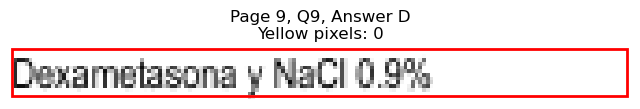

Page 9, Q9 - E: Detected box: x0=327.0, y0=720.6, x1=437.4, y1=733.2
Page 9, Q9, E: Yellow pixels: 0
Page 9, Q9, E: Total non-white pixels: 557
Page 9, Q9, E: Yellow percentage: 0.0%


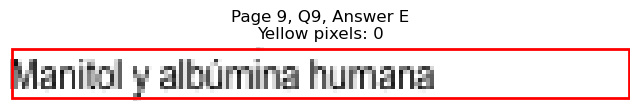


Page 9, Q9 - Selected Answer: B (based on yellow pixel count)





Page 10: Found 9 questions
Page 10, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=145.7, y1=102.1
Page 10, Q1, A: Yellow pixels: 128
Page 10, Q1, A: Total non-white pixels: 476
Page 10, Q1, A: Yellow percentage: 26.9%


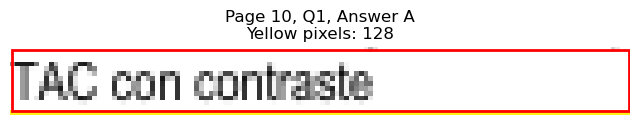

Page 10, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=162.7, y1=114.7
Page 10, Q1, B: Yellow pixels: 1505
Page 10, Q1, B: Total non-white pixels: 1885
Page 10, Q1, B: Yellow percentage: 79.8%


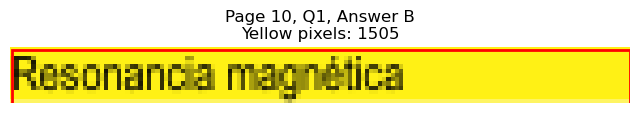

Page 10, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=142.6, y1=127.3
Page 10, Q1, C: Yellow pixels: 124
Page 10, Q1, C: Total non-white pixels: 515
Page 10, Q1, C: Yellow percentage: 24.1%


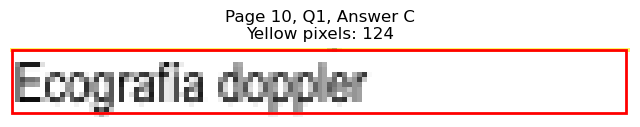

Page 10, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=374.8, y1=102.1
Page 10, Q1, D: Yellow pixels: 0
Page 10, Q1, D: Total non-white pixels: 266
Page 10, Q1, D: Yellow percentage: 0.0%


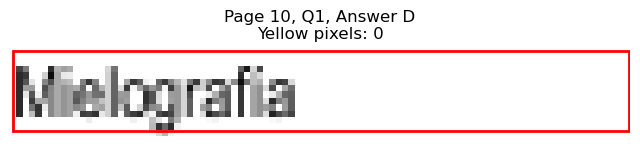

Page 10, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=414.9, y1=114.7
Page 10, Q1, E: Yellow pixels: 0
Page 10, Q1, E: Total non-white pixels: 443
Page 10, Q1, E: Yellow percentage: 0.0%


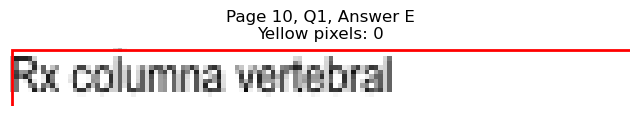


Page 10, Q1 - Selected Answer: B (based on yellow pixel count)




Page 10, Q2 - A: Detected box: x0=68.3, y0=177.7, x1=147.6, y1=190.4
Page 10, Q2, A: Yellow pixels: 0
Page 10, Q2, A: Total non-white pixels: 380
Page 10, Q2, A: Yellow percentage: 0.0%


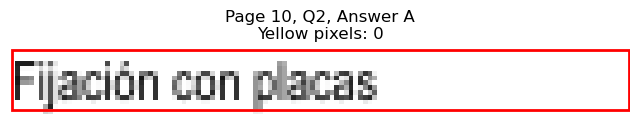

Page 10, Q2 - B: Detected box: x0=68.3, y0=190.3, x1=175.7, y1=203.0
Page 10, Q2, B: Yellow pixels: 0
Page 10, Q2, B: Total non-white pixels: 527
Page 10, Q2, B: Yellow percentage: 0.0%


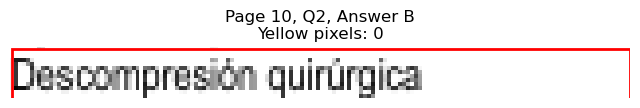

Page 10, Q2 - C: Detected box: x0=68.8, y0=202.9, x1=121.5, y1=215.6
Page 10, Q2, C: Yellow pixels: 0
Page 10, Q2, C: Total non-white pixels: 522
Page 10, Q2, C: Yellow percentage: 0.0%


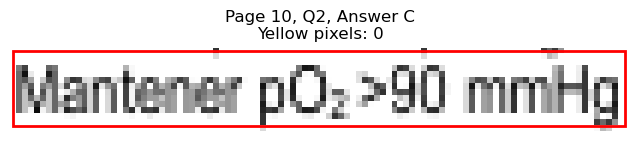

Page 10, Q2 - D: Detected box: x0=327.5, y0=177.7, x1=435.3, y1=190.4
Page 10, Q2, D: Yellow pixels: 159
Page 10, Q2, D: Total non-white pixels: 696
Page 10, Q2, D: Yellow percentage: 22.8%


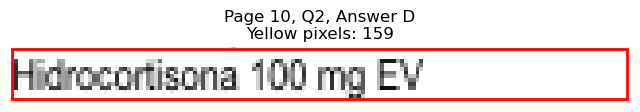

Page 10, Q2 - E: Detected box: x0=327.0, y0=190.3, x1=397.4, y1=203.0
Page 10, Q2, E: Yellow pixels: 1328
Page 10, Q2, E: Total non-white pixels: 1573
Page 10, Q2, E: Yellow percentage: 84.4%


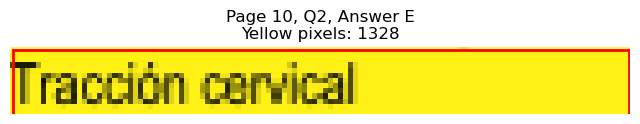


Page 10, Q2 - Selected Answer: E (based on yellow pixel count)




Page 10, Q3 - A: Detected box: x0=68.3, y0=240.9, x1=114.5, y1=253.5
Page 10, Q3, A: Yellow pixels: 0
Page 10, Q3, A: Total non-white pixels: 233
Page 10, Q3, A: Yellow percentage: 0.0%


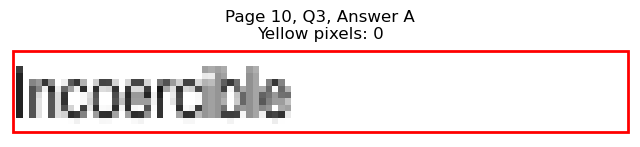

Page 10, Q3 - B: Detected box: x0=68.3, y0=253.5, x1=109.0, y1=266.1
Page 10, Q3, B: Yellow pixels: 0
Page 10, Q3, B: Total non-white pixels: 191
Page 10, Q3, B: Yellow percentage: 0.0%


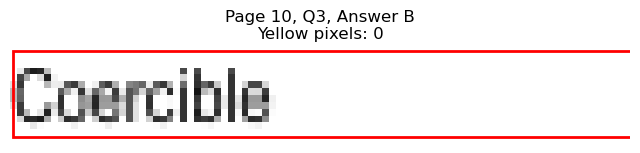

Page 10, Q3 - C: Detected box: x0=68.8, y0=266.1, x1=92.9, y1=278.7
Page 10, Q3, C: Yellow pixels: 0
Page 10, Q3, C: Total non-white pixels: 130
Page 10, Q3, C: Yellow percentage: 0.0%


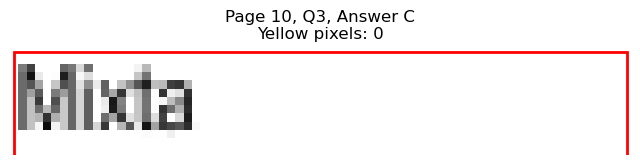

Page 10, Q3 - D: Detected box: x0=327.5, y0=240.9, x1=369.7, y1=253.5
Page 10, Q3, D: Yellow pixels: 1037
Page 10, Q3, D: Total non-white pixels: 1302
Page 10, Q3, D: Yellow percentage: 79.6%


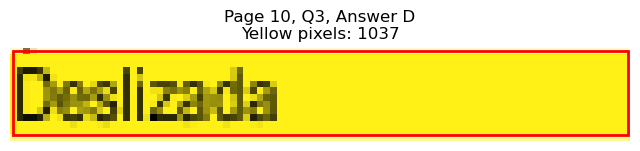

Page 10, Q3 - E: Detected box: x0=327.0, y0=253.5, x1=374.2, y1=266.1
Page 10, Q3, E: Yellow pixels: 98
Page 10, Q3, E: Total non-white pixels: 358
Page 10, Q3, E: Yellow percentage: 27.4%


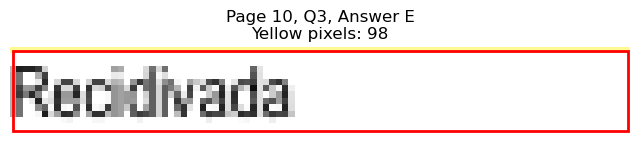


Page 10, Q3 - Selected Answer: D (based on yellow pixel count)




Page 10, Q4 - A: Detected box: x0=68.3, y0=329.2, x1=162.6, y1=341.9
Page 10, Q4, A: Yellow pixels: 0
Page 10, Q4, A: Total non-white pixels: 476
Page 10, Q4, A: Yellow percentage: 0.0%


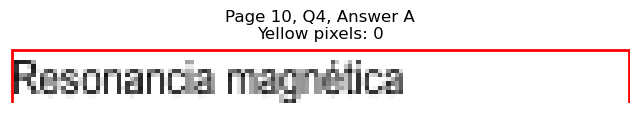

Page 10, Q4 - B: Detected box: x0=68.3, y0=341.9, x1=183.1, y1=354.6
Page 10, Q4, B: Yellow pixels: 1762
Page 10, Q4, B: Total non-white pixels: 2324
Page 10, Q4, B: Yellow percentage: 75.8%


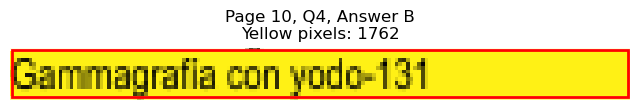

Page 10, Q4 - C: Detected box: x0=68.8, y0=354.5, x1=142.0, y1=367.2
Page 10, Q4, C: Yellow pixels: 122
Page 10, Q4, C: Total non-white pixels: 487
Page 10, Q4, C: Yellow percentage: 25.1%


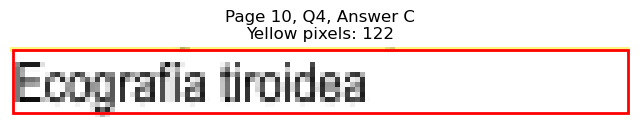

Page 10, Q4 - D: Detected box: x0=327.5, y0=329.2, x1=483.6, y1=341.9
Page 10, Q4, D: Yellow pixels: 0
Page 10, Q4, D: Total non-white pixels: 763
Page 10, Q4, D: Yellow percentage: 0.0%


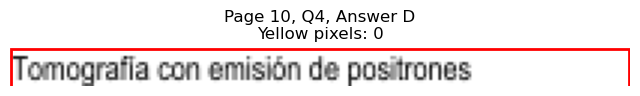

Page 10, Q4 - E: Detected box: x0=327.0, y0=341.9, x1=429.4, y1=354.6
Page 10, Q4, E: Yellow pixels: 0
Page 10, Q4, E: Total non-white pixels: 502
Page 10, Q4, E: Yellow percentage: 0.0%


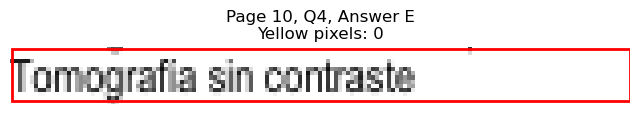


Page 10, Q4 - Selected Answer: B (based on yellow pixel count)




Page 10, Q5 - A: Detected box: x0=68.3, y0=392.3, x1=120.6, y1=405.0
Page 10, Q5, A: Yellow pixels: 0
Page 10, Q5, A: Total non-white pixels: 288
Page 10, Q5, A: Yellow percentage: 0.0%


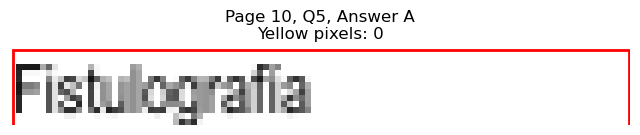

Page 10, Q5 - B: Detected box: x0=68.3, y0=404.9, x1=120.6, y1=417.6
Page 10, Q5, B: Yellow pixels: 0
Page 10, Q5, B: Total non-white pixels: 269
Page 10, Q5, B: Yellow percentage: 0.0%


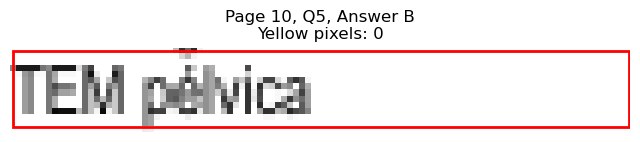

Page 10, Q5 - C: Detected box: x0=68.8, y0=417.6, x1=153.6, y1=430.3
Page 10, Q5, C: Yellow pixels: 0
Page 10, Q5, C: Total non-white pixels: 387
Page 10, Q5, C: Yellow percentage: 0.0%


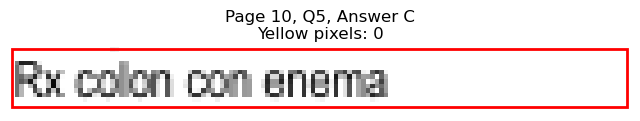

Page 10, Q5 - D: Detected box: x0=327.5, y0=392.3, x1=381.8, y1=405.0
Page 10, Q5, D: Yellow pixels: 0
Page 10, Q5, D: Total non-white pixels: 397
Page 10, Q5, D: Yellow percentage: 0.0%


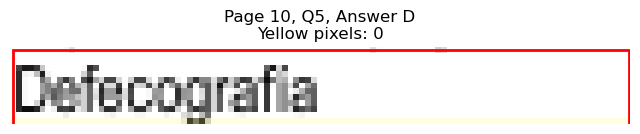

Page 10, Q5 - E: Detected box: x0=327.0, y0=404.9, x1=380.7, y1=417.6
Page 10, Q5, E: Yellow pixels: 1113
Page 10, Q5, E: Total non-white pixels: 1456
Page 10, Q5, E: Yellow percentage: 76.4%


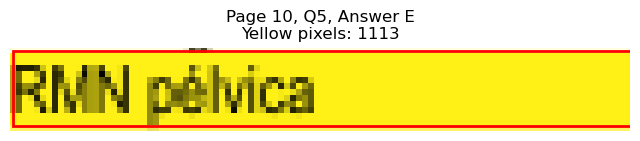


Page 10, Q5 - Selected Answer: E (based on yellow pixel count)




Page 10, Q6 - A: Detected box: x0=68.3, y0=480.8, x1=125.1, y1=493.4
Page 10, Q6, A: Yellow pixels: 0
Page 10, Q6, A: Total non-white pixels: 283
Page 10, Q6, A: Yellow percentage: 0.0%


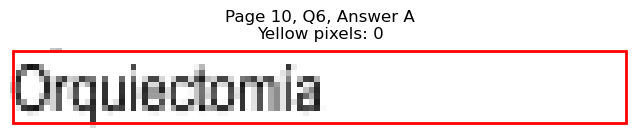

Page 10, Q6 - B: Detected box: x0=68.3, y0=493.4, x1=128.4, y1=506.0
Page 10, Q6, B: Yellow pixels: 0
Page 10, Q6, B: Total non-white pixels: 314
Page 10, Q6, B: Yellow percentage: 0.0%


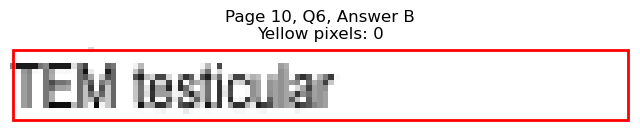

Page 10, Q6 - C: Detected box: x0=68.8, y0=506.0, x1=127.1, y1=518.6
Page 10, Q6, C: Yellow pixels: 0
Page 10, Q6, C: Total non-white pixels: 315
Page 10, Q6, C: Yellow percentage: 0.0%


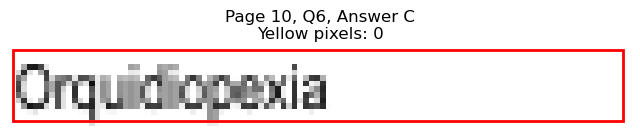

Page 10, Q6 - D: Detected box: x0=327.5, y0=480.8, x1=401.2, y1=493.4
Page 10, Q6, D: Yellow pixels: 1209
Page 10, Q6, D: Total non-white pixels: 1750
Page 10, Q6, D: Yellow percentage: 69.1%


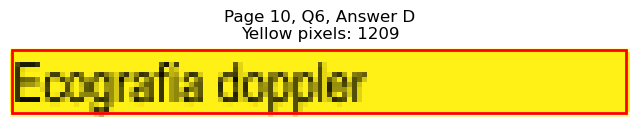

Page 10, Q6 - E: Detected box: x0=327.0, y0=493.4, x1=388.7, y1=506.0
Page 10, Q6, E: Yellow pixels: 3
Page 10, Q6, E: Total non-white pixels: 441
Page 10, Q6, E: Yellow percentage: 0.7%


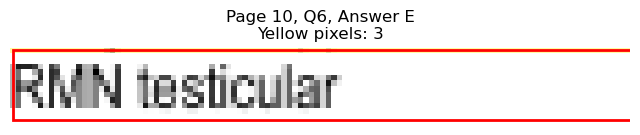


Page 10, Q6 - Selected Answer: D (based on yellow pixel count)




Page 10, Q7 - A: Detected box: x0=68.3, y0=556.5, x1=163.6, y1=569.2
Page 10, Q7, A: Yellow pixels: 0
Page 10, Q7, A: Total non-white pixels: 473
Page 10, Q7, A: Yellow percentage: 0.0%


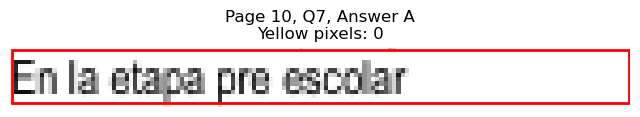

Page 10, Q7 - B: Detected box: x0=68.3, y0=569.1, x1=123.0, y1=581.8
Page 10, Q7, B: Yellow pixels: 0
Page 10, Q7, B: Total non-white pixels: 258
Page 10, Q7, B: Yellow percentage: 0.0%


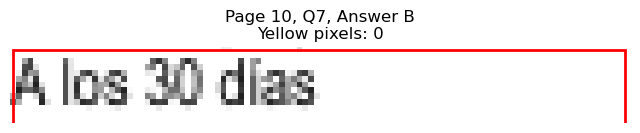

Page 10, Q7 - C: Detected box: x0=68.8, y0=581.7, x1=128.1, y1=594.4
Page 10, Q7, C: Yellow pixels: 0
Page 10, Q7, C: Total non-white pixels: 266
Page 10, Q7, C: Yellow percentage: 0.0%


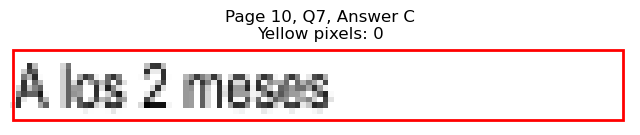

Page 10, Q7 - D: Detected box: x0=327.5, y0=556.5, x1=420.9, y1=569.2
Page 10, Q7, D: Yellow pixels: 1522
Page 10, Q7, D: Total non-white pixels: 2016
Page 10, Q7, D: Yellow percentage: 75.5%


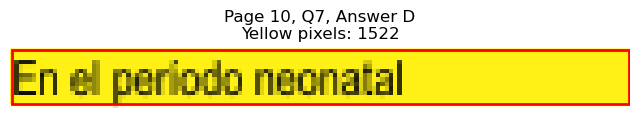

Page 10, Q7 - E: Detected box: x0=327.0, y0=569.1, x1=355.1, y1=581.8
Page 10, Q7, E: Yellow pixels: 0
Page 10, Q7, E: Total non-white pixels: 207
Page 10, Q7, E: Yellow percentage: 0.0%


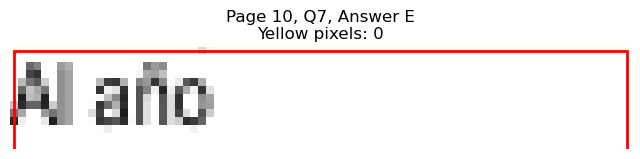


Page 10, Q7 - Selected Answer: D (based on yellow pixel count)




Page 10, Q8 - A: Detected box: x0=68.3, y0=644.9, x1=91.9, y1=657.5
Page 10, Q8, A: Yellow pixels: 0
Page 10, Q8, A: Total non-white pixels: 109
Page 10, Q8, A: Yellow percentage: 0.0%


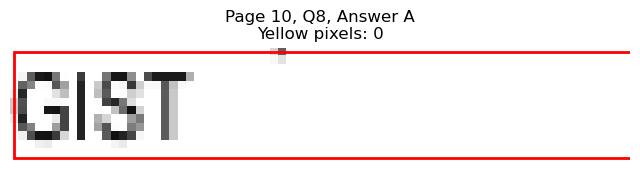

Page 10, Q8 - B: Detected box: x0=68.3, y0=657.5, x1=189.6, y1=670.1
Page 10, Q8, B: Yellow pixels: 172
Page 10, Q8, B: Total non-white pixels: 797
Page 10, Q8, B: Yellow percentage: 21.6%


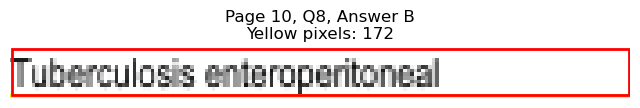

Page 10, Q8 - C: Detected box: x0=68.8, y0=670.1, x1=160.2, y1=682.7
Page 10, Q8, C: Yellow pixels: 1509
Page 10, Q8, C: Total non-white pixels: 1859
Page 10, Q8, C: Yellow percentage: 81.2%


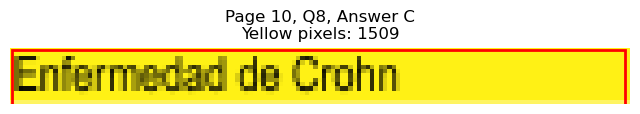

Page 10, Q8 - D: Detected box: x0=327.5, y0=644.9, x1=395.7, y1=657.5
Page 10, Q8, D: Yellow pixels: 0
Page 10, Q8, D: Total non-white pixels: 353
Page 10, Q8, D: Yellow percentage: 0.0%


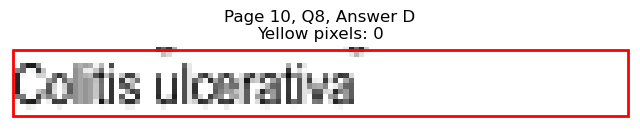

Page 10, Q8 - E: Detected box: x0=327.0, y0=657.5, x1=425.0, y1=670.1
Page 10, Q8, E: Yellow pixels: 0
Page 10, Q8, E: Total non-white pixels: 514
Page 10, Q8, E: Yellow percentage: 0.0%


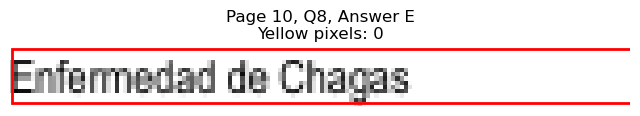


Page 10, Q8 - Selected Answer: C (based on yellow pixel count)




Page 10, Q9 - A: Detected box: x0=68.3, y0=708.0, x1=213.4, y1=720.6
Page 10, Q9, A: Yellow pixels: 196
Page 10, Q9, A: Total non-white pixels: 915
Page 10, Q9, A: Yellow percentage: 21.4%


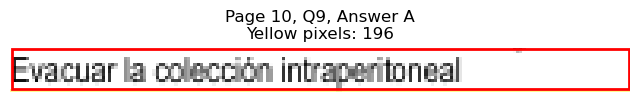

Page 10, Q9 - B: Detected box: x0=68.3, y0=720.6, x1=282.2, y1=733.2
Page 10, Q9, B: Yellow pixels: 2163
Page 10, Q9, B: Total non-white pixels: 3064
Page 10, Q9, B: Yellow percentage: 70.6%


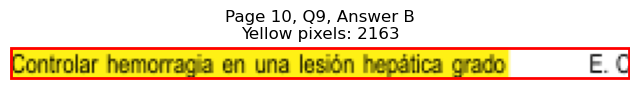

Page 10, Q9 - C: Detected box: x0=68.8, y0=745.8, x1=200.8, y1=758.4
Page 10, Q9, C: Yellow pixels: 183
Page 10, Q9, C: Total non-white pixels: 847
Page 10, Q9, C: Yellow percentage: 21.6%


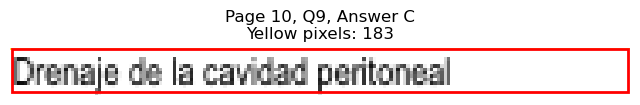

Page 10, Q9 - D: Detected box: x0=327.5, y0=708.0, x1=523.2, y1=720.6
Page 10, Q9, D: Yellow pixels: 0
Page 10, Q9, D: Total non-white pixels: 945
Page 10, Q9, D: Yellow percentage: 0.0%


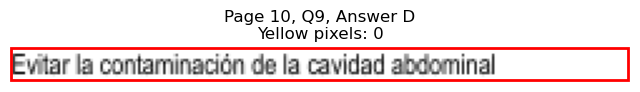

Page 10, Q9 - E: Detected box: x0=327.0, y0=720.6, x1=531.7, y1=733.2
Page 10, Q9, E: Yellow pixels: 0
Page 10, Q9, E: Total non-white pixels: 974
Page 10, Q9, E: Yellow percentage: 0.0%


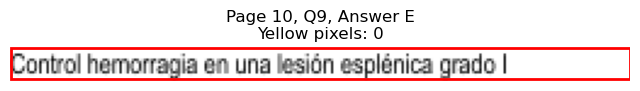


Page 10, Q9 - Selected Answer: B (based on yellow pixel count)





Page 11: Found 9 questions
Page 11, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=113.4, y1=102.1
Page 11, Q1, A: Yellow pixels: 0
Page 11, Q1, A: Total non-white pixels: 230
Page 11, Q1, A: Yellow percentage: 0.0%


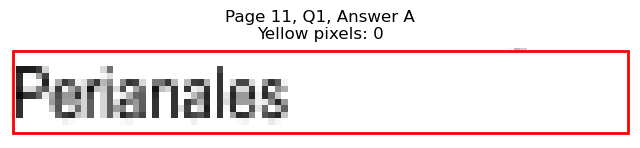

Page 11, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=139.0, y1=114.7
Page 11, Q1, B: Yellow pixels: 0
Page 11, Q1, B: Total non-white pixels: 377
Page 11, Q1, B: Yellow percentage: 0.0%


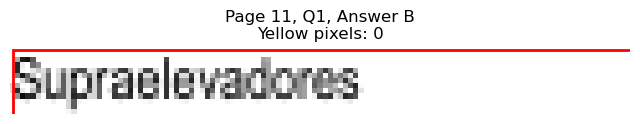

Page 11, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=140.5, y1=127.3
Page 11, Q1, C: Yellow pixels: 0
Page 11, Q1, C: Total non-white pixels: 371
Page 11, Q1, C: Yellow percentage: 0.0%


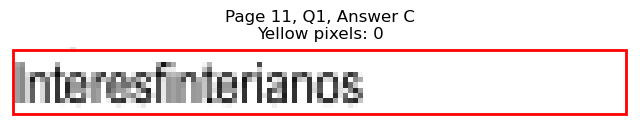

Page 11, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=404.2, y1=102.1
Page 11, Q1, D: Yellow pixels: 128
Page 11, Q1, D: Total non-white pixels: 532
Page 11, Q1, D: Yellow percentage: 24.1%


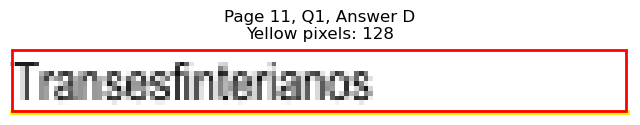

Page 11, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=388.3, y1=114.7
Page 11, Q1, E: Yellow pixels: 1188
Page 11, Q1, E: Total non-white pixels: 1456
Page 11, Q1, E: Yellow percentage: 81.6%


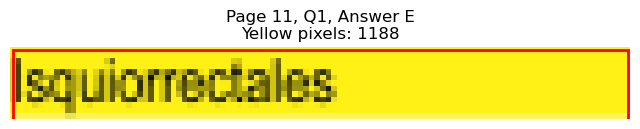


Page 11, Q1 - Selected Answer: E (based on yellow pixel count)




Page 11, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=166.6, y1=177.8
Page 11, Q2, A: Yellow pixels: 1563
Page 11, Q2, A: Total non-white pixels: 1937
Page 11, Q2, A: Yellow percentage: 80.7%


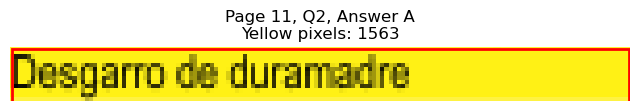

Page 11, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=132.5, y1=190.4
Page 11, Q2, B: Yellow pixels: 113
Page 11, Q2, B: Total non-white pixels: 456
Page 11, Q2, B: Yellow percentage: 24.8%


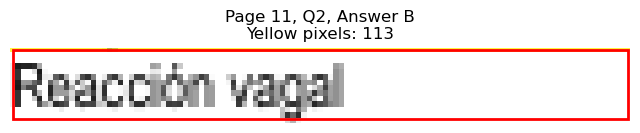

Page 11, Q2 - C: Detected box: x0=68.8, y0=190.3, x1=201.5, y1=203.0
Page 11, Q2, C: Yellow pixels: 0
Page 11, Q2, C: Total non-white pixels: 646
Page 11, Q2, C: Yellow percentage: 0.0%


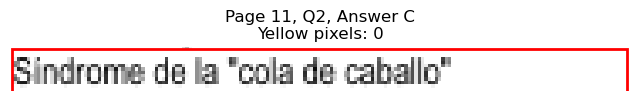

Page 11, Q2 - D: Detected box: x0=327.5, y0=165.1, x1=418.9, y1=177.8
Page 11, Q2, D: Yellow pixels: 0
Page 11, Q2, D: Total non-white pixels: 494
Page 11, Q2, D: Yellow percentage: 0.0%


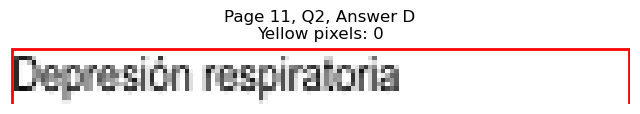

Page 11, Q2 - E: Detected box: x0=327.0, y0=177.7, x1=402.3, y1=190.4
Page 11, Q2, E: Yellow pixels: 0
Page 11, Q2, E: Total non-white pixels: 392
Page 11, Q2, E: Yellow percentage: 0.0%


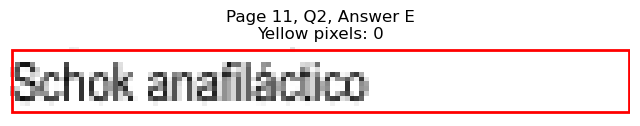


Page 11, Q2 - Selected Answer: A (based on yellow pixel count)




Page 11, Q3 - A: Detected box: x0=68.3, y0=228.3, x1=204.3, y1=240.9
Page 11, Q3, A: Yellow pixels: 0
Page 11, Q3, A: Total non-white pixels: 673
Page 11, Q3, A: Yellow percentage: 0.0%


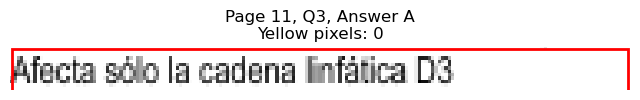

Page 11, Q3 - B: Detected box: x0=68.3, y0=240.9, x1=224.8, y1=253.5
Page 11, Q3, B: Yellow pixels: 0
Page 11, Q3, B: Total non-white pixels: 768
Page 11, Q3, B: Yellow percentage: 0.0%


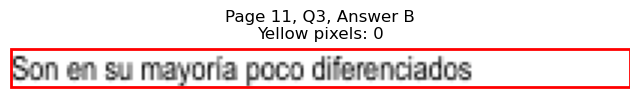

Page 11, Q3 - C: Detected box: x0=68.8, y0=253.5, x1=195.3, y1=266.1
Page 11, Q3, C: Yellow pixels: 0
Page 11, Q3, C: Total non-white pixels: 631
Page 11, Q3, C: Yellow percentage: 0.0%


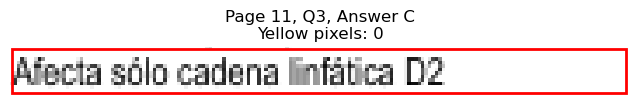

Page 11, Q3 - D: Detected box: x0=327.5, y0=228.3, x1=444.4, y1=240.9
Page 11, Q3, D: Yellow pixels: 0
Page 11, Q3, D: Total non-white pixels: 740
Page 11, Q3, D: Yellow percentage: 0.0%


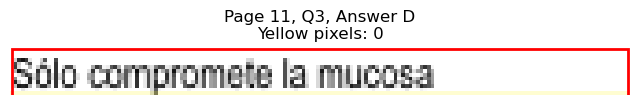

Page 11, Q3 - E: Detected box: x0=327.0, y0=240.9, x1=483.1, y1=253.5
Page 11, Q3, E: Yellow pixels: 2077
Page 11, Q3, E: Total non-white pixels: 2898
Page 11, Q3, E: Yellow percentage: 71.7%


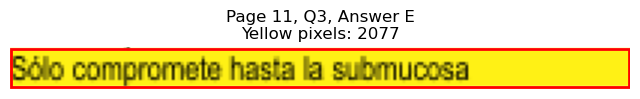


Page 11, Q3 - Selected Answer: E (based on yellow pixel count)




Page 11, Q4 - A: Detected box: x0=68.3, y0=316.6, x1=210.2, y1=329.3
Page 11, Q4, A: Yellow pixels: 0
Page 11, Q4, A: Total non-white pixels: 687
Page 11, Q4, A: Yellow percentage: 0.0%


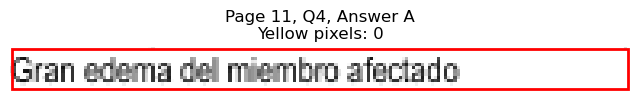

Page 11, Q4 - B: Detected box: x0=68.3, y0=329.2, x1=160.6, y1=341.9
Page 11, Q4, B: Yellow pixels: 0
Page 11, Q4, B: Total non-white pixels: 459
Page 11, Q4, B: Yellow percentage: 0.0%


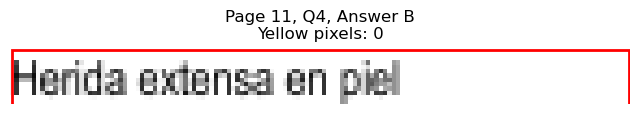

Page 11, Q4 - C: Detected box: x0=68.8, y0=341.9, x1=162.7, y1=354.6
Page 11, Q4, C: Yellow pixels: 0
Page 11, Q4, C: Total non-white pixels: 489
Page 11, Q4, C: Yellow percentage: 0.0%


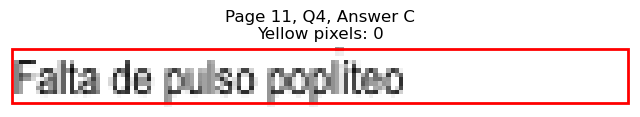

Page 11, Q4 - D: Detected box: x0=327.5, y0=316.6, x1=436.4, y1=329.3
Page 11, Q4, D: Yellow pixels: 1497
Page 11, Q4, D: Total non-white pixels: 2240
Page 11, Q4, D: Yellow percentage: 66.8%


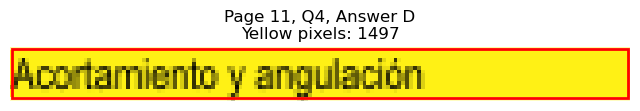

Page 11, Q4 - E: Detected box: x0=327.0, y0=329.2, x1=398.3, y1=341.9
Page 11, Q4, E: Yellow pixels: 0
Page 11, Q4, E: Total non-white pixels: 501
Page 11, Q4, E: Yellow percentage: 0.0%


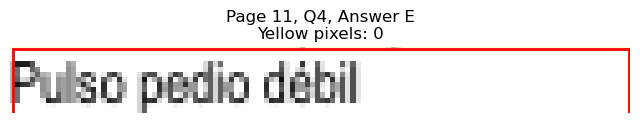


Page 11, Q4 - Selected Answer: D (based on yellow pixel count)




Page 11, Q5 - A: Detected box: x0=68.3, y0=392.3, x1=175.7, y1=405.0
Page 11, Q5, A: Yellow pixels: 0
Page 11, Q5, A: Total non-white pixels: 523
Page 11, Q5, A: Yellow percentage: 0.0%


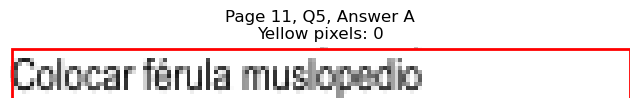

Page 11, Q5 - B: Detected box: x0=68.3, y0=404.9, x1=249.5, y1=417.6
Page 11, Q5, B: Yellow pixels: 0
Page 11, Q5, B: Total non-white pixels: 894
Page 11, Q5, B: Yellow percentage: 0.0%


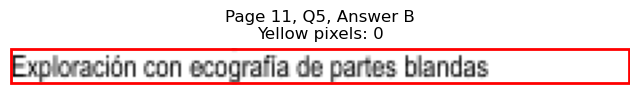

Page 11, Q5 - C: Detected box: x0=68.8, y0=417.6, x1=225.4, y1=430.3
Page 11, Q5, C: Yellow pixels: 1884
Page 11, Q5, C: Total non-white pixels: 2912
Page 11, Q5, C: Yellow percentage: 64.7%


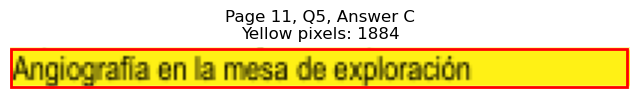

Page 11, Q5 - D: Detected box: x0=327.5, y0=392.3, x1=486.7, y1=405.0
Page 11, Q5, D: Yellow pixels: 0
Page 11, Q5, D: Total non-white pixels: 763
Page 11, Q5, D: Yellow percentage: 0.0%


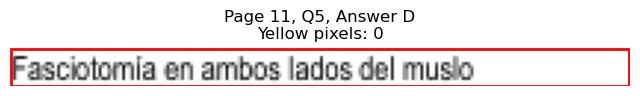

Page 11, Q5 - E: Detected box: x0=327.0, y0=404.9, x1=507.7, y1=417.6
Page 11, Q5, E: Yellow pixels: 0
Page 11, Q5, E: Total non-white pixels: 932
Page 11, Q5, E: Yellow percentage: 0.0%


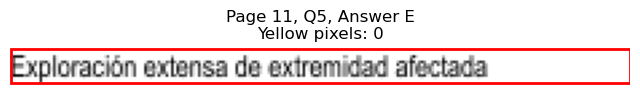


Page 11, Q5 - Selected Answer: C (based on yellow pixel count)




Page 11, Q6 - A: Detected box: x0=68.3, y0=455.5, x1=180.3, y1=468.1
Page 11, Q6, A: Yellow pixels: 0
Page 11, Q6, A: Total non-white pixels: 575
Page 11, Q6, A: Yellow percentage: 0.0%


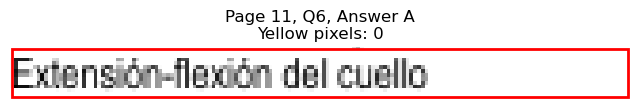

Page 11, Q6 - B: Detected box: x0=68.3, y0=468.1, x1=186.1, y1=480.7
Page 11, Q6, B: Yellow pixels: 0
Page 11, Q6, B: Total non-white pixels: 534
Page 11, Q6, B: Yellow percentage: 0.0%


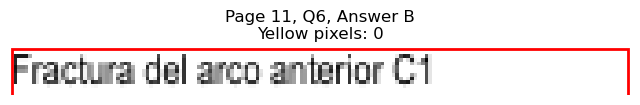

Page 11, Q6 - C: Detected box: x0=68.8, y0=480.8, x1=188.2, y1=493.4
Page 11, Q6, C: Yellow pixels: 0
Page 11, Q6, C: Total non-white pixels: 592
Page 11, Q6, C: Yellow percentage: 0.0%


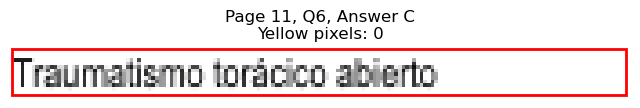

Page 11, Q6 - D: Detected box: x0=327.5, y0=455.5, x1=460.0, y1=468.1
Page 11, Q6, D: Yellow pixels: 1838
Page 11, Q6, D: Total non-white pixels: 2576
Page 11, Q6, D: Yellow percentage: 71.4%


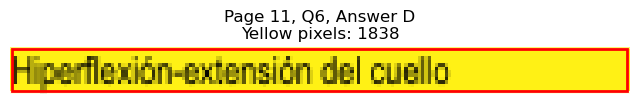

Page 11, Q6 - E: Detected box: x0=327.0, y0=468.1, x1=442.4, y1=480.7
Page 11, Q6, E: Yellow pixels: 0
Page 11, Q6, E: Total non-white pixels: 707
Page 11, Q6, E: Yellow percentage: 0.0%


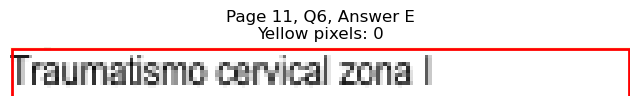


Page 11, Q6 - Selected Answer: D (based on yellow pixel count)




Page 11, Q7 - A: Detected box: x0=68.3, y0=518.6, x1=184.7, y1=531.2
Page 11, Q7, A: Yellow pixels: 167
Page 11, Q7, A: Total non-white pixels: 759
Page 11, Q7, A: Yellow percentage: 22.0%


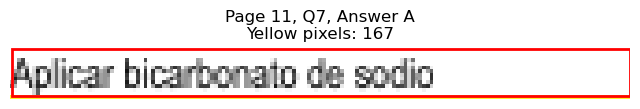

Page 11, Q7 - B: Detected box: x0=68.3, y0=531.2, x1=182.2, y1=543.8
Page 11, Q7, B: Yellow pixels: 1681
Page 11, Q7, B: Total non-white pixels: 2145
Page 11, Q7, B: Yellow percentage: 78.4%


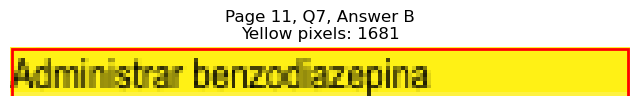

Page 11, Q7 - C: Detected box: x0=68.8, y0=543.8, x1=152.7, y1=556.4
Page 11, Q7, C: Yellow pixels: 134
Page 11, Q7, C: Total non-white pixels: 528
Page 11, Q7, C: Yellow percentage: 25.4%


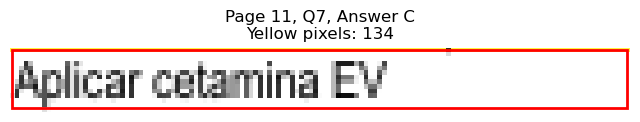

Page 11, Q7 - D: Detected box: x0=327.5, y0=518.6, x1=416.3, y1=531.2
Page 11, Q7, D: Yellow pixels: 0
Page 11, Q7, D: Total non-white pixels: 467
Page 11, Q7, D: Yellow percentage: 0.0%


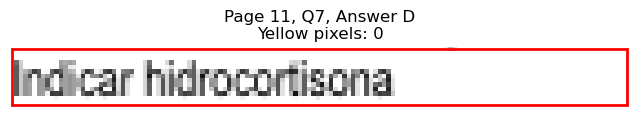

Page 11, Q7 - E: Detected box: x0=327.0, y0=531.2, x1=419.8, y1=543.8
Page 11, Q7, E: Yellow pixels: 0
Page 11, Q7, E: Total non-white pixels: 479
Page 11, Q7, E: Yellow percentage: 0.0%


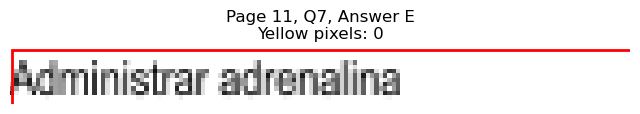


Page 11, Q7 - Selected Answer: B (based on yellow pixel count)




Page 11, Q8 - A: Detected box: x0=68.3, y0=606.9, x1=142.1, y1=619.6
Page 11, Q8, A: Yellow pixels: 0
Page 11, Q8, A: Total non-white pixels: 379
Page 11, Q8, A: Yellow percentage: 0.0%


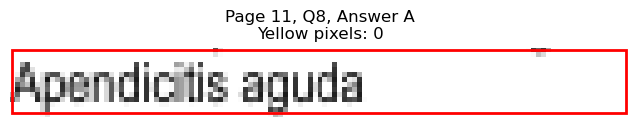

Page 11, Q8 - B: Detected box: x0=68.3, y0=619.6, x1=124.1, y1=632.3
Page 11, Q8, B: Yellow pixels: 0
Page 11, Q8, B: Total non-white pixels: 254
Page 11, Q8, B: Yellow percentage: 0.0%


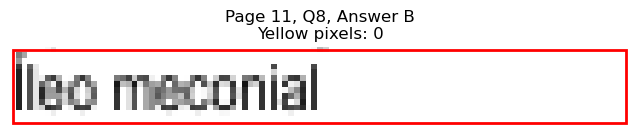

Page 11, Q8 - C: Detected box: x0=68.8, y0=632.2, x1=186.7, y1=644.9
Page 11, Q8, C: Yellow pixels: 0
Page 11, Q8, C: Total non-white pixels: 583
Page 11, Q8, C: Yellow percentage: 0.0%


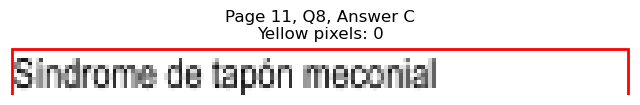

Page 11, Q8 - D: Detected box: x0=327.5, y0=606.9, x1=390.3, y1=619.6
Page 11, Q8, D: Yellow pixels: 1231
Page 11, Q8, D: Total non-white pixels: 1596
Page 11, Q8, D: Yellow percentage: 77.1%


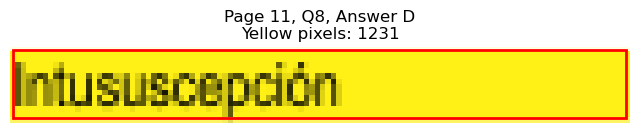

Page 11, Q8 - E: Detected box: x0=327.0, y0=619.6, x1=434.9, y1=632.3
Page 11, Q8, E: Yellow pixels: 158
Page 11, Q8, E: Total non-white pixels: 711
Page 11, Q8, E: Yellow percentage: 22.2%


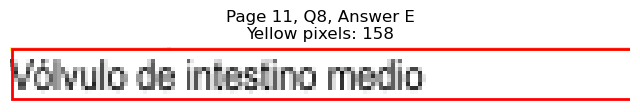


Page 11, Q8 - Selected Answer: D (based on yellow pixel count)




Page 11, Q9 - A: Detected box: x0=68.3, y0=682.7, x1=206.0, y1=695.3
Page 11, Q9, A: Yellow pixels: 0
Page 11, Q9, A: Total non-white pixels: 671
Page 11, Q9, A: Yellow percentage: 0.0%


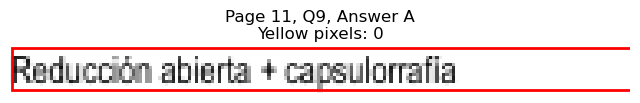

Page 11, Q9 - B: Detected box: x0=68.3, y0=695.4, x1=226.6, y1=708.0
Page 11, Q9, B: Yellow pixels: 209
Page 11, Q9, B: Total non-white pixels: 1243
Page 11, Q9, B: Yellow percentage: 16.8%


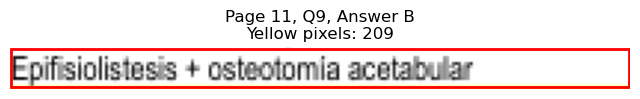

Page 11, Q9 - C: Detected box: x0=68.8, y0=708.0, x1=260.7, y1=720.6
Page 11, Q9, C: Yellow pixels: 2049
Page 11, Q9, C: Total non-white pixels: 2996
Page 11, Q9, C: Yellow percentage: 68.4%


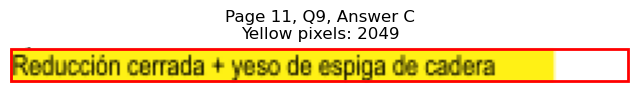

Page 11, Q9 - D: Detected box: x0=327.5, y0=682.7, x1=418.6, y1=695.3
Page 11, Q9, D: Yellow pixels: 0
Page 11, Q9, D: Total non-white pixels: 450
Page 11, Q9, D: Yellow percentage: 0.0%


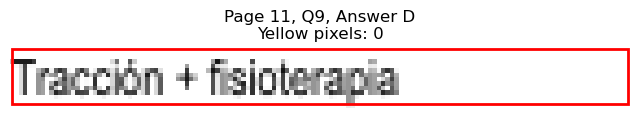

Page 11, Q9 - E: Detected box: x0=327.0, y0=695.4, x1=498.4, y1=708.0
Page 11, Q9, E: Yellow pixels: 0
Page 11, Q9, E: Total non-white pixels: 869
Page 11, Q9, E: Yellow percentage: 0.0%


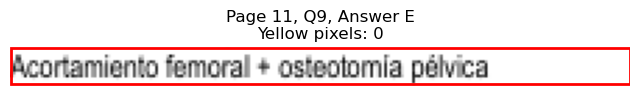


Page 11, Q9 - Selected Answer: C (based on yellow pixel count)





Page 12: Found 7 questions
Page 12, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=183.0, y1=102.1
Page 12, Q1, A: Yellow pixels: 0
Page 12, Q1, A: Total non-white pixels: 565
Page 12, Q1, A: Yellow percentage: 0.0%


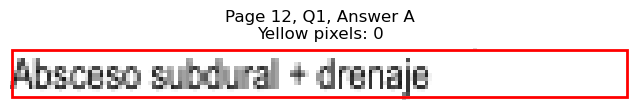

Page 12, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=162.4, y1=114.7
Page 12, Q1, B: Yellow pixels: 0
Page 12, Q1, B: Total non-white pixels: 628
Page 12, Q1, B: Yellow percentage: 0.0%


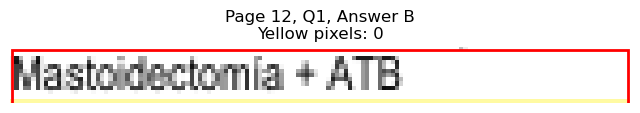

Page 12, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=195.4, y1=127.3
Page 12, Q1, C: Yellow pixels: 1648
Page 12, Q1, C: Total non-white pixels: 2492
Page 12, Q1, C: Yellow percentage: 66.1%


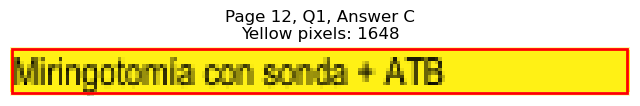

Page 12, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=426.1, y1=102.1
Page 12, Q1, D: Yellow pixels: 0
Page 12, Q1, D: Total non-white pixels: 492
Page 12, Q1, D: Yellow percentage: 0.0%


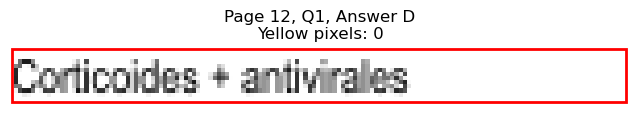

Page 12, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=443.2, y1=114.7
Page 12, Q1, E: Yellow pixels: 0
Page 12, Q1, E: Total non-white pixels: 558
Page 12, Q1, E: Yellow percentage: 0.0%


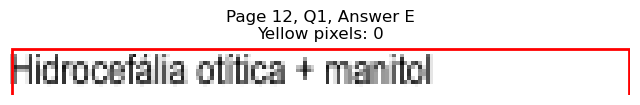


Page 12, Q1 - Selected Answer: C (based on yellow pixel count)




Page 12, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=127.5, y1=177.8
Page 12, Q2, A: Yellow pixels: 0
Page 12, Q2, A: Total non-white pixels: 293
Page 12, Q2, A: Yellow percentage: 0.0%


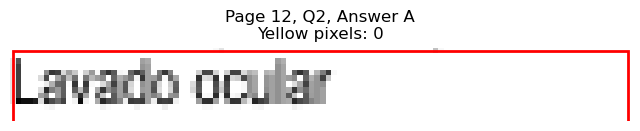

Page 12, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=141.5, y1=190.4
Page 12, Q2, B: Yellow pixels: 0
Page 12, Q2, B: Total non-white pixels: 336
Page 12, Q2, B: Yellow percentage: 0.0%


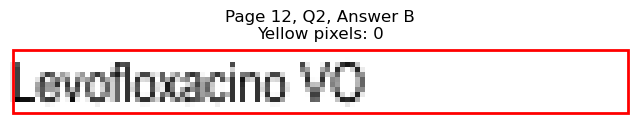

Page 12, Q2 - C: Detected box: x0=68.8, y0=190.3, x1=195.3, y1=203.0
Page 12, Q2, C: Yellow pixels: 0
Page 12, Q2, C: Total non-white pixels: 598
Page 12, Q2, C: Yellow percentage: 0.0%


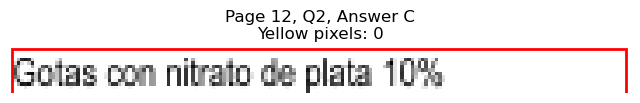

Page 12, Q2 - D: Detected box: x0=327.5, y0=165.1, x1=415.9, y1=177.8
Page 12, Q2, D: Yellow pixels: 1492
Page 12, Q2, D: Total non-white pixels: 1807
Page 12, Q2, D: Yellow percentage: 82.6%


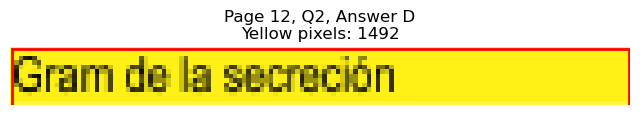

Page 12, Q2 - E: Detected box: x0=327.0, y0=177.7, x1=402.8, y1=190.4
Page 12, Q2, E: Yellow pixels: 126
Page 12, Q2, E: Total non-white pixels: 481
Page 12, Q2, E: Yellow percentage: 26.2%


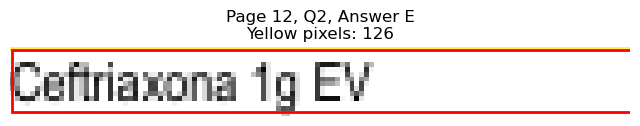


Page 12, Q2 - Selected Answer: D (based on yellow pixel count)




Page 12, Q3 - A: Detected box: x0=56.6, y0=253.5, x1=65.2, y1=266.1
Page 12, Q3, A: Yellow pixels: 0
Page 12, Q3, A: Total non-white pixels: 71
Page 12, Q3, A: Yellow percentage: 0.0%


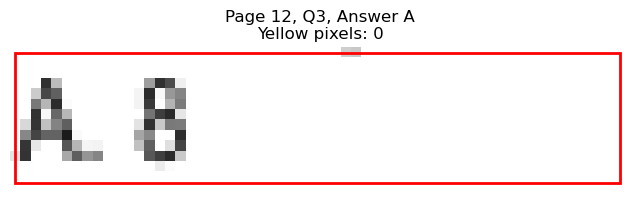

Page 12, Q3 - B: Detected box: x0=68.3, y0=266.1, x1=80.9, y1=278.7
Page 12, Q3, B: Yellow pixels: 0
Page 12, Q3, B: Total non-white pixels: 45
Page 12, Q3, B: Yellow percentage: 0.0%


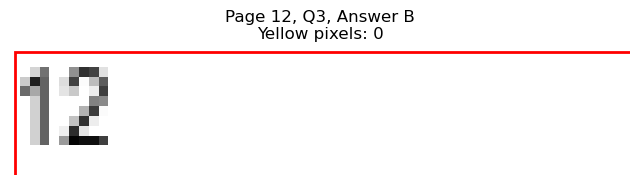

Page 12, Q3 - C: Detected box: x0=56.6, y0=278.8, x1=65.6, y1=291.5
Page 12, Q3, C: Yellow pixels: 0
Page 12, Q3, C: Total non-white pixels: 72
Page 12, Q3, C: Yellow percentage: 0.0%


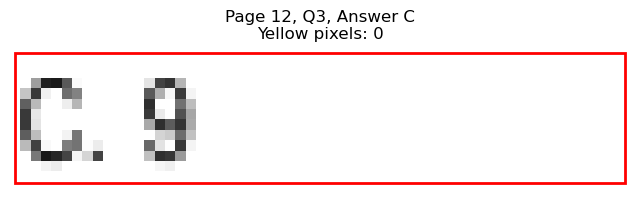

Page 12, Q3 - D: Detected box: x0=327.5, y0=253.5, x1=340.1, y1=266.1
Page 12, Q3, D: Yellow pixels: 801
Page 12, Q3, D: Total non-white pixels: 896
Page 12, Q3, D: Yellow percentage: 89.4%


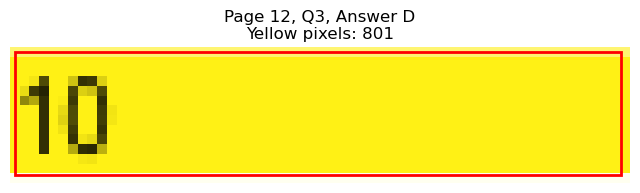

Page 12, Q3 - E: Detected box: x0=327.0, y0=266.1, x1=339.7, y1=278.7
Page 12, Q3, E: Yellow pixels: 0
Page 12, Q3, E: Total non-white pixels: 112
Page 12, Q3, E: Yellow percentage: 0.0%


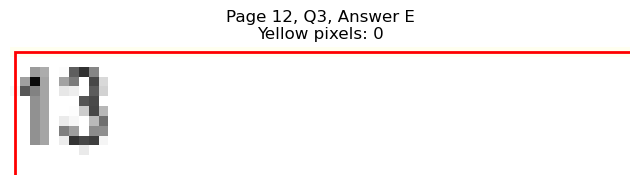


Page 12, Q3 - Selected Answer: D (based on yellow pixel count)




Page 12, Q4 - A: Detected box: x0=68.3, y0=341.9, x1=120.5, y1=354.6
Page 12, Q4, A: Yellow pixels: 0
Page 12, Q4, A: Total non-white pixels: 291
Page 12, Q4, A: Yellow percentage: 0.0%


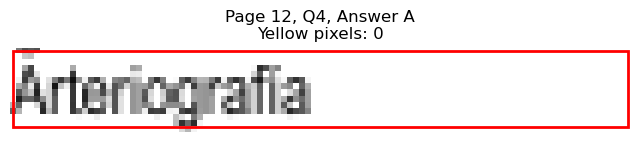

Page 12, Q4 - B: Detected box: x0=68.3, y0=354.5, x1=116.9, y1=367.2
Page 12, Q4, B: Yellow pixels: 99
Page 12, Q4, B: Total non-white pixels: 333
Page 12, Q4, B: Yellow percentage: 29.7%


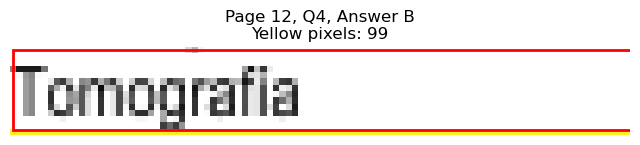

Page 12, Q4 - C: Detected box: x0=68.8, y0=367.1, x1=121.0, y1=379.8
Page 12, Q4, C: Yellow pixels: 1150
Page 12, Q4, C: Total non-white pixels: 1339
Page 12, Q4, C: Yellow percentage: 85.9%


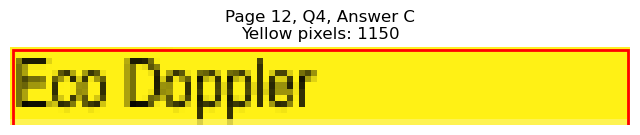

Page 12, Q4 - D: Detected box: x0=327.5, y0=341.9, x1=385.3, y1=354.6
Page 12, Q4, D: Yellow pixels: 0
Page 12, Q4, D: Total non-white pixels: 295
Page 12, Q4, D: Yellow percentage: 0.0%


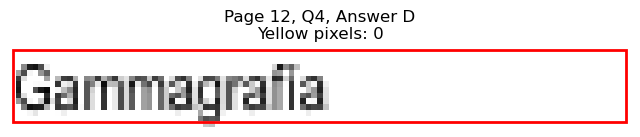

Page 12, Q4 - E: Detected box: x0=327.0, y0=354.5, x1=421.4, y1=367.2
Page 12, Q4, E: Yellow pixels: 0
Page 12, Q4, E: Total non-white pixels: 512
Page 12, Q4, E: Yellow percentage: 0.0%


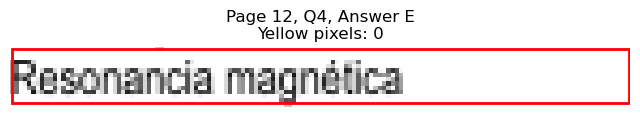


Page 12, Q4 - Selected Answer: C (based on yellow pixel count)




Page 12, Q5 - A: Detected box: x0=68.3, y0=430.2, x1=161.1, y1=442.9
Page 12, Q5, A: Yellow pixels: 0
Page 12, Q5, A: Total non-white pixels: 482
Page 12, Q5, A: Yellow percentage: 0.0%


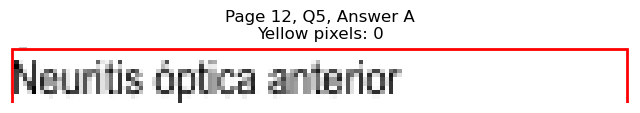

Page 12, Q5 - B: Detected box: x0=68.3, y0=442.8, x1=176.7, y1=455.5
Page 12, Q5, B: Yellow pixels: 0
Page 12, Q5, B: Total non-white pixels: 544
Page 12, Q5, B: Yellow percentage: 0.0%


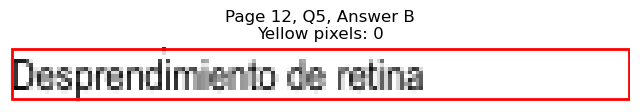

Page 12, Q5 - C: Detected box: x0=68.8, y0=455.5, x1=212.2, y1=468.1
Page 12, Q5, C: Yellow pixels: 0
Page 12, Q5, C: Total non-white pixels: 707
Page 12, Q5, C: Yellow percentage: 0.0%


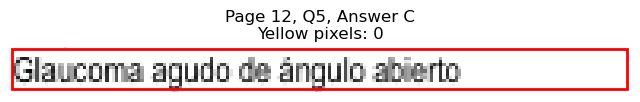

Page 12, Q5 - D: Detected box: x0=327.5, y0=430.2, x1=418.3, y1=442.9
Page 12, Q5, D: Yellow pixels: 0
Page 12, Q5, D: Total non-white pixels: 615
Page 12, Q5, D: Yellow percentage: 0.0%


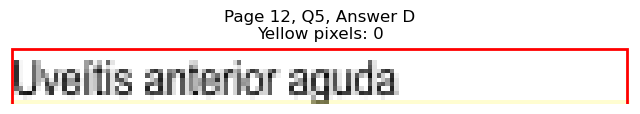

Page 12, Q5 - E: Detected box: x0=327.0, y0=442.8, x1=473.5, y1=455.5
Page 12, Q5, E: Yellow pixels: 1975
Page 12, Q5, E: Total non-white pixels: 2758
Page 12, Q5, E: Yellow percentage: 71.6%


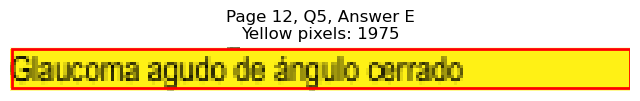


Page 12, Q5 - Selected Answer: E (based on yellow pixel count)




Page 12, Q6 - A: Detected box: x0=68.3, y0=518.6, x1=214.5, y1=531.2
Page 12, Q6, A: Yellow pixels: 0
Page 12, Q6, A: Total non-white pixels: 719
Page 12, Q6, A: Yellow percentage: 0.0%


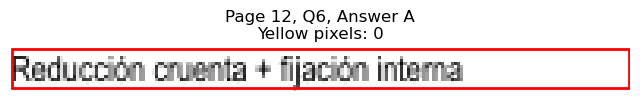

Page 12, Q6 - B: Detected box: x0=68.3, y0=531.2, x1=231.5, y1=543.8
Page 12, Q6, B: Yellow pixels: 0
Page 12, Q6, B: Total non-white pixels: 744
Page 12, Q6, B: Yellow percentage: 0.0%


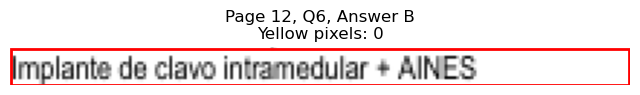

Page 12, Q6 - C: Detected box: x0=68.8, y0=543.8, x1=185.4, y1=556.4
Page 12, Q6, C: Yellow pixels: 0
Page 12, Q6, C: Total non-white pixels: 546
Page 12, Q6, C: Yellow percentage: 0.0%


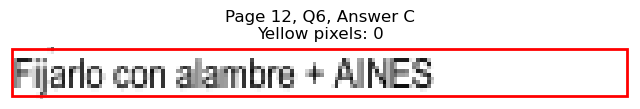

Page 12, Q6 - D: Detected box: x0=327.5, y0=518.6, x1=430.7, y1=531.2
Page 12, Q6, D: Yellow pixels: 1581
Page 12, Q6, D: Total non-white pixels: 2156
Page 12, Q6, D: Yellow percentage: 73.3%


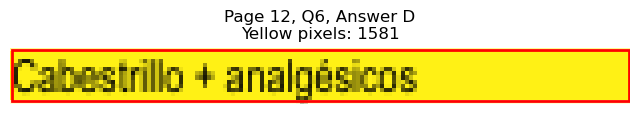

Page 12, Q6 - E: Detected box: x0=327.0, y0=531.2, x1=497.0, y1=543.8
Page 12, Q6, E: Yellow pixels: 0
Page 12, Q6, E: Total non-white pixels: 1056
Page 12, Q6, E: Yellow percentage: 0.0%


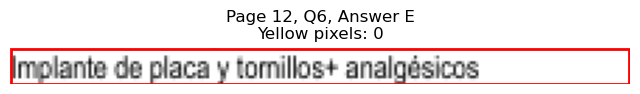


Page 12, Q6 - Selected Answer: D (based on yellow pixel count)




Page 12, Q7 - A: Detected box: x0=68.3, y0=606.9, x1=190.8, y1=619.6
Page 12, Q7, A: Yellow pixels: 0
Page 12, Q7, A: Total non-white pixels: 615
Page 12, Q7, A: Yellow percentage: 0.0%


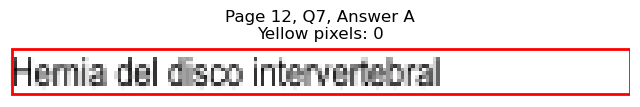

Page 12, Q7 - B: Detected box: x0=68.3, y0=619.6, x1=156.6, y1=632.3
Page 12, Q7, B: Yellow pixels: 0
Page 12, Q7, B: Total non-white pixels: 428
Page 12, Q7, B: Yellow percentage: 0.0%


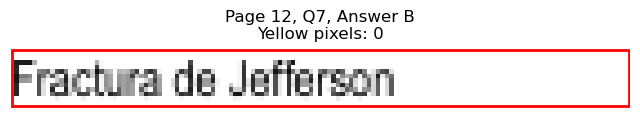

Page 12, Q7 - C: Detected box: x0=68.8, y0=632.2, x1=175.2, y1=644.9
Page 12, Q7, C: Yellow pixels: 0
Page 12, Q7, C: Total non-white pixels: 519
Page 12, Q7, C: Yellow percentage: 0.0%


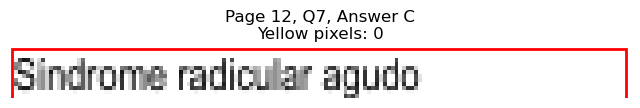

Page 12, Q7 - D: Detected box: x0=327.5, y0=606.9, x1=410.3, y1=619.6
Page 12, Q7, D: Yellow pixels: 0
Page 12, Q7, D: Total non-white pixels: 399
Page 12, Q7, D: Yellow percentage: 0.0%


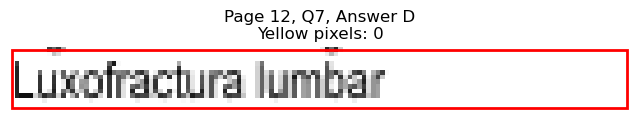

Page 12, Q7 - E: Detected box: x0=327.0, y0=619.6, x1=406.9, y1=632.3
Page 12, Q7, E: Yellow pixels: 1263
Page 12, Q7, E: Total non-white pixels: 1820
Page 12, Q7, E: Yellow percentage: 69.4%


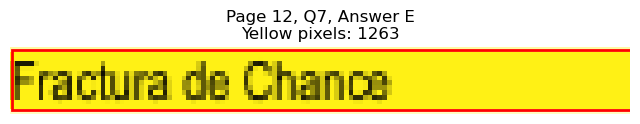


Page 12, Q7 - Selected Answer: E (based on yellow pixel count)






In [6]:
questions_df = extract_questions(pdf_path = pdf_file)
answers_df = extract_answers(pdf_path = pdf_file)
correct_answers_df = extract_correct_answers(pdf_path = pdf_file)

In [7]:
questions_df

,question
0,En el Síndrome de hipertensión endocraneana de...
1,Varón de 23 años es trasladado al servicio de ...
2,¿Cuál es el cuadro que se produce cuando la pe...
3,"Varón de 45 años, hace 2 horas sufre agresión ..."
4,"RN varón, presenta vómitos no biliosos “en pro..."
...,...
95,"Mujer de 28 años, sufre agresión con objeto co..."
96,"Adolescente de 14 años, hace 30 minutos presen..."
97,"Mujer de 55 años, hipermétrope, con dolor inte..."
98,Varón de 25 años que tropieza y cae sobre el h...


In [8]:
answers_df

,option_A,option_B,option_C,option_D,option_E
0,Midriáticas,Normales,Pequeñas hiporreactivas,Intermedias arreactivas,Pequeñas hiperreactivas
1,Oxigenoterapia 4 l/mín,Hidrocortisona 0.25 mg,Metilprednisolona 25 mg/Kg,Aperturar vía venosa central,Intubación endotraqueal
2,Miocardiopatía grave,Vasculopatía pulmonar irreversible,Insuficiencia valvular,Insuficiencia cardiaca derecha,Estenosis valvular
3,Lesión axonal difusa,Hematoma epidural,Cordón posterior,Cordón central,Cordón lateral
4,Estenosis pilórica hipertrófica,Atresia yeyunal,Intususcepción,Duplicación intestinal,Estenosis duodenal
...,...,...,...,...,...
95,8,12,9,10,13
96,Arteriografía,Tomografía,Eco Doppler,Gammagrafía,Resonancia magnética
97,Neuritis óptica anterior,Desprendimiento de retina,Glaucoma agudo de ángulo abierto,Uveítis anterior aguda,Glaucoma agudo de ángulo cerrado
98,Reducción cruenta + fijación interna,Implante de clavo intramedular + AINES,Fijarlo con alambre + AINES,Cabestrillo + analgésicos,Implante de placa y tornillos+ analgésicos


In [9]:
correct_answers_df

,correct_answer
0,C
1,E
2,B
3,E
4,A
...,...
95,D
96,C
97,E
98,D


In [10]:
total_df = pd.concat([questions_df, answers_df, correct_answers_df], ignore_index = True, axis = 1)
total_df.columns = ["questions", "option_A", "option_B", "option_C", "option_D", "option_E", "correct_answer"]
total_df

,questions,option_A,option_B,option_C,option_D,option_E,correct_answer
0,En el Síndrome de hipertensión endocraneana de...,Midriáticas,Normales,Pequeñas hiporreactivas,Intermedias arreactivas,Pequeñas hiperreactivas,C
1,Varón de 23 años es trasladado al servicio de ...,Oxigenoterapia 4 l/mín,Hidrocortisona 0.25 mg,Metilprednisolona 25 mg/Kg,Aperturar vía venosa central,Intubación endotraqueal,E
2,¿Cuál es el cuadro que se produce cuando la pe...,Miocardiopatía grave,Vasculopatía pulmonar irreversible,Insuficiencia valvular,Insuficiencia cardiaca derecha,Estenosis valvular,B
3,"Varón de 45 años, hace 2 horas sufre agresión ...",Lesión axonal difusa,Hematoma epidural,Cordón posterior,Cordón central,Cordón lateral,E
4,"RN varón, presenta vómitos no biliosos “en pro...",Estenosis pilórica hipertrófica,Atresia yeyunal,Intususcepción,Duplicación intestinal,Estenosis duodenal,A
...,...,...,...,...,...,...,...
95,"Mujer de 28 años, sufre agresión con objeto co...",8,12,9,10,13,D
96,"Adolescente de 14 años, hace 30 minutos presen...",Arteriografía,Tomografía,Eco Doppler,Gammagrafía,Resonancia magnética,C
97,"Mujer de 55 años, hipermétrope, con dolor inte...",Neuritis óptica anterior,Desprendimiento de retina,Glaucoma agudo de ángulo abierto,Uveítis anterior aguda,Glaucoma agudo de ángulo cerrado,E
98,Varón de 25 años que tropieza y cae sobre el h...,Reducción cruenta + fijación interna,Implante de clavo intramedular + AINES,Fijarlo con alambre + AINES,Cabestrillo + analgésicos,Implante de placa y tornillos+ analgésicos,D


In [11]:
# Extract folder path
folder_path = os.path.dirname(pdf_file)  # Gets the directory path

# Extract filename without extension
file_name = os.path.splitext(os.path.basename(pdf_file))[0]  # Removes the .pdf extension

# Create CSV file path
csv_file = os.path.join(folder_path, f"{file_name}.csv")

# Save a sample DataFrame
total_df.to_csv(csv_file, index=False, encoding="utf-8-sig")
print(f"CSV saved at: {csv_file}")


CSV saved at: /Users/rodrigocarrillo/Library/CloudStorage/OneDrive-EmoryUniversity/Natural Language Processing Projects/Examen Residentado Peru/CONAREME/Year2022/Cirugía General.csv
